# Semantic Similarity Data Vs Author

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 83.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings

In [3]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [4]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [6]:
import tol_colors as tcls

In [7]:
import itertools as itlx
import json
from pathlib import Path
import re

In [8]:
from IPython.display import display, display_markdown

In [9]:
from pprint import pprint

In [10]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [11]:
pd.set_option('display.max_colwidth', None)

## Semantic Similarity

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [13]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [14]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

In [15]:
%%sql
CREATE TABLE IF NOT EXISTS cons_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--cons_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,5934


In [16]:
%%sql
CREATE TABLE IF NOT EXISTS gt_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--gt_node_info_groups.csv';

-- NB: gt_dwc_t_author_nodes == gt_dwc_t_data_nodes
CREATE TABLE IF NOT EXISTS gt_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--gt_node_info_groups.csv';

-- NB: gt_eml_data_nodes == gt_eml_author_nodes
CREATE TABLE IF NOT EXISTS gt_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--gt_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,53666


In [17]:
%%sql
SELECT 
    (SELECT COUNT(1) FROM cons_dwc_t_data_nodes) AS dwc_t_data_node_count,
    (SELECT COUNT(1) FROM cons_dwc_t_author_nodes) AS dwc_t_author_node_count,
    (SELECT COUNT(1) FROM cons_eml_data_nodes) AS eml_data_node_count,
    (SELECT COUNT(1) FROM cons_eml_author_nodes) AS eml_author_node_count;

Running query in 'duckdb'

,dwc_t_data_node_count,dwc_t_author_node_count,eml_data_node_count,eml_author_node_count
0,8552,8562,6369,5934


In [18]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes AS (
    SELECT  *,
            d.text as data_text, a.text as author_text,
            d.has_text as data_has_text, a.has_text as author_has_text,
            d.attributes as data_attributes, a.attributes as author_attributes,
            d.has_attributes as data_has_attributes, a.has_attributes as author_has_attributes
    FROM cons_dwc_t_data_nodes AS d
    JOIN cons_dwc_t_author_nodes AS a
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,8212


In [19]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes AS (
    SELECT  *,
            d.text as data_text, a.text as author_text,
            d.has_text as data_has_text, a.has_text as author_has_text,
            d.attributes as data_attributes, a.attributes as author_attributes,
            d.has_attributes as data_has_attributes, a.has_attributes as author_has_attributes
    FROM cons_eml_data_nodes AS d
    JOIN cons_eml_author_nodes AS a
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,3876


In [20]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_gt_eml_nodes AS (
    SELECT  *,
            d.text as data_text, a.text as gt_text,
            d.has_text as data_has_text, a.has_text as gt_has_text,
            d.attributes as data_attributes, a.attributes as gt_attributes,
            d.has_attributes as data_has_attributes, a.has_attributes as gt_has_attributes
    FROM cons_eml_data_nodes AS d
    JOIN gt_eml_data_nodes AS a
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,2844


In [21]:
%%sql
CREATE TABLE IF NOT EXISTS shared_author_gt_eml_nodes AS (
    SELECT  *,
            a.text as author_text, d.text as gt_text,
            a.has_text as author_has_text, d.has_text as gt_has_text,
            a.attributes as author_attributes, d.attributes as gt_attributes,
            a.has_attributes as author_has_attributes, d.has_attributes as gt_has_attributes
    FROM cons_eml_author_nodes AS a
    JOIN gt_eml_author_nodes AS d
        ON  a.path = d.path
        AND a.case_id = d.case_id
);

Running query in 'duckdb'

,Count
0,2760


#### Reporting Confusion Matrix

##### DwC-T

In [22]:
%%sql
SELECT COUNT(1), data_has_text, author_has_text
FROM shared_data_author_dwc_t_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_text,author_has_text
0,7954,False,False
1,258,True,True


In [23]:
%%sql
SELECT COUNT(1), data_has_attributes, author_has_attributes
FROM shared_data_author_dwc_t_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_attributes,author_has_attributes
0,516,False,False
1,7696,True,True


##### EML

In [24]:
%%sql
SELECT COUNT(1), data_has_text, author_has_text
FROM shared_data_author_eml_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_text,author_has_text
0,2226,False,False
1,21,True,False
2,1599,True,True
3,30,False,True


In [25]:
%%sql
SELECT COUNT(1), data_has_attributes, author_has_attributes
FROM shared_data_author_eml_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),data_has_attributes,author_has_attributes
0,3447,False,False
1,12,True,False
2,12,False,True
3,405,True,True


In [26]:
%%sql
SELECT c.path, c.tag, c.case_id, c.data_has_attributes, c.data_attributes, c.author_has_attributes, c.author_attributes
FROM shared_data_author_eml_nodes AS c
WHERE (data_has_attributes) AND (NOT author_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,data_has_attributes,data_attributes,author_has_attributes,author_attributes
0,additionalMetadata,additionalMetadata,100,True,"{""id"": ""am-1""}",False,{}
1,additionalMetadata,additionalMetadata,125,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,additionalMetadata,137,True,"{""id"": ""ext-1""}",False,{}
3,additionalMetadata,additionalMetadata,151,True,"{""id"": ""am-1""}",False,{}
4,dataset,dataset,169,True,"{""id"": ""203-37e24322-a8b9-3f3f-8686-4fa43445dc95""}",False,{}
5,additionalMetadata,additionalMetadata,21,True,"{""id"": ""customExtensions""}",False,{}
6,additionalMetadata,additionalMetadata,3,True,"{""id"": ""am-1""}",False,{}
7,additionalMetadata,additionalMetadata,45,True,"{""id"": ""amd-1""}",False,{}
8,additionalMetadata,additionalMetadata,5,True,"{""id"": ""am1""}",False,{}
9,additionalMetadata,additionalMetadata,6,True,"{""id"": ""am-1""}",False,{}


In [27]:
%%sql
SELECT c.path, c.tag, c.case_id, c.data_has_attributes, c.data_attributes, c.author_has_attributes, c.author_attributes
FROM shared_data_author_eml_nodes AS c
WHERE (NOT data_has_attributes) AND (author_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,data_has_attributes,data_attributes,author_has_attributes,author_attributes
0,dataset,dataset,112,False,{},True,"{""id"": ""aedes_collection_dataset""}"
1,additionalMetadata,additionalMetadata,115,False,{},True,"{""id"": ""am-1""}"
2,dataset,dataset,144,False,{},True,"{""id"": ""dataset-1""}"
3,additionalMetadata,additionalMetadata,144,False,{},True,"{""id"": ""am-1""}"
4,additionalMetadata,additionalMetadata,163,False,{},True,"{""id"": ""am-001""}"
5,additionalMetadata,additionalMetadata,169,False,{},True,"{""id"": ""addl-1""}"
6,additionalMetadata,additionalMetadata,34,False,{},True,"{""id"": ""am-1""}"
7,additionalMetadata,additionalMetadata,50,False,{},True,"{""id"": ""am-1""}"
8,additionalMetadata,additionalMetadata,51,False,{},True,"{""id"": ""customExtensions""}"
9,additionalMetadata,additionalMetadata,63,False,{},True,"{""id"": ""am-1""}"


### Computing Similarities

In [28]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [29]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1.0
    if not v1 or not v2:
        return None

    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [30]:
compute_cos_similarity("{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

1.0

In [31]:
conn.create_function("cos_sim", compute_cos_similarity)

In [32]:
%%time
shared_data_author_dwc_t_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_text AS (
SELECT
    case_id, path,
    data_text, author_text,
    cos_sim(data_text, author_text) AS cos_sim_text,
FROM shared_data_author_dwc_t_nodes
WHERE data_has_text AND author_has_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_text;
""").to_df()


shared_data_author_dwc_t_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes AS (
SELECT
    case_id, path,
    data_attributes, author_attributes,
    cos_sim(data_attributes, author_attributes) AS cos_sim_attributes,
FROM shared_data_author_dwc_t_nodes
WHERE data_has_attributes AND author_has_attributes
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 10.5 s, sys: 1.68 s, total: 12.2 s
Wall time: 17.5 s


In [33]:
%%time
shared_data_author_eml_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_text AS (
SELECT
    case_id, path,
    data_text, author_text,
    cos_sim(data_text, author_text) AS cos_sim_text,
FROM shared_data_author_eml_nodes
WHERE data_has_text AND author_has_text
);
SELECT * FROM shared_data_author_eml_nodes__sim_text;
""").to_df()


shared_data_author_eml_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_attributes AS (
SELECT
    case_id, path,
    data_attributes, author_attributes,
    cos_sim(data_attributes, author_attributes) AS cos_sim_attributes,
FROM shared_data_author_eml_nodes
WHERE data_has_attributes AND author_has_attributes
);
SELECT * FROM shared_data_author_eml_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 21.1 s, sys: 5.47 s, total: 26.6 s
Wall time: 19.4 s


In [37]:
%%time
shared_data_gt_eml_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_gt_eml_nodes__sim_text AS (
SELECT
    case_id, path,
    data_text, gt_text,
    cos_sim(data_text, gt_text) AS cos_sim_text,
FROM shared_data_gt_eml_nodes
WHERE data_has_text AND gt_has_text
);
SELECT * FROM shared_data_gt_eml_nodes__sim_text;
""").to_df()


shared_data_gt_eml_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_data_gt_eml_nodes__sim_attributes AS (
SELECT
    case_id, path,
    data_attributes, gt_attributes,
    cos_sim(data_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_data_gt_eml_nodes
WHERE data_has_attributes AND gt_has_attributes
);
SELECT * FROM shared_data_gt_eml_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 1.34 s, sys: 274 ms, total: 1.61 s
Wall time: 2.45 s


In [38]:
%%time
shared_author_gt_eml_nodes__sim_text = conn.query("""
CREATE TABLE IF NOT EXISTS shared_author_gt_eml_nodes__sim_text AS (
SELECT
    case_id, path,
    author_text, gt_text,
    cos_sim(author_text, gt_text) AS cos_sim_text,
FROM shared_author_gt_eml_nodes
WHERE author_has_text AND gt_has_text
);
SELECT * FROM shared_author_gt_eml_nodes__sim_text;
""").to_df()


shared_author_gt_eml_nodes__sim_attributes = conn.query("""
CREATE TABLE IF NOT EXISTS shared_author_gt_eml_nodes__sim_attributes AS (
SELECT
    case_id, path,
    author_attributes, gt_attributes,
    cos_sim(author_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_author_gt_eml_nodes
WHERE author_has_attributes AND gt_has_attributes
);
SELECT * FROM shared_author_gt_eml_nodes__sim_attributes;
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 7.18 s, sys: 1.38 s, total: 8.57 s
Wall time: 9.28 s


### Basic insights

#### DwC-T

In [39]:
%%sql
SELECT d.path, AVG(cos_sim_text), COUNT(1)   
FROM shared_data_author_dwc_t_nodes__sim_text AS d
GROUP BY 1
ORDER BY 2 DESC, 3 DESC;

Running query in 'duckdb'

,path,avg(cos_sim_text),count(1)
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.972965,169
1,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.934475,59
2,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.782424,14
3,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.760269,14
4,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,0.524897,2


In [40]:
%%sql
SELECT d.path, AVG(cos_sim_attributes), COUNT(1)   
FROM shared_data_author_dwc_t_nodes__sim_attributes AS d
GROUP BY 1
ORDER BY 2 DESC, 3 DESC;

Running query in 'duckdb'

,path,avg(cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[28],1.000000,95
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[58],1.000000,13
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[64],1.000000,11
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[65],1.000000,11
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[63],1.000000,11
...,...,...,...
308,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],0.705396,1
309,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[35],0.694667,1
310,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[32],0.682424,1
311,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field,0.655420,1


<Axes: ylabel='Frequency'>

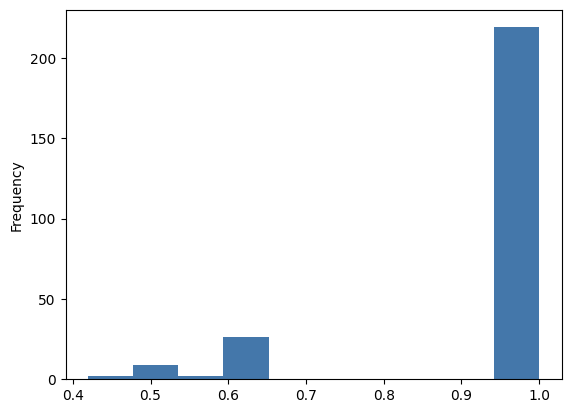

In [41]:
shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

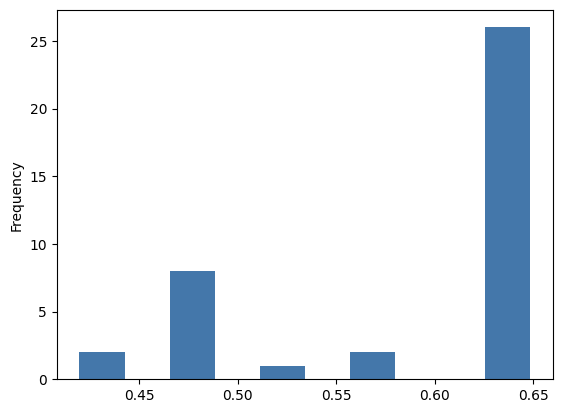

In [42]:
shared_data_author_dwc_t_nodes__sim_text[
    shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1
]["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

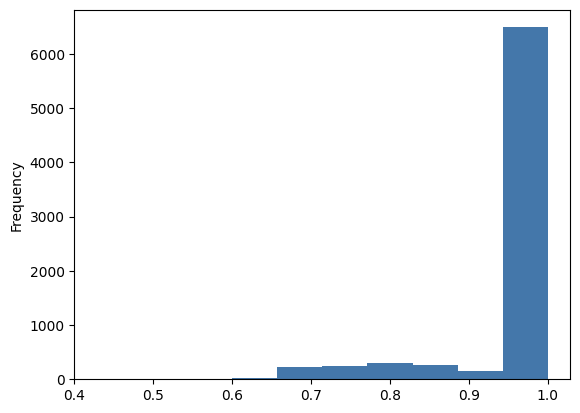

In [43]:
shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"].plot.hist()

<Axes: ylabel='Frequency'>

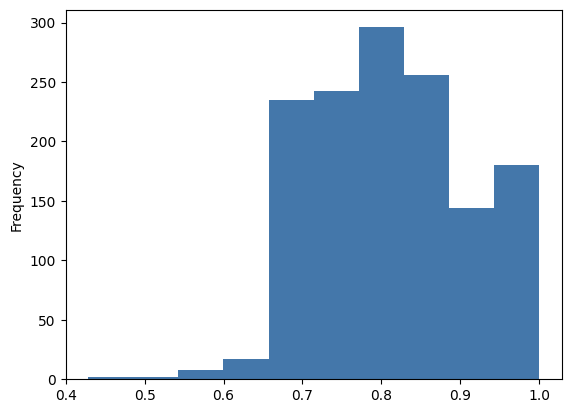

In [44]:
shared_data_author_dwc_t_nodes__sim_attributes[
    shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"] < 1
]["cos_sim_attributes"].plot.hist()

#### EML

<Axes: ylabel='Frequency'>

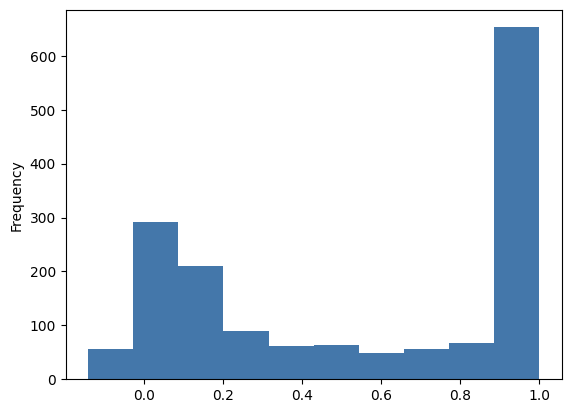

In [45]:
shared_data_author_eml_nodes__sim_text["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

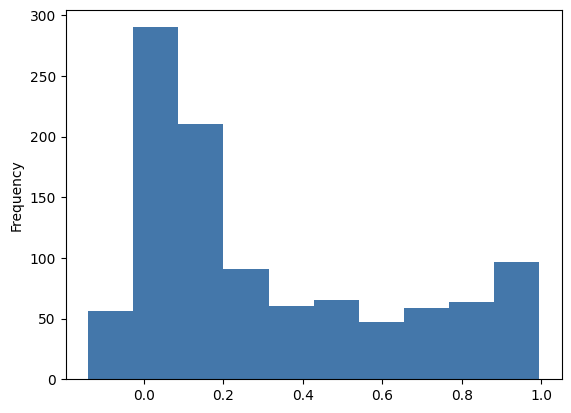

In [46]:
shared_data_author_eml_nodes__sim_text[
    shared_data_author_eml_nodes__sim_text["cos_sim_text"] < 1
]["cos_sim_text"].plot.hist()

<Axes: ylabel='Frequency'>

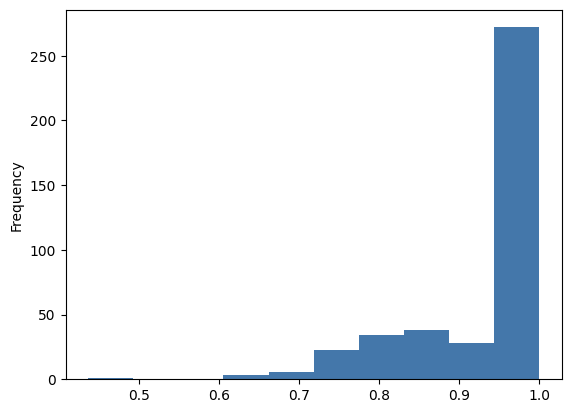

In [47]:
shared_data_author_eml_nodes__sim_attributes["cos_sim_attributes"].plot.hist()

<Axes: ylabel='Frequency'>

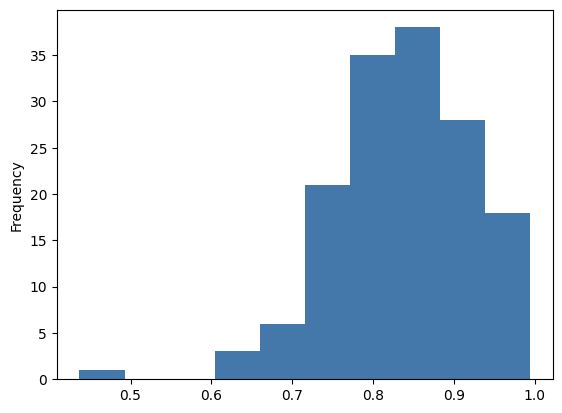

In [48]:
shared_data_author_eml_nodes__sim_attributes[
    shared_data_author_eml_nodes__sim_attributes["cos_sim_attributes"] < 1
]["cos_sim_attributes"].plot.hist()

### Inspect Prepping

In [49]:
%%sql shared_data_author_dwc_t_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_data_author_dwc_t_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [50]:
%%sql shared_data_author_dwc_t_nodes__sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM shared_data_author_dwc_t_nodes__sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_dwc_t_nodes__sim_attributes__path_inspect;

Running query in 'duckdb'

In [51]:
%%sql shared_data_author_eml_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_data_author_eml_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_eml_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [185]:
%%sql shared_data_gt_eml_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_gt_eml_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_data_gt_eml_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_gt_eml_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [186]:
%%sql shared_author_gt_eml_nodes__sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_author_gt_eml_nodes__sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM shared_author_gt_eml_nodes__sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_author_gt_eml_nodes__sim_text__path_inspect;

Running query in 'duckdb'

In [52]:
%%sql shared_data_author_eml_nodes__sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS shared_data_author_eml_nodes__sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM shared_data_author_eml_nodes__sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM shared_data_author_eml_nodes__sim_attributes__path_inspect;

Running query in 'duckdb'

In [53]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect = (
    shared_data_author_dwc_t_nodes__sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect = (
    shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_eml_nodes__sim_text__path_inspect = (
    shared_data_author_eml_nodes__sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
shared_data_author_eml_nodes__sim_attributes__path_inspect = (
    shared_data_author_eml_nodes__sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [54]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.252923,0.782424,1.000000,0.419757,1.000000,0.492633,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,59,59,0.136876,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,169,169,0.093651,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,2,2,0.041696,0.524897,0.566593,0.483202,0.524897,0.504050,0.545745
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.246918,0.760269,1.000000,0.419757,0.824275,0.483202,1.000000


In [55]:
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
22286206021010697,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[84],2,2,0.052487,0.947513,1.0,0.895027,0.947513,0.921270,0.973757
54879317211468838,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[85],2,2,0.047679,0.952321,1.0,0.904642,0.952321,0.928482,0.976161
95853930020399204,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[125],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
111850653873045131,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[130],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
255409801921677082,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[116],2,2,0.082750,0.917250,1.0,0.834499,0.917250,0.875874,0.958625
...,...,...,...,...,...,...,...,...,...,...
18123143049830882349,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[94],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
18205186968821406156,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[138],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000
18249724521440334599,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[90],2,2,0.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000


In [56]:
print(f"{shared_data_author_dwc_t_nodes__sim_text__path_inspect.shape=}")
print(f"{shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.shape=}")

print(f"{shared_data_author_eml_nodes__sim_text__path_inspect.shape=}")
print(f"{shared_data_author_eml_nodes__sim_attributes__path_inspect.shape=}")

shared_data_author_dwc_t_nodes__sim_text__path_inspect.shape=(5, 10)
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.shape=(313, 10)
shared_data_author_eml_nodes__sim_text__path_inspect.shape=(38, 10)
shared_data_author_eml_nodes__sim_attributes__path_inspect.shape=(7, 10)


### Inspections DwC-T

#### Setting the stage

In [57]:
%%sql 
-- shared ancestor paths Data X Author X? GT
SELECT COUNT(1), sd.data_has_text, sd.author_has_text, gt.has_text
FROM shared_data_author_dwc_t_nodes AS sd
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
GROUP BY 2,3,4

Running query in 'duckdb'

,count(1),data_has_text,author_has_text,has_text
0,7724,False,False,False
1,258,True,True,True
2,230,False,False,<NA>


In [58]:
%%sql triple_equivalence_breakdown <<
-- counts of similarity triples: DxA, DxGT, AxGT
SELECT sd.data_text = sd.author_text, sd.data_text = gt.text, sd.author_text = gt.text, COUNT(1) AS cnt
FROM shared_data_author_dwc_t_nodes AS sd
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

In [59]:
triple_equivalence_breakdown

,(sd.data_text = sd.author_text),"(sd.data_text = gt.""text"")","(sd.author_text = gt.""text"")",cnt
0,False,False,False,7
1,False,False,True,10
2,False,True,False,22
3,True,False,False,44
4,True,True,True,175


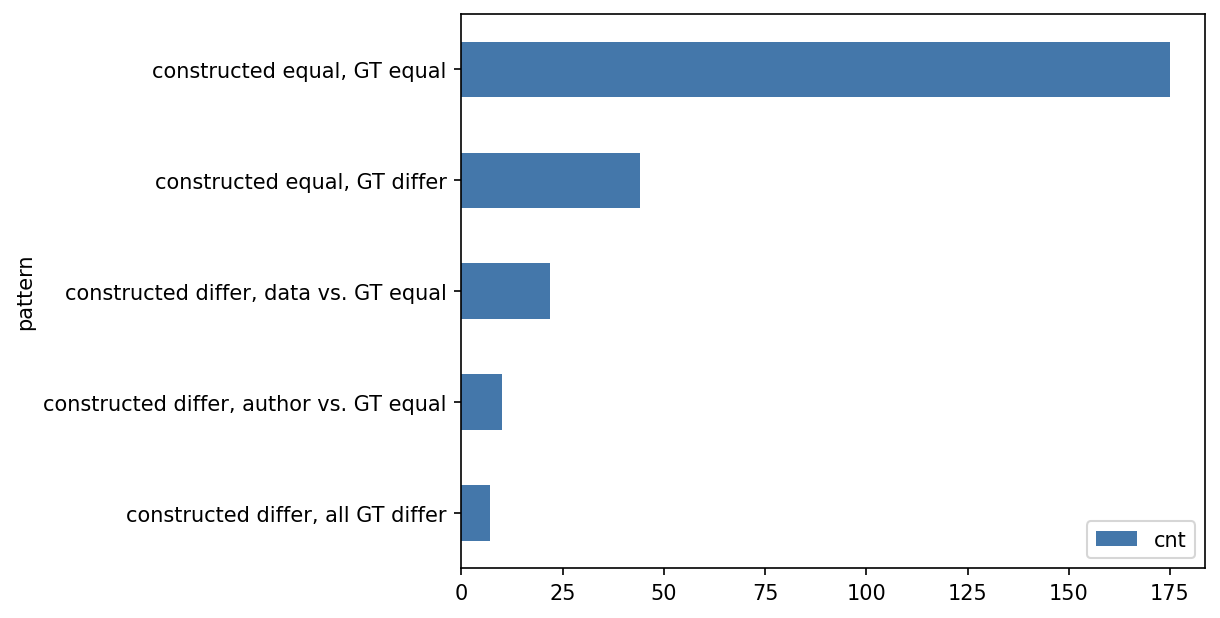

In [60]:
# triple_equivalence_breakdown["pattern"] = [
#     "(sd.data_text != sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text != sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text = gt.'text')",
#     "(sd.data_text != sd.author_text) & (sd.data_text = gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text = sd.author_text) & (sd.data_text != gt.'text') & (sd.author_text != gt.'text')",
#     "(sd.data_text = sd.author_text) & (sd.data_text = gt.'text') & (sd.author_text = gt.'text')",
# ]
triple_equivalence_breakdown["pattern"] = [
    "constructed differ, all GT differ",
    "constructed differ, author vs. GT equal",
    "constructed differ, data vs. GT equal",
    "constructed equal, GT differ",
    "constructed equal, GT equal",
]
fig, ax = plt.subplots(dpi=150)
triple_equivalence_breakdown.plot.barh(x="pattern", y="cnt", ax=ax)
plt.show()

In [61]:
%%sql 
-- similarity scores: DxA, DxGT, AxGT
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__with_gt AS (
-- CREATE OR REPLACE TABLE shared_data_author_dwc_t_nodes__with_gt AS (
    SELECT *, gt.text as gt_text, cos_sim(sd.data_text, gt.text) AS cos_sim_data_gt, cos_sim(sd.author_text, gt.text) AS cos_sim_author_gt
    FROM shared_data_author_dwc_t_nodes AS sd
    LEFT JOIN gt_dwc_t_data_nodes AS gt
        ON sd.path = gt.path
        AND sd.case_id = gt.case_id
    WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt;

Running query in 'duckdb'

,column00,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,...,is_leaf_2,attributes_2,attributes_count_2,has_attributes_2,text_2,has_text_2,path_2,gt_text,cos_sim_data_gt,cos_sim_author_gt
0,2085,135,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
1,2111,136,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
2,2142,137,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,0.64855,0.64855
3,2177,137,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,0.64855,0.64855
4,2196,138,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253,1759,131,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
254,1811,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,1.00000,1.00000
255,1836,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000
256,1858,133,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.00000,1.00000


In [62]:
%%sql path_count_to_avg_medians <<
-- We observe that more files in the dataset cause poorer performance
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_dwc_t_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT path_count, COUNT(1) AS cnt, AVG(ds_med_cont_d_gt) AS avg_median_d_gt, AVG(ds_med_cont_a_gt) AS avg_median_a_gt
FROM sim_per_case_dwc_text
GROUP BY 1
ORDER BY 1

Running query in 'duckdb'

In [63]:
path_count_to_avg_medians

,path_count,cnt,avg_median_d_gt,avg_median_a_gt
0,1,96,1.000000,1.000000
1,2,59,0.878509,0.860639
2,3,12,0.678204,0.664549
3,4,2,0.683988,0.579919


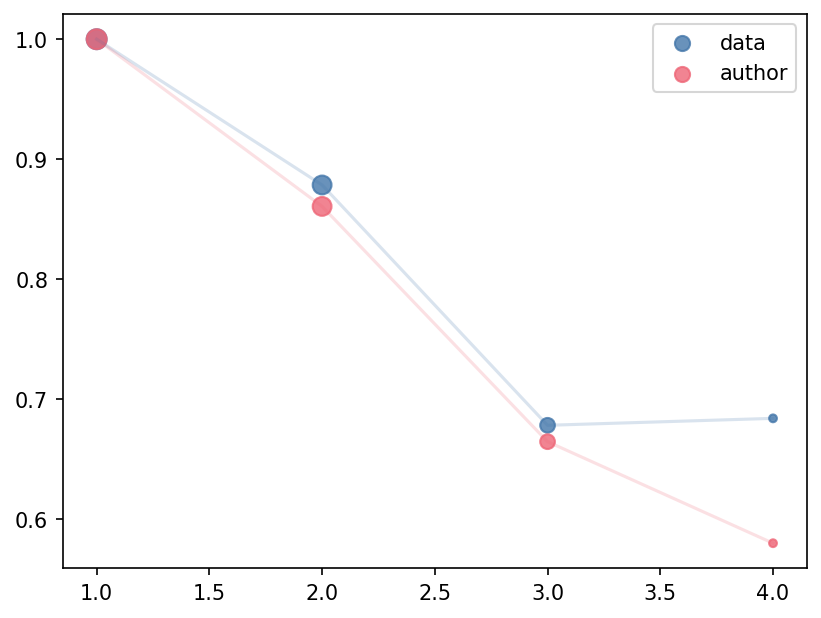

In [64]:
fig,ax = plt.subplots(dpi=150)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_d_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_d_gt"], 
    sizes=np.log(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="data"
)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_a_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_a_gt"], 
    sizes=np.log(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="author"
)
ax.legend()
plt.show()

In [65]:
%%sql
-- regression testing correlation between case size and similarity
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_dwc_t_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT regr_r2(ds_med_cont_d_gt, path_count), regr_r2(ds_med_cont_d_gt, path_count)
FROM sim_per_case_dwc_text

Running query in 'duckdb'

,"regr_r2(ds_med_cont_d_gt, path_count)","regr_r2(ds_med_cont_d_gt, path_count)_1"
0,0.361623,0.361623


#### Text

In [66]:
print(shared_data_author_dwc_t_nodes__sim_text.shape)
print(shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] == 1].shape)
print(shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1].shape)

(258, 5)
(219, 5)
(39, 5)


In [67]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.describe()

,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,51.600000,51.600000,0.154413,0.795006,0.913319,0.523963,0.869835,0.695977,0.909149
std,69.146945,69.146945,0.093496,0.177091,0.193825,0.116644,0.207296,0.277632,0.203149
min,2.000000,2.000000,0.041696,0.524897,0.566593,0.419757,0.524897,0.483202,0.545745
25%,14.000000,14.000000,0.093651,0.760269,1.000000,0.419757,0.824275,0.492633,1.000000
50%,14.000000,14.000000,0.136876,0.782424,1.000000,0.483202,1.000000,0.504050,1.000000
75%,59.000000,59.000000,0.246918,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
max,169.000000,169.000000,0.252923,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [68]:
shared_data_author_dwc_t_nodes__sim_text[shared_data_author_dwc_t_nodes__sim_text["cos_sim_text"] < 1].describe()

,case_id,cos_sim_text
count,39.000000,39.000000
mean,96.102564,0.595198
std,54.402397,0.080307
min,5.000000,0.419757
25%,43.000000,0.502064
50%,103.000000,0.648550
75%,141.000000,0.648550
max,174.000000,0.648550


In [69]:
%%sql
-- regression testing correlation between case size and similarity
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        COUNT(cos_sim_text) as ds_count,
        stddev_pop(cos_sim_text) as ds_std_pop,
        AVG(cos_sim_text) as ds_mean,
        MAX(cos_sim_text) as ds_max,
        MIN(cos_sim_text) as ds_min,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
    FROM shared_data_author_dwc_t_nodes__sim_text as c
    GROUP BY c.case_id
)
SELECT regr_r2(ds_med_cont, path_count)
FROM sim_per_case_dwc_text

Running query in 'duckdb'

,"regr_r2(ds_med_cont, path_count)"
0,0.284998


In [70]:
%%sql
WITH sim_per_case_dwc_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        COUNT(cos_sim_text) as ds_count,
        stddev_pop(cos_sim_text) as ds_std_pop,
        AVG(cos_sim_text) as ds_mean,
        MAX(cos_sim_text) as ds_max,
        MIN(cos_sim_text) as ds_min,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
    FROM shared_data_author_dwc_t_nodes__sim_text as c
    GROUP BY c.case_id
)
SELECT path_count, COUNT(1), AVG(ds_med_cont)
FROM sim_per_case_dwc_text
GROUP BY 1
ORDER BY 1

Running query in 'duckdb'

,path_count,count(1),avg(ds_med_cont)
0,1,96,1.000000
1,2,59,0.934475
2,3,12,0.763626
3,4,2,0.642680


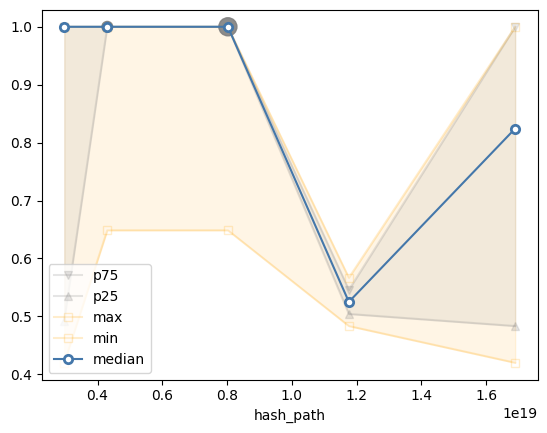

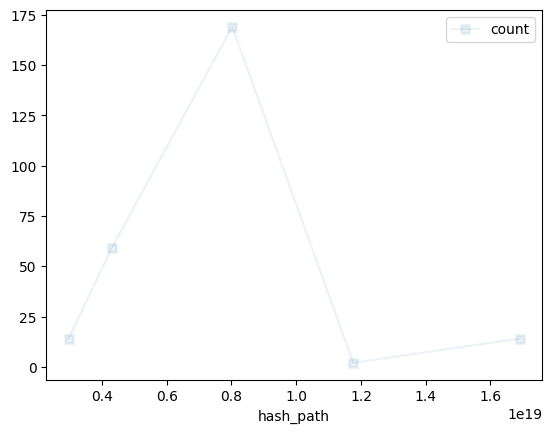

In [71]:
df = shared_data_author_dwc_t_nodes__sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

#### Attributes

In [72]:
%%sql
-- attributes constructed by data
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, dja.key, dja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.data_attributes) AS dja
);

-- attributes constructed by author
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, aja.key, aja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.author_attributes) AS aja
);

-- attributes from ground truth
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS 
    gt_dwc_t_data_nodes__attributes__unpacked AS (
SELECT d.path, d.attributes, d.case_id, aja.key, aja.value
FROM 
    gt_dwc_t_data_nodes AS d,
    json_each(d.attributes) AS aja
);

Running query in 'duckdb'

,Count
0,17245


In [73]:
%%sql 
SELECT * FROM gt_dwc_t_data_nodes__attributes__unpacked;

Running query in 'duckdb'

,path,attributes,case_id,key,value
0,.,"{""metadata"": ""eml.xml""}",0,metadata,"""eml.xml"""
1,{http://rs.tdwg.org/dwc/text/}core,"{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\\t"", ""linesTerminatedBy"": ""\\n"", ""fieldsEnclosedBy"": """", ""ignoreHeaderLines"": ""1"", ""rowType"": ""http://rs.tdwg.org/dwc/terms/Event""}",0,rowType,"""http://rs.tdwg.org/dwc/terms/Event"""
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id,"{""index"": ""0""}",0,index,"""0"""
3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],"{""index"": ""1"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventID""}",0,term,"""http://rs.tdwg.org/dwc/terms/eventID"""
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],"{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventDate""}",0,term,"""http://rs.tdwg.org/dwc/terms/eventDate"""
...,...,...,...,...,...
17240,{http://rs.tdwg.org/dwc/text/}extension[2],"{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\\t"", ""linesTerminatedBy"": ""\\n"", ""fieldsEnclosedBy"": """", ""ignoreHeaderLines"": ""1"", ""rowType"": ""http://data.ggbn.org/schemas/ggbn/terms/Permit""}",170,encoding,"""UTF-8"""
17241,{http://rs.tdwg.org/dwc/text/}core,"{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\\t"", ""linesTerminatedBy"": ""\\n"", ""fieldsEnclosedBy"": """", ""ignoreHeaderLines"": ""1"", ""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence""}",171,encoding,"""UTF-8"""
17242,{http://rs.tdwg.org/dwc/text/}core,"{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\\t"", ""linesTerminatedBy"": ""\\n"", ""fieldsEnclosedBy"": """", ""ignoreHeaderLines"": ""1"", ""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence""}",172,encoding,"""UTF-8"""
17243,{http://rs.tdwg.org/dwc/text/}extension,"{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\\t"", ""linesTerminatedBy"": ""\\n"", ""fieldsEnclosedBy"": """", ""ignoreHeaderLines"": ""1"", ""rowType"": ""http://rs.gbif.org/terms/1.0/Multimedia""}",172,encoding,"""UTF-8"""


In [74]:
col = shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"]
mask = (col < 1) & ~np.isclose(col, 1.0)

print(shared_data_author_dwc_t_nodes__sim_attributes.shape)
print(shared_data_author_dwc_t_nodes__sim_attributes[shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"] == 1].shape)
print(shared_data_author_dwc_t_nodes__sim_attributes[mask].shape)

(7696, 5)
(6313, 5)
(1381, 5)


In [75]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.describe()

,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,51.600000,51.600000,0.154413,0.795006,0.913319,0.523963,0.869835,0.695977,0.909149
std,69.146945,69.146945,0.093496,0.177091,0.193825,0.116644,0.207296,0.277632,0.203149
min,2.000000,2.000000,0.041696,0.524897,0.566593,0.419757,0.524897,0.483202,0.545745
25%,14.000000,14.000000,0.093651,0.760269,1.000000,0.419757,0.824275,0.492633,1.000000
50%,14.000000,14.000000,0.136876,0.782424,1.000000,0.483202,1.000000,0.504050,1.000000
75%,59.000000,59.000000,0.246918,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
max,169.000000,169.000000,0.252923,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [76]:
# workaround for float64
col = shared_data_author_dwc_t_nodes__sim_attributes["cos_sim_attributes"]
mask_lt_1 = (col < 1) & ~np.isclose(col, 1.0)
mask_eq_1 = (col == 1) | np.isclose(col, 1.0)

display(shared_data_author_dwc_t_nodes__sim_attributes[mask_lt_1].describe())
display(shared_data_author_dwc_t_nodes__sim_attributes[mask_eq_1].describe())

,case_id,cos_sim_attributes
count,1381.000000,1381.000000
mean,93.476466,0.810837
std,53.275769,0.099347
min,2.000000,0.428500
25%,43.000000,0.732835
50%,96.000000,0.808477
75%,137.000000,0.880683
max,178.000000,0.999148


,case_id,cos_sim_attributes
count,6315.000000,6.315000e+03
mean,88.937451,1.000000e+00
std,50.436430,2.121645e-09
min,0.000000,9.999999e-01
25%,47.000000,1.000000e+00
50%,92.000000,1.000000e+00
75%,132.000000,1.000000e+00
max,178.000000,1.000000e+00


In [77]:
%%sql
-- overview of mixed up attributes: data x author
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,rowType,18
2,fieldsTerminatedBy,21
3,metadata,92
4,index,271
5,term,479


In [78]:
%%sql
-- overview of mixed up attributes: data x author
SELECT aja.path, aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1,2
ORDER BY cnt
;

Running query in 'duckdb'

,path,key,cnt
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[103],term,1
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[156],term,1
2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[45],index,1
3,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[4],term,1
4,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[8],index,1
...,...,...,...
246,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,16
247,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,18
248,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,21
249,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,30


In [79]:
%%sql
-- inferred equivalently
SELECT *
FROM shared_data_author_dwc_t_nodes__with_gt
WHERE gt_text = author_text AND gt_text = data_text;

Running query in 'duckdb'

,column00,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,...,is_leaf_2,attributes_2,attributes_count_2,has_attributes_2,text_2,has_text_2,path_2,gt_text,cos_sim_data_gt,cos_sim_author_gt
0,2085,135,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
1,2111,136,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
2,2196,138,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
3,2229,139,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
4,2260,14,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170,1759,131,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
171,1811,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,event.txt,...,True,{},0,False,event.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,1.0,1.0
172,1836,132,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0
173,1858,133,{http://rs.tdwg.org/dwc/text/}location,3,0,True,{},0,False,occurrence.txt,...,True,{},0,False,occurrence.txt,True,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,1.0,1.0


In [80]:
%%sql
-- inferred equivalently, reconstruct matchin path subsequences
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently AS (
    SELECT split(d.path, '/{')[1] AS file_subpath, d.case_id
    FROM shared_data_author_dwc_t_nodes__with_gt AS d
    WHERE gt_text = author_text AND gt_text = data_text  
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently;

Running query in 'duckdb'

,file_subpath,case_id
0,{http://rs.tdwg.org/dwc/text/}core,135
1,{http://rs.tdwg.org/dwc/text/}core,136
2,{http://rs.tdwg.org/dwc/text/}core,138
3,{http://rs.tdwg.org/dwc/text/}core,139
4,{http://rs.tdwg.org/dwc/text/}core,14
...,...,...
170,{http://rs.tdwg.org/dwc/text/}core,131
171,{http://rs.tdwg.org/dwc/text/}core,132
172,{http://rs.tdwg.org/dwc/text/}extension,132
173,{http://rs.tdwg.org/dwc/text/}core,133


In [81]:
%%sql
-- inferred identical yet different, reconstruct matchin path subsequences
CREATE 
    -- OR REPLACE 
    TABLE 
    IF NOT EXISTS 
    shared_data_author_dwc_t_nodes__with_gt__identical_yet_different AS (
    SELECT split(d.path, '/{')[1]  AS file_subpath, d.case_id
    FROM shared_data_author_dwc_t_nodes__with_gt AS d
    WHERE data_text = author_text AND author_text <> gt_text AND data_text <> gt_text
);
SELECT * FROM shared_data_author_dwc_t_nodes__with_gt__identical_yet_different;

Running query in 'duckdb'

,file_subpath,case_id
0,{http://rs.tdwg.org/dwc/text/}core,137
1,{http://rs.tdwg.org/dwc/text/}extension,137
2,{http://rs.tdwg.org/dwc/text/}core,152
3,{http://rs.tdwg.org/dwc/text/}core,154
4,{http://rs.tdwg.org/dwc/text/}extension,154
5,{http://rs.tdwg.org/dwc/text/}core,155
6,{http://rs.tdwg.org/dwc/text/}extension,155
7,{http://rs.tdwg.org/dwc/text/}core,159
8,{http://rs.tdwg.org/dwc/text/}core,16
9,{http://rs.tdwg.org/dwc/text/}extension,16


In [82]:
%%sql 
(SELECT DISTINCT case_id FROM shared_data_author_dwc_t_nodes__with_gt__identical_yet_different)
EXCEPT 
(SELECT DISTINCT case_id FROM shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently)
;

Running query in 'duckdb'

,case_id
0,159
1,42
2,62
3,78
4,154
5,30
6,65
7,2
8,60
9,63


In [83]:
%%sql
-- check path patterns for attributes
SELECT split(aja.path, '/{')[1], aja.case_id, COUNT(1) AS cnt_attributes 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1,2
ORDER BY case_id, cnt_attributes

Running query in 'duckdb'

,"split(aja.path, '/{')[1]",case_id,cnt_attributes
0,.,2,1
1,{http://rs.tdwg.org/dwc/text/}extension,2,7
2,{http://rs.tdwg.org/dwc/text/}core,2,21
3,.,3,1
4,{http://rs.tdwg.org/dwc/text/}core,6,3
...,...,...,...
197,{http://rs.tdwg.org/dwc/text/}core,172,1
198,{http://rs.tdwg.org/dwc/text/}extension,172,5
199,.,175,1
200,.,177,1


In [84]:
%%sql
-- check path patterns for attributes, distinct paths
SELECT split(aja.path, '/{')[1], COUNT(1) AS cnt_attributes 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(aja.path, '/{')[1]",cnt_attributes
0,{http://rs.tdwg.org/dwc/text/}extension[1],33
1,{http://rs.tdwg.org/dwc/text/}extension[2],71
2,.,92
3,{http://rs.tdwg.org/dwc/text/}core,270
4,{http://rs.tdwg.org/dwc/text/}extension,417


In [85]:
%%sql
-- equivalently inferred triples
CREATE 
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    equivalently_inferred_triples_attributes AS (
    SELECT *, dja.value as data_value, aja.value as author_value, gtja.key AS gt_key, gtja.value AS gt_value
    FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
    JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
        ON  aja.path = dja.path
        AND aja.case_id = dja.case_id
        AND aja.key = dja.key
    LEFT JOIN gt_dwc_t_data_nodes__attributes__unpacked as gtja
        ON gtja.path = aja.path
        AND gtja.case_id = aja.case_id
        AND gtja.key = aja.key
    LEFT JOIN shared_data_author_dwc_t_nodes__with_gt__inferred_equivalently AS ies
        ON (ies.file_subpath = split(aja.path, '/{')[1]  AND ies.case_id = aja.case_id) 
    WHERE 
        aja.case_id NOT IN (
            SELECT DISTINCT d.case_id
            FROM shared_data_author_dwc_t_nodes__sim_text AS d
            WHERE d.data_text <> d.author_text
        )
        -- AND aja.value <> dja.value
        -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
        -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
        AND ((file_subpath IS NOT Null) OR aja.path = '.')
);
SELECT split(ats.path, '/{')[1], COUNT(1) AS cnt_attributes, (SELECT COUNT(1) FROM equivalently_inferred_triples_attributes) as total 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(ats.path, '/{')[1]",cnt_attributes,total
0,{http://rs.tdwg.org/dwc/text/}extension[2],70,11772
1,{http://rs.tdwg.org/dwc/text/}extension[1],133,11772
2,.,150,11772
3,{http://rs.tdwg.org/dwc/text/}extension,1020,11772
4,{http://rs.tdwg.org/dwc/text/}core,10399,11772


In [86]:
%%sql
-- identical yet different triples
CREATE 
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    identical_yet_different_triples_attributes AS (
    SELECT *, dja.value as data_value, aja.value as author_value, gtja.key AS gt_key, gtja.value AS gt_value
    FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
    JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
        ON  aja.path = dja.path
        AND aja.case_id = dja.case_id
        AND aja.key = dja.key
    LEFT JOIN gt_dwc_t_data_nodes__attributes__unpacked as gtja
        ON gtja.path = aja.path
        AND gtja.case_id = aja.case_id
        AND gtja.key = aja.key
    JOIN shared_data_author_dwc_t_nodes__with_gt__identical_yet_different AS ies
        ON (ies.file_subpath = split(aja.path, '/{')[1]  AND ies.case_id = aja.case_id) 
    WHERE 
        aja.case_id NOT IN (
            SELECT DISTINCT d.case_id
            FROM shared_data_author_dwc_t_nodes__sim_text AS d
            WHERE d.data_text <> d.author_text
        )
        -- AND aja.value <> dja.value
        -- AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
        -- AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
        -- AND ((file_subpath IS NOT Null) OR aja.path = '.')
);
SELECT split(ats.path, '/{')[1], COUNT(1) AS cnt_attributes, (SELECT COUNT(1) FROM identical_yet_different_triples_attributes) as total  
FROM identical_yet_different_triples_attributes AS ats
GROUP BY 1
ORDER BY cnt_attributes

Running query in 'duckdb'

,"split(ats.path, '/{')[1]",cnt_attributes,total
0,{http://rs.tdwg.org/dwc/text/}extension[1],23,2040
1,{http://rs.tdwg.org/dwc/text/}extension[2],136,2040
2,{http://rs.tdwg.org/dwc/text/}extension,769,2040
3,{http://rs.tdwg.org/dwc/text/}core,1112,2040


In [87]:
%%sql
SELECT ats.key, COUNT(1) AS cnt_attributes 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY 2

Running query in 'duckdb'

,key,cnt_attributes
0,delimitedBy,4
1,encoding,78
2,metadata,150
3,fieldsEnclosedBy,164
4,fieldsTerminatedBy,164
5,ignoreHeaderLines,164
6,rowType,172
7,term,5352
8,index,5524


In [88]:
%%sql
SELECT ats.data_value = ats.gt_value, COUNT(1) AS cnt_attributes 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY 2

Running query in 'duckdb'

,(ats.data_value = ats.gt_value),cnt_attributes
0,<NA>,7
1,False,1623
2,True,10142


In [89]:
%%sql
SELECT ats.author_value = ats.gt_value, COUNT(1) AS cnt_attributes 
FROM equivalently_inferred_triples_attributes AS ats
GROUP BY 1
ORDER BY 2

Running query in 'duckdb'

,(ats.author_value = ats.gt_value),cnt_attributes
0,<NA>,7
1,False,1707
2,True,10058


In [90]:
%%sql
SELECT ats.data_value = ats.gt_value, COUNT(1) AS cnt_attributes 
FROM identical_yet_different_triples_attributes AS ats
GROUP BY 1
ORDER BY 2

Running query in 'duckdb'

,(ats.data_value = ats.gt_value),cnt_attributes
0,<NA>,358
1,True,701
2,False,981


In [91]:
%%sql
SELECT ats.author_value = ats.gt_value, COUNT(1) AS cnt_attributes 
FROM identical_yet_different_triples_attributes AS ats
GROUP BY 1
ORDER BY 2

Running query in 'duckdb'

,(ats.author_value = ats.gt_value),cnt_attributes
0,<NA>,358
1,True,654
2,False,1028


In [92]:
%%sql
-- equivalently inferred triples: equality breakdown
-- ==> some attributes don't depend on position are well populated, i.e. ecnoding, ignoreHeaderLines etc.
-- ==> the terms and indeces are largely accurate with data performing slightly more accurately
WITH ie__count_per_key__total AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes 
    FROM equivalently_inferred_triples_attributes AS ats
    GROUP BY 1
), ie__count_per_key__data_eq_author AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_dea 
    FROM equivalently_inferred_triples_attributes AS ats
    WHERE ats.data_value = ats.author_value
    GROUP BY 1
), ie__count_per_key__data_eq_gt AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_deg
    FROM equivalently_inferred_triples_attributes AS ats
    WHERE ats.data_value = ats.gt_value
    GROUP BY 1
), ie__count_per_key__author_eq_gt AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_aeg 
    FROM equivalently_inferred_triples_attributes AS ats
    WHERE ats.author_value = ats.gt_value
    GROUP BY 1
)
SELECT ats.key, ats.cnt_attributes, ats_dea.cnt_attributes_dea, ats_deg.cnt_attributes_deg, ats_aeg.cnt_attributes_aeg,  
FROM ie__count_per_key__total AS ats
LEFT JOIN ie__count_per_key__data_eq_author AS ats_dea
    ON ats.key = ats_dea.key
LEFT JOIN ie__count_per_key__data_eq_gt AS ats_deg
    ON ats.key = ats_deg.key
LEFT JOIN ie__count_per_key__author_eq_gt AS ats_aeg
    ON ats.key = ats_aeg.key
ORDER BY key
    ;

Running query in 'duckdb'

,key,cnt_attributes,cnt_attributes_dea,cnt_attributes_deg,cnt_attributes_aeg
0,delimitedBy,4,2,<NA>,<NA>
1,encoding,78,78,78,78
2,fieldsEnclosedBy,164,164,<NA>,<NA>
3,fieldsTerminatedBy,164,149,156,156
4,ignoreHeaderLines,164,164,163,163
5,index,5524,5391,4979,4920
6,metadata,150,58,<NA>,<NA>
7,rowType,172,158,151,156
8,term,5352,5004,4615,4585


In [93]:
%%sql
-- identical_yet_different_triples_attributes triples: equality breakdown
-- ==> some attributes don't depend on position are well populated, i.e. ecnoding, ignoreHeaderLines etc.
-- ==> the terms and indeces are clearly off, as expected due to the wrong inference of file structure
WITH ie__count_per_key__total AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes 
    FROM identical_yet_different_triples_attributes AS ats
    GROUP BY 1
), ie__count_per_key__data_eq_author AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_dea 
    FROM identical_yet_different_triples_attributes AS ats
    WHERE ats.data_value = ats.author_value
    GROUP BY 1
), ie__count_per_key__data_eq_gt AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_deg
    FROM identical_yet_different_triples_attributes AS ats
    WHERE ats.data_value = ats.gt_value
    GROUP BY 1
), ie__count_per_key__author_eq_gt AS (
    SELECT ats.key, COUNT(1) AS cnt_attributes_aeg 
    FROM identical_yet_different_triples_attributes AS ats
    WHERE ats.author_value = ats.gt_value
    GROUP BY 1
)
SELECT ats.key, ats.cnt_attributes, ats_dea.cnt_attributes_dea, ats_deg.cnt_attributes_deg, ats_aeg.cnt_attributes_aeg,  
FROM ie__count_per_key__total AS ats
LEFT JOIN ie__count_per_key__data_eq_author AS ats_dea
    ON ats.key = ats_dea.key
LEFT JOIN ie__count_per_key__data_eq_gt AS ats_deg
    ON ats.key = ats_deg.key
LEFT JOIN ie__count_per_key__author_eq_gt AS ats_aeg
    ON ats.key = ats_aeg.key
ORDER BY key
    ;

Running query in 'duckdb'

,key,cnt_attributes,cnt_attributes_dea,cnt_attributes_deg,cnt_attributes_aeg
0,encoding,16,16,16,16
1,fieldsEnclosedBy,38,38,<NA>,<NA>
2,fieldsTerminatedBy,38,32,36,34
3,ignoreHeaderLines,38,38,38,38
4,index,955,817,610,565
5,rowType,38,34,<NA>,<NA>
6,term,917,786,1,1


#### Per attribute pattern in I/E case

In [94]:
%%sql
-- inspect I/E:K-delimitedBy
-- ==> massi adds the `delimitedBy` attribute to the gt metadata
-- ==> by manual check, massi is closer to the data than the GT metadata (the `|` is indeed used)
-- ==> it differs in surrounding the delimiter with whitespace
-- ==> interestingly, it was already added by the architect
SELECT case_id, path, data_value, author_value, gt_value
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'delimitedBy'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value
0,113,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[7],""" | """,""" | """,None
1,113,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[27],""" | """,""" | """,None
2,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11],"""|""",""" | """,None
3,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25],"""|""",""" | """,None


In [95]:
%%sql
-- inspect I/E:K-fieldsEnclosedBy
-- ==> massi proactively specifies it to the commonly used default, while it is not always accurate to the ground truth
-- ==> important to note that GT metadata is not error free in that regard either
-- ==> technically this can lead to a broken parsing
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'fieldsEnclosedBy'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,1,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
1,6,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
2,7,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
3,8,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
4,9,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
...,...,...,...,...,...,...
159,172,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
160,172,{http://rs.tdwg.org/dwc/text/}extension,"""&quot;""","""&quot;""","""""",1
161,175,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1
162,177,{http://rs.tdwg.org/dwc/text/}core,"""&quot;""","""&quot;""","""""",1


In [96]:
%%sql
-- inspect I/E:K-fieldsTerminatedBy
-- ==> sometimes its a different encoding choice
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'fieldsTerminatedBy'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,14,{http://rs.tdwg.org/dwc/text/}extension,""" ""","""\\t""","""\\t""",1
1,14,{http://rs.tdwg.org/dwc/text/}core,""" ""","""\\t""","""\\t""",1
2,29,{http://rs.tdwg.org/dwc/text/}core,""" ""","""\\t""","""\\t""",1
3,32,{http://rs.tdwg.org/dwc/text/}core,""" ""","""\\t""","""\\t""",1
4,61,{http://rs.tdwg.org/dwc/text/}core,""" ""","""\\t""","""\\t""",1
5,66,{http://rs.tdwg.org/dwc/text/}core,"""\\t""",""" ""","""\\t""",1
6,94,{http://rs.tdwg.org/dwc/text/}core,"""\\t""","""&#9;""","""\\t""",1
7,110,{http://rs.tdwg.org/dwc/text/}core,"""\\t""",""" ""","""\\t""",1
8,128,{http://rs.tdwg.org/dwc/text/}core,""" ""","""\\t""","""\\t""",1
9,135,{http://rs.tdwg.org/dwc/text/}core,"""\\t""","""&#x9;""","""\\t""",1


In [97]:
%%sql
-- inspect I/E:K-fieldsTerminatedBy
-- ==> author seems to get it more similarly (11) than data (8)
SELECT data_value, author_value, gt_value, COUNT(1) AS cnt
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'fieldsTerminatedBy'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3
ORDER BY cnt
;

Running query in 'duckdb'

,data_value,author_value,gt_value,cnt
0,"""\\t""","""&#x9;""","""\\t""",1
1,""",""","""\\t""","""\\t""",1
2,"""&#x9;""","""&#9;""","""\\t""",1
3,"""\\t""","""&#9;""","""\\t""",2
4,"""\\t""",""" ""","""\\t""",4
5,""" ""","""\\t""","""\\t""",6


In [98]:
%%sql
-- inspect I/E:K-ignoreHeaderLines
-- ==> here massi is mistaken in both cases (validated by consulting the raw data)
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'ignoreHeaderLines'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,134,{http://rs.tdwg.org/dwc/text/}core,"""1""","""1""","""0""",1


In [99]:
%%sql
-- inspect I/E:K-index
-- ==> here we see frequent errors in assigning an index, which is weird and bad
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'index'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[1],"""2""","""2""","""1""",1
1,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5],"""6""","""6""","""5""",1
2,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid,"""1""","""1""","""0""",1
3,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],"""4""","""4""","""3""",1
4,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],"""3""","""3""","""2""",1
...,...,...,...,...,...,...
626,166,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid,"""11""","""11""","""0""",1
627,166,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],"""1""","""1""","""2""",1
628,166,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[11],"""10""","""10""","""11""",1
629,166,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[9],"""8""","""8""","""9""",1


In [100]:
%%sql
-- inspect I/E:K-index
-- ==> here we see frequent errors in assigning an index, which is weird and bad
-- ==> often they fail in the same way
SELECT data_value, author_value, gt_value, COUNT(1) AS cnt
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'index'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3
;

Running query in 'duckdb'

,data_value,author_value,gt_value,cnt
0,"""9""","""9""","""8""",4
1,"""12""","""12""","""11""",4
2,"""45""","""45""","""44""",3
3,"""4""","""4""","""5""",13
4,"""7""","""7""","""8""",11
...,...,...,...,...
312,"""9""","""10""","""10""",1
313,"""23""","""22""","""23""",1
314,"""27""","""26""","""27""",1
315,"""16""","""15""","""15""",1


In [101]:
%%sql
-- inspect I/E:K-index
-- ==> here we see frequent errors in assigning an index, which is weird and bad
-- ==> often they fail in the same way
-- ==> but data is slightly better (86) cases
SELECT data_value == gt_value, author_value == gt_value, COUNT(1) AS cnt
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'index'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2
ORDER BY cnt
;

Running query in 'duckdb'

,(data_value = gt_value),(author_value = gt_value),cnt
0,<NA>,<NA>,1
1,False,True,27
2,True,False,86
3,False,False,517


In [102]:
%%sql index_distances <<
-- inspect I/E:K-index
-- ==> here we see frequent errors in assigning an index, which is weird and bad
-- ==> often they fail in the same way
-- ==> but data is slightly better (86) cases
-- ==> majority of errors are off by one, i.e. zero vs 1-based indexing
SELECT data_value::INT - gt_value::INT AS dv_gt_index_distance, author_value::INT - gt_value::INT AS av_gt_index_distance, COUNT(1) AS cnt
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'index'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2
ORDER BY cnt
;

Running query in 'duckdb'

In [103]:
index_distances

,dv_gt_index_distance,av_gt_index_distance,cnt
0,<NA>,<NA>,1
1,10,10,1
2,8,8,1
3,0,6,1
4,5,5,1
5,10,0,1
6,11,11,1
7,4,4,1
8,15,15,1
9,13,13,1


<Axes: xlabel='av_gt_index_distance'>

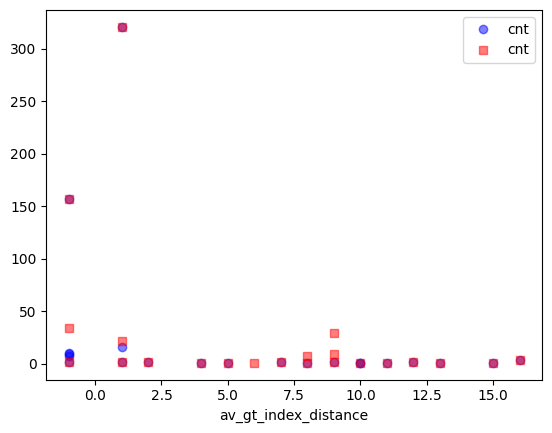

In [104]:
ax = index_distances[index_distances["dv_gt_index_distance"] != 0].plot(x="dv_gt_index_distance", y="cnt", alpha=0.5, lw=0, marker="o", color="blue")
(index_distances[index_distances["av_gt_index_distance"] != 0]).plot(x="av_gt_index_distance", y="cnt",alpha=0.5, lw=0, marker="s", color="red", ax=ax)

In [105]:
%%sql
-- inspect I/E:K-metadata
-- ==> both consistently fail to match the GT
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'metadata'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,0,.,"""meta.xml""","""meta.xml""","""eml.xml""",1
1,1,.,"""not-derived-001""","""not-derived-001""","""eml.xml""",1
2,2,.,"""meta.xml""","""not-derived-001""","""eml.xml""",1
3,3,.,"""meta.xml""","""not-derived-001""","""eml.xml""",1
4,6,.,"""meta.xml""","""meta.xml""","""eml.xml""",1
...,...,...,...,...,...,...
145,171,.,"""meta.xml""","""not-derived-001""","""eml.xml""",1
146,172,.,"""not-derived-001""","""meta.xml""","""eml.xml""",1
147,175,.,"""meta.xml""","""not-derived-001""","""eml.xml""",1
148,177,.,"""meta.xml""","""not-derived-001""","""eml.xml""",1


In [106]:
%%sql
-- inspect I/E:K-metadata
-- ==> both consistently fail to match the GT
-- ==> however, the data-focused provider infers that it should be an XML file more often
-- ==> yet it assigns the name of the DwC-T file itself (meta.xml)
-- ==> author-focused provider fails to retrieve the values more often,
-- ==> i.e. leaving them blank (not-derived) or populating irrelevant values (DOIs retrieved from the data paper, or imperative suggestion to omit the attribute)
SELECT data_value, author_value, gt_value, COUNT(1) AS cnt
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'metadata'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3
ORDER BY cnt
;

Running query in 'duckdb'

,data_value,author_value,gt_value,cnt
0,"""1""","""omit the metadata attribute""","""eml.xml""",1
1,"""meta.xml""","""https://www.gbif.org/dataset/e9aeed17-b33f-4af2-8471-9be87633d7e1""","""eml.xml""",1
2,"""meta.xml""","""not-derived-001` is unavailable. The interview confirmed that no separate metadata file or URI/path such as `meta.xml`, `eml.xml`, or `metadata.xml` was identified in the provided material.'}}}""","""eml.xml""",1
3,"""meta.xml""","""omit the metadata attribute""","""eml.xml""",1
4,"""Ascorhynchus hippos Turpaeva, 1994""","""omit or leave empty""","""eml.xml""",1
5,"""meta.xml""","""omit the `metadata` attribute""","""eml.xml""",1
6,"""meta.xml""","""https://doi.org/10.15468/gwr8mg""","""eml.xml""",1
7,"""meta.xml""","""not-derived-001""",NaN,2
8,"""not-derived-001""","""meta.xml""","""eml.xml""",9
9,"""meta.xml""","""meta.xml""","""eml.xml""",15


In [107]:
%%sql
-- inspect I/E:K-rowType
-- ==> some are different terms completely, others differ by prefix only
SELECT case_id, path, data_value, author_value, gt_value
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'rowType'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value
0,102,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.gbif.org/terms/1.0/Multimedia"""
1,108,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact"""
2,106,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
3,15,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact"""
4,163,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.gbif.org/terms/1.0/Multimedia"""
5,172,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/Media""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia"""
6,6,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.gbif.org/dwc/terms/DNADerivedData""","""http://rs.gbif.org/terms/1.0/DNADerivedData"""
7,52,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia"""
8,22,{http://rs.tdwg.org/dwc/text/}extension[2],"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact"""
9,24,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence"""


In [108]:
%%sql
-- inspect I/E:K-rowType
-- ==> some are different terms completely, others differ by prefix only
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'rowType'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,6,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.gbif.org/dwc/terms/DNADerivedData""","""http://rs.gbif.org/terms/1.0/DNADerivedData""",1
1,15,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact""",1
2,22,{http://rs.tdwg.org/dwc/text/}extension[2],"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact""",1
3,24,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",1
4,34,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/MaterialCitation""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia""",1
5,37,{http://rs.tdwg.org/dwc/text/}extension[1],"""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact""","""http://rs.iobis.org/obis/terms/ExtendedMeasurementOrFact""",1
6,37,{http://rs.tdwg.org/dwc/text/}extension[2],"""http://rs.tdwg.org/dwc/terms/MaterialSample""","""http://rs.tdwg.org/dwc/terms/DnaDerivedData""","""http://rs.gbif.org/terms/1.0/DNADerivedData""",1
7,44,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",1
8,50,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",1
9,52,{http://rs.tdwg.org/dwc/text/}extension,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.gbif.org/terms/1.0/Multimedia""",1


In [109]:
%%sql
-- inspect I/E:K-rowType
-- ==> some are different terms completely (9), others (13) differ by prefix only
-- ==> author actually does a better job in identifying the class of the file's rows (10 vs 4 times)
SELECT split(data_value, '/')[-1] = split(gt_value, '/')[-1] AS data_gt_resource_match, split(author_value, '/')[-1] = split(gt_value, '/')[-1] AS author_gt_resource_match, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'rowType'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2
ORDER BY 3
;

Running query in 'duckdb'

,data_gt_resource_match,author_gt_resource_match,count(1)
0,True,True,1
1,True,False,3
2,False,False,9
3,False,True,9


In [110]:
%%sql
-- inspect I/E:K-term
-- ==> similar to rowType, sometimes the resource is right, but the URL prefixes differ
SELECT case_id, path, data_value, author_value, gt_value, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'term'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2,3,4,5
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,data_value,author_value,gt_value,count(1)
0,1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license""",1
1,6,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],"""http://rs.tdwg.org/dwc/terms/modified""","""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""",1
2,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],"""http://rs.tdwg.org/dwc/terms/pcrPrimerReverse""","""http://rs.gbif.org/terms/1.0/pcr_primer_reverse""","""http://rs.gbif.org/terms/pcr_primer_forward""",1
3,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[9],"""http://rs.tdwg.org/dwc/terms/pcrPrimerReference""","""http://rs.gbif.org/terms/1.0/pcr_primer_reference""","""http://rs.gbif.org/terms/pcr_primer_name_reverse""",1
4,6,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],"""http://rs.tdwg.org/dwc/terms/measurementMethod""","""http://rs.gbif.org/terms/1.0/seq_meth""","""https://w3id.org/mixs/0000045""",1
...,...,...,...,...,...,...
830,175,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],"""http://rs.tdwg.org/dwc/terms/language""","""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language""",1
831,175,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],"""http://rs.tdwg.org/dwc/terms/modified""","""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""",1
832,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],"""http://purl.org/dc/terms/modified""","""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""",1
833,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],"""http://purl.org/dc/terms/language""","""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language""",1


In [111]:
%%sql
-- inspect I/E:K-term
-- ==> similar to rowType, sometimes the resource is right, but the URL prefixes differ
-- ==> in which case, resource match is more often done by the data-focused information provider (195 + 83 times), then by the author-focused one (195 + 41) 
SELECT split(data_value, '/')[-1] = split(gt_value, '/')[-1] AS data_gt_resource_match, split(author_value, '/')[-1] = split(gt_value, '/')[-1] AS author_gt_resource_match, COUNT(1)
FROM equivalently_inferred_triples_attributes AS ats
WHERE ats.key = 'term'
    AND (
        ats.data_value IS DISTINCT FROM ats.gt_value
        OR 
        ats.author_value IS DISTINCT FROM ats.gt_value
    )
GROUP BY 1,2
ORDER BY 3
;

Running query in 'duckdb'

,data_gt_resource_match,author_gt_resource_match,count(1)
0,False,True,41
1,True,False,83
2,True,True,195
3,False,False,516


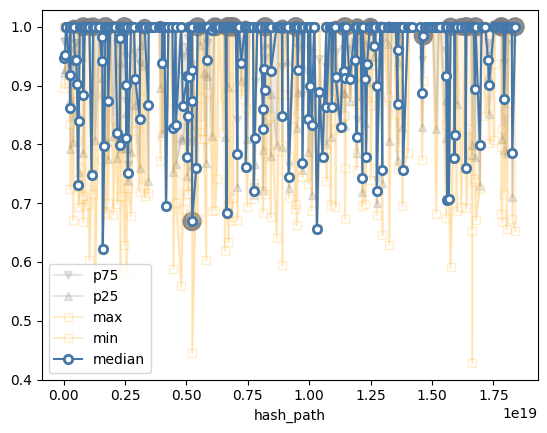

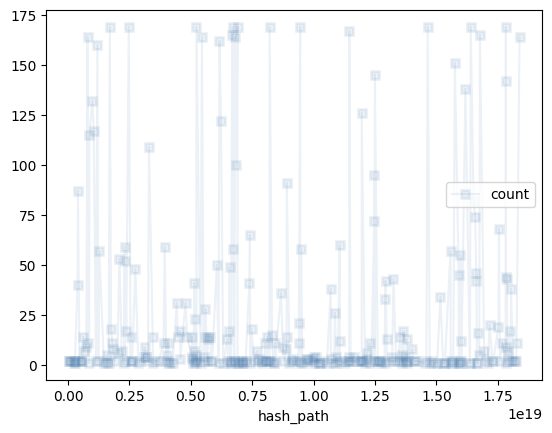

In [112]:
df = shared_data_author_dwc_t_nodes__sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

In [113]:
shared_data_author_dwc_t_nodes__sim_text__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,2,2,0.041696,0.524897,0.566593,0.483202,0.524897,0.504050,0.545745
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.246918,0.760269,1.000000,0.419757,0.824275,0.483202,1.000000
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,14,14,0.252923,0.782424,1.000000,0.419757,1.000000,0.492633,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,59,59,0.136876,0.934475,1.000000,0.648550,1.000000,1.000000,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,169,169,0.093651,0.972965,1.000000,0.648550,1.000000,1.000000,1.000000


In [114]:
shared_data_author_dwc_t_nodes__sim_attributes__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
1589770393185182661,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[8],1,1,0.000000,0.621950,0.621950,0.621950,0.621950,0.621950,0.621950
10312634465911785389,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field,1,1,0.000000,0.655420,0.655420,0.655420,0.655420,0.655420,0.655420
5227831486160219788,.,169,169,0.163558,0.796019,1.000000,0.445228,0.668868,0.668868,1.000000
6633044823982244110,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[32],1,1,0.000000,0.682424,0.682424,0.682424,0.682424,0.682424,0.682424
4166473755248203668,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[35],1,1,0.000000,0.694667,0.694667,0.694667,0.694667,0.694667,0.694667
15616206012361833326,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],1,1,0.000000,0.705396,0.705396,0.705396,0.705396,0.705396,0.705396
15687683872871601652,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[34],1,1,0.000000,0.707864,0.707864,0.707864,0.707864,0.707864,0.707864
12746096366820304841,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[4],2,2,0.040303,0.719857,0.760159,0.679554,0.719857,0.699706,0.740008
7741584035691069954,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}field[5],2,2,0.013297,0.721095,0.734392,0.707798,0.721095,0.714446,0.727743


### Inspections EML

#### Setting the stage

In [115]:
%%sql 
-- shared ancestor paths Data X Author X? GT
SELECT COUNT(1), sd.data_has_text, sd.author_has_text, gt.has_text
FROM shared_data_author_eml_nodes AS sd
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
GROUP BY 2,3,4

Running query in 'duckdb'

,count(1),data_has_text,author_has_text,has_text
0,124,False,False,False
1,21,True,False,<NA>
2,30,False,True,<NA>
3,2102,False,False,<NA>
4,1599,True,True,<NA>


In [116]:
%%sql triple_equivalence_breakdown <<
-- counts of similarity triples: DxA, DxGT, AxGT
SELECT sd.data_text = sd.author_text, sd.data_text = gt.text, sd.author_text = gt.text, COUNT(1) AS cnt
FROM shared_data_author_eml_nodes AS sd
LEFT JOIN gt_eml_data_nodes AS gt
    ON sd.path = gt.path
    AND sd.case_id = gt.case_id
WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

In [117]:
triple_equivalence_breakdown

,(sd.data_text = sd.author_text),"(sd.data_text = gt.""text"")","(sd.author_text = gt.""text"")",cnt
0,False,True,False,16
1,True,True,True,21
2,False,False,True,46
3,True,False,False,166
4,False,False,False,351


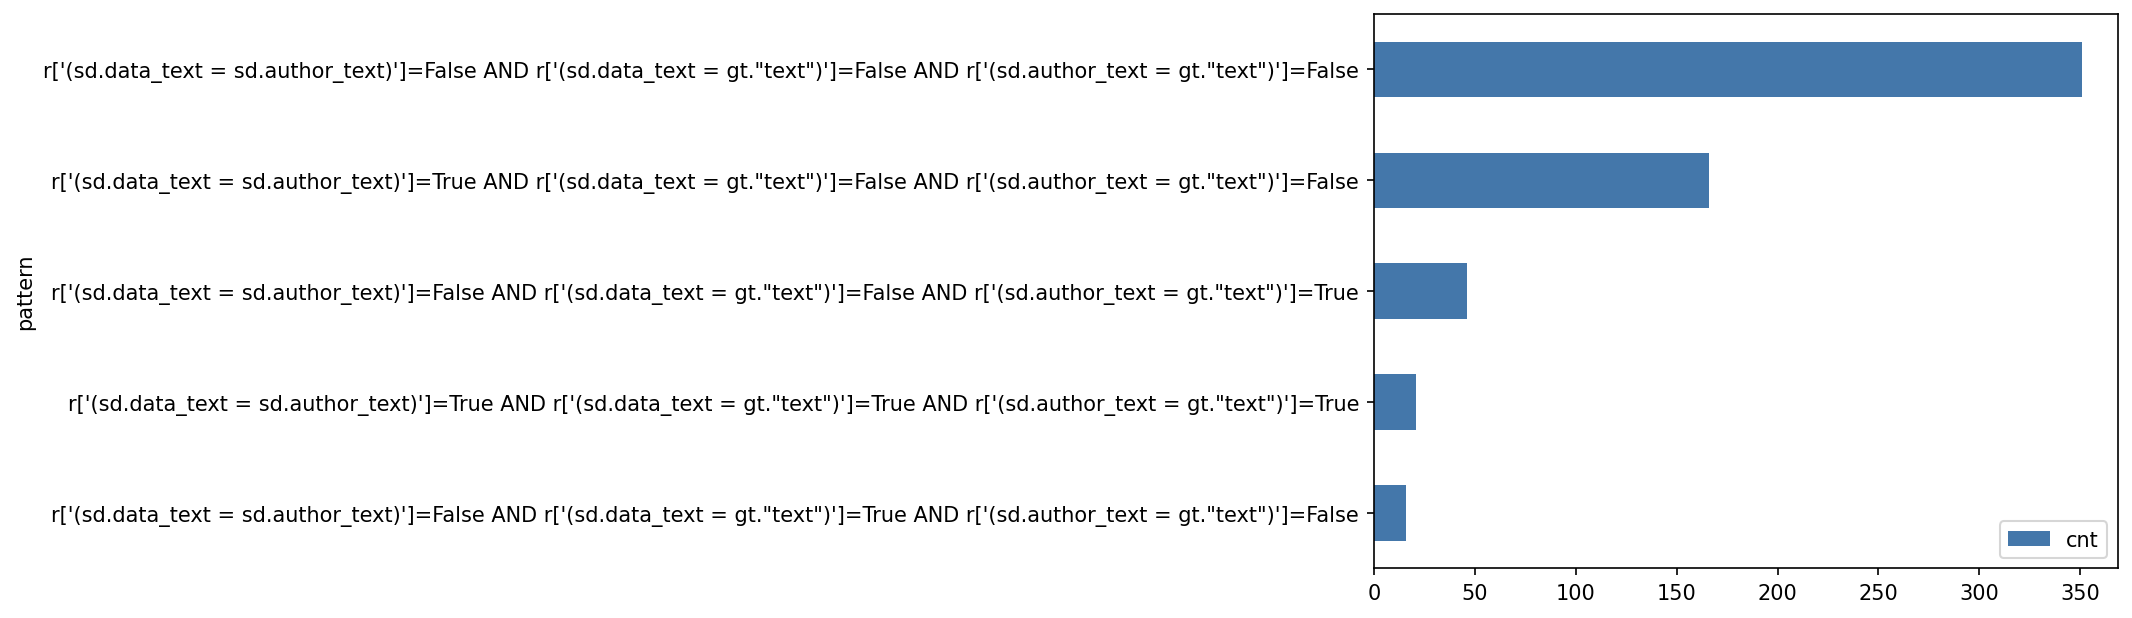

In [118]:
triple_equivalence_breakdown["pattern"] = triple_equivalence_breakdown.apply(
    lambda r: f"{r['(sd.data_text = sd.author_text)']=} AND {r['(sd.data_text = gt."text")']=} AND {r['(sd.author_text = gt."text")']=}",
    axis = 1
)
fig, ax = plt.subplots(dpi=150)
triple_equivalence_breakdown.plot.barh(x="pattern", y="cnt", ax=ax)
plt.show()

In [119]:
%%sql shared_data_author_eml_nodes__with_gt <<
-- similarity scores: DxA, DxGT, AxGT
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS
    shared_data_author_eml_nodes__with_gt AS (
    SELECT 
        *, gt.text as gt_text, 
        cos_sim(sd.data_text, gt.text) AS cos_sim_data_gt, 
        cos_sim(sd.author_text, gt.text) AS cos_sim_author_gt,
        cos_sim(sd.data_text, sd.author_text) AS cos_sim_data_author,
    FROM shared_data_author_eml_nodes AS sd
    LEFT JOIN gt_eml_data_nodes AS gt
        ON sd.path = gt.path
        AND sd.case_id = gt.case_id
    WHERE sd.data_has_text AND sd.author_has_text AND gt.has_text
);
SELECT * FROM shared_data_author_eml_nodes__with_gt;

Running query in 'duckdb'

In [120]:
shared_data_author_eml_nodes__with_gt

,column00,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,...,attributes_2,attributes_count_2,has_attributes_2,text_2,has_text_2,path_2,gt_text,cos_sim_data_gt,cos_sim_author_gt,cos_sim_data_author
0,2,0,title,2,0,True,{},0,False,not-derived-001,...,"{""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",1,True,Coastal Grassland Vegetation Records from São Miguel Island (Azores) and Mainland Portugal,True,dataset/title,Coastal Grassland Vegetation Records from São Miguel Island (Azores) and Mainland Portugal,-0.019981,0.028415,0.071817
1,35,0,maintenanceUpdateFrequency,3,0,True,{},0,False,not-derived-011,...,{},0,False,unknown,True,dataset/maintenance/maintenanceUpdateFrequency,unknown,0.028402,0.028402,1.000000
2,14,0,para,5,0,True,{},0,False,not-derived-006,...,{},0,False,"A Photographic Camera were used to take 30 pictures of vegetation coverage, at 5-meter intervals, and at 1,2 meters high from the ground, for a total of 930 photos. All pictures were analyzed latter, one by one in a computer, to confirm some species.",True,dataset/methods/qualityControl/description/para,"A Photographic Camera were used to take 30 pictures of vegetation coverage, at 5-meter intervals, and at 1,2 meters high from the ground, for a total of 930 photos. All pictures were analyzed latter, one by one in a computer, to confirm some species.",0.042784,0.320634,0.102530
3,16,0,title,3,0,True,{},0,False,Renato_PhD,...,{},0,False,Phenotypic Plasticity of Pest and Biological Control Agents: Contrasting Mainland and Insular Coastal Ecosystems,True,dataset/project/title,Phenotypic Plasticity of Pest and Biological Control Agents: Contrasting Mainland and Insular Coastal Ecosystems,0.007301,0.007301,1.000000
4,19,0,surName,5,0,True,{},0,False,Calado,...,{},0,False,Borges,True,dataset/project/personnel[1]/individualName/surName,Borges,0.189881,0.189881,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,6313,98,title,2,0,True,{},0,False,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,...,"{""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",1,True,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,True,dataset/title,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,1.000000,1.000000,1.000000
596,6354,98,maintenanceUpdateFrequency,3,0,True,{},0,False,irregular,...,{},0,False,annually,True,dataset/maintenance/maintenanceUpdateFrequency,annually,0.222871,0.026817,0.083678
597,6328,98,para,5,0,True,{},0,False,"Quality control included standardized identifiers linking event, occurrence, and measurement records; use of consistent taxonomic names; and spatial referencing in a common geographic datum (EPSG:4326). Detailed validation, duplicate handling, and transcription checks are not specified in the source context.",...,{},0,False,"For the abundance count, and to reduce possible bias among observers, criteria for the correct identification of individuals were established and practiced prior to sampling for each field campaign. In general, the results obtained from the beginning were quite coincident and without inter-observer bias. Each year, sampling was carried out by 2-4 observers, with at least one of them present in all the samplings.\nPlants for almost all species found where sampled and determined at lab. Data where carefully implemented in a database and cross-check validations were carried out.",True,dataset/methods/qualityControl/description/para,"For the abundance count, and to reduce possible bias among observers, criteria for the correct identification of individuals were established and practiced prior to sampling for each field campaign. In general, the results obtained from the beginning were quite coincident and without inter-observer bias. Each year, sampling was carried out by 2-4 observers, with at least 

In [121]:
%%sql 
SELECT 
    data_text, author_text, gt_text,
    cos_sim_data_gt, cos_sim_author_gt, cos_sim_data_author
FROM shared_data_author_eml_nodes__with_gt;

Running query in 'duckdb'

,data_text,author_text,gt_text,cos_sim_data_gt,cos_sim_author_gt,cos_sim_data_author
0,not-derived-001,Renato_PhD,Coastal Grassland Vegetation Records from São Miguel Island (Azores) and Mainland Portugal,-0.019981,0.028415,0.071817
1,not-derived-011,not-derived-011,unknown,0.028402,0.028402,1.000000
2,not-derived-006,Inferred from standardized georeferencing and structured taxonomic fields; no formal QA/QC protocol documented,"A Photographic Camera were used to take 30 pictures of vegetation coverage, at 5-meter intervals, and at 1,2 meters high from the ground, for a total of 930 photos. All pictures were analyzed latter, one by one in a computer, to confirm some species.",0.042784,0.320634,0.102530
3,Renato_PhD,Renato_PhD,Phenotypic Plasticity of Pest and Biological Control Agents: Contrasting Mainland and Insular Coastal Ecosystems,0.007301,0.007301,1.000000
4,Calado,Calado,Borges,0.189881,0.189881,1.000000
...,...,...,...,...,...,...
595,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,1.000000,1.000000,1.000000
596,irregular,not-derived-011,annually,0.222871,0.026817,0.083678
597,"Quality control included standardized identifiers linking event, occurrence, and measurement records; use of consistent taxonomic names; and spatial referencing in a common geographic datum (EPSG:4326). Detailed validation, duplicate handling, and transcription checks are not specified in the source context.","No explicit QA/QC procedure was documented beyond the recorded methods and standardized vocabulary references; records were checked through database implementation, cross-check validations, and taxonomic and spatial validations, with plot coordinates verified using GPS and UAV orthophotos.","For the abundance count, and to reduce possible bias among observers, criteria for the correct identification of individuals were established and practiced prior to sampling for each field campaign. In general, the results obtained from the beginning were quite coincident and without inter-observer bias. Each year, sampling was carried out by 2-4 observers, with at least one of them present in all the samplings.\nPlants for almost all species found where sampled and determined at lab. Data where carefully implemented in a database and cross-check validations were carried out.",0.374744,0.369030,0.489892
598,Monitoring of herbivory effects in Androcymbium europaeum pasture plots,not-derived-006,Ganadería Extensiva y Biodiversidad,0.089546,0.043159,0.009194


In [122]:
%%sql 
SELECT 
    data_text, count(1)
FROM shared_data_author_eml_nodes__with_gt
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,data_text,count(1)
0,MOVECLIM-AZO,1
1,Li,1
2,updated on publication/curation changes,1
3,georreferenciación,1
4,IMOST,1
...,...,...
221,not-derived-006,34
222,not-derived-007,41
223,not-derived-001,43
224,not-derived-008,47


In [123]:
%%sql 
SELECT 
    author_text, count(1)
FROM shared_data_author_eml_nodes__with_gt
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,author_text,count(1)
0,Monitoring data on the effect of domestic livestock and rabbits on Androcymbium europaeum pastures,1
1,University of Caldas amphibian collection digitization and georeferencing effort,1
2,"All tagged photos were double-checked by the authors for species identification; initial identification errors were corrected in a second verification, reducing the final error rate to nearly 0%; potential data gaps such as missing temperature information were checked; and photos of humans were systematically removed from the dataset.",1
3,"Quality control appears to have included standardized plot/quadrat sampling, consistent event-level naming, geospatial recording with WGS84 coordinates, coordinate uncertainty documentation, and taxonomic verification by named identifiers. Additional record-level QC details are not provided in the source context and should be supplied if available.",1
4,Insectivorous bat activity dataset across different land-use types in the Islands of São Tomé and Príncipe,1
...,...,...
323,not-derived-007,20
324,not-derived-006,24
325,not-derived-008,26
326,not-derived-001,31


In [124]:
%%sql 
-- How many have failed to derive text using `data`?
-- ==> we observe more fails in data
SELECT 
    data_text ^@ 'not-derived', count(1)
FROM shared_data_author_eml_nodes__with_gt
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,(data_text ^@ 'not-derived'),count(1)
0,False,269
1,True,331


In [125]:
%%sql 
-- How many have failed to derive text using `author`?
-- ==> we observe less fails in author
SELECT 
    author_text ^@ 'not-derived', count(1)
FROM shared_data_author_eml_nodes__with_gt
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,(author_text ^@ 'not-derived'),count(1)
0,True,225
1,False,375


In [126]:
%%sql sim_per_case_eml_text__inspect_sims << 
CREATE
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    sim_per_case_eml_text__inspect_sims AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_eml_nodes__with_gt as c
    GROUP BY c.case_id
);
SELECT * FROM sim_per_case_eml_text__inspect_sims;

Running query in 'duckdb'

In [127]:
%%sql sim_per_path_eml_text__inspect_sims << 
CREATE
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    sim_per_path_eml_text__inspect_sims AS (
    SELECT
        c.path,
        COUNT(1) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_eml_nodes__with_gt as c
    GROUP BY c.path
);
SELECT * FROM sim_per_path_eml_text__inspect_sims;

Running query in 'duckdb'

In [128]:
%%sql path_count_to_avg_medians <<
-- We check if the similarity relates to the size of metadata
WITH sim_per_case_eml_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_eml_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT 
    path_count, COUNT(1) AS cnt, AVG(ds_med_cont_d_gt) AS avg_median_d_gt, AVG(ds_med_cont_a_gt) AS avg_median_a_gt
FROM sim_per_case_eml_text
GROUP BY 1
ORDER BY 1;

Running query in 'duckdb'

In [129]:
path_count_to_avg_medians

,path_count,cnt,avg_median_d_gt,avg_median_a_gt
0,1,2,0.364730,0.186797
1,2,22,0.279693,0.349515
2,3,15,0.099496,0.256907
3,4,16,0.223606,0.265430
4,5,26,0.132028,0.298183
5,6,18,0.129949,0.255528
6,7,7,0.207748,0.346123
7,8,8,0.127080,0.273353
8,9,7,0.182062,0.239126
9,10,2,0.262189,0.299317


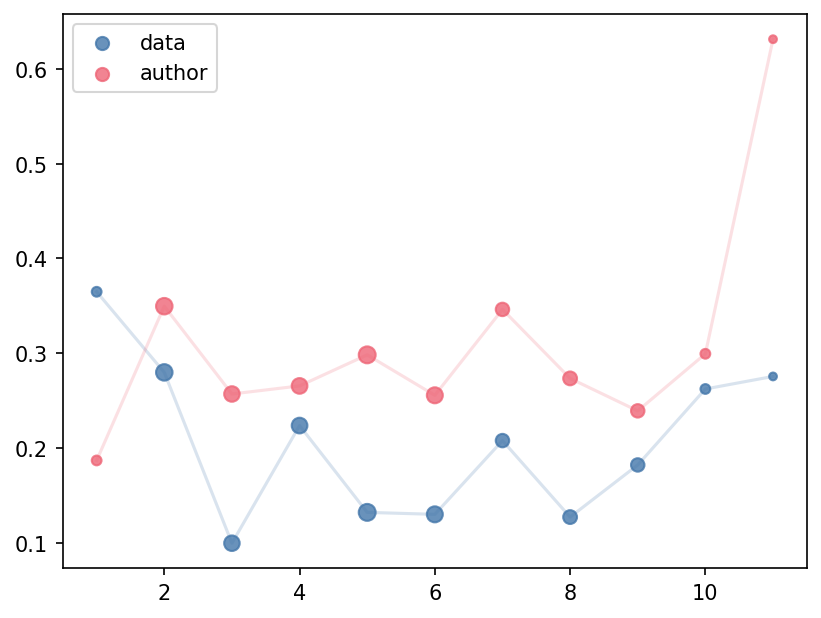

In [130]:
fig,ax = plt.subplots(dpi=150)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_d_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_d_gt"], 
    sizes=np.log1p(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="data"
)
ax.plot(
    path_count_to_avg_medians["path_count"], 
    path_count_to_avg_medians["avg_median_a_gt"],
    alpha=0.2
)
ax.scatter(
    x=path_count_to_avg_medians["path_count"], 
    y=path_count_to_avg_medians["avg_median_a_gt"], 
    sizes=np.log1p(path_count_to_avg_medians["cnt"]) * 20,
    alpha=0.8,
    label="author"
)
ax.legend()
plt.show()

In [131]:
%%sql
-- regression testing correlation between case size and similarity
-- ==> shows no strong connection
WITH sim_per_case_eml_text AS (
    SELECT
        c.case_id,
        COUNT(case_id) as path_count,
        stddev_pop(cos_sim_data_gt) as ds_std_pop_d_gt,
        stddev_pop(cos_sim_author_gt) as ds_std_pop_a_gt,
        AVG(cos_sim_data_gt) as ds_mean_d_gt,
        AVG(cos_sim_author_gt) as ds_mean_a_gt,
        MAX(cos_sim_data_gt) as ds_max_d_gt,
        MAX(cos_sim_author_gt) as ds_max_a_gt,
        MIN(cos_sim_data_gt) as ds_min_d_gt,
        MIN(cos_sim_author_gt) as ds_min_a_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_med_cont_d_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p25_cont_d_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_data_gt) AS ds_p75_cont_d_gt,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_med_cont_a_gt,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p25_cont_a_gt,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_author_gt) AS ds_p75_cont_a_gt,
    FROM shared_data_author_eml_nodes__with_gt as c
    GROUP BY c.case_id
)
SELECT regr_r2(ds_med_cont_d_gt, path_count), regr_r2(ds_med_cont_d_gt, path_count)
FROM sim_per_case_eml_text

Running query in 'duckdb'

,"regr_r2(ds_med_cont_d_gt, path_count)","regr_r2(ds_med_cont_d_gt, path_count)_1"
0,0.013913,0.013913


#### Text

In [132]:
# those shared with D x A (two-way join)
shared_data_author_eml_nodes__sim_text["path"].unique()

<StringArray>
[                                                     'dataset/title',
                             'dataset/creator/individualName/surName',
                                             'dataset/creator/userId',
                    'dataset/methods/qualityControl/description/para',
                                              'dataset/project/title',
                'dataset/project/personnel[1]/individualName/surName',
                                  'dataset/project/personnel[1]/role',
                'dataset/project/personnel[2]/individualName/surName',
                                  'dataset/project/personnel[2]/role',
                                       'dataset/project/funding/para',
 'dataset/project/studyAreaDescription/descriptor[1]/descriptorValue',
 'dataset/project/studyAreaDescription/descriptor[2]/descriptorValue',
                               'dataset/maintenance/description/para',
                     'dataset/maintenance/maintenanceUpdateFreq

In [133]:
# those shared with D x A x GT (three-way join)
sim_per_path_eml_text__inspect_sims["path"].unique()

<StringArray>
[                              'dataset/project/personnel[1]/role',
                                           'dataset/project/title',
                            'dataset/maintenance/description/para',
                                                   'dataset/title',
                'dataset/project/personnel/individualName/surName',
                 'dataset/methods/qualityControl/description/para',
                  'dataset/maintenance/maintenanceUpdateFrequency',
             'dataset/project/personnel[3]/individualName/surName',
             'dataset/project/personnel[1]/individualName/surName',
                               'dataset/project/personnel[2]/role',
                          'dataset/creator/individualName/surName',
                     'dataset/methods/methodStep/description/para',
                                  'dataset/project/personnel/role',
                                    'dataset/project/funding/para',
                  'dataset/methods

In [134]:
# Agreement between data and author texts
print(shared_data_author_eml_nodes__sim_text.shape)
print(shared_data_author_eml_nodes__sim_text[shared_data_author_eml_nodes__sim_text["cos_sim_text"] == 1].shape)
print(shared_data_author_eml_nodes__sim_text[shared_data_author_eml_nodes__sim_text["cos_sim_text"] < 1].shape)

(1599, 5)
(556, 5)
(1039, 5)


In [135]:
sim_per_case_eml_text__inspect_sims.describe()

,case_id,path_count,ds_std_pop_d_gt,ds_std_pop_a_gt,ds_mean_d_gt,ds_mean_a_gt,ds_max_d_gt,ds_max_a_gt,ds_min_d_gt,ds_min_a_gt,ds_med_cont_d_gt,ds_p25_cont_d_gt,ds_p75_cont_d_gt,ds_med_cont_a_gt,ds_p25_cont_a_gt,ds_p75_cont_a_gt
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,91.322581,4.838710,0.186350,0.284160,0.230238,0.358320,0.518389,0.784856,0.034881,0.064200,0.179595,0.102956,0.329758,0.290557,0.156350,0.507378
std,52.773261,2.242919,0.133436,0.120674,0.202223,0.182581,0.357672,0.304171,0.163096,0.146573,0.205242,0.171856,0.278372,0.224079,0.171200,0.263105
min,0.000000,1.000000,0.000000,0.000000,-0.034160,-0.008390,0.006133,-0.008390,-0.113820,-0.094472,-0.038406,-0.057667,-0.014899,-0.008390,-0.034624,-0.008390
25%,46.750000,3.000000,0.066744,0.225846,0.086637,0.256317,0.178660,0.633590,-0.030777,-0.008079,0.055518,0.026560,0.109893,0.118984,0.045818,0.313516
50%,91.500000,5.000000,0.146866,0.310259,0.176560,0.356794,0.465759,0.994919,0.008705,0.028402,0.101159,0.043266,0.237251,0.229100,0.099849,0.510467
75%,137.250000,6.000000,0.306003,0.369108,0.322719,0.468434,0.933845,1.000000,0.040558,0.073762,0.225355,0.099347,0.528681,0.431410,0.217657,0.712889
max,178.000000,11.000000,0.501108,0.478997,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [136]:
shared_data_author_eml_nodes__sim_text[shared_data_author_eml_nodes__sim_text["cos_sim_text"] < 1].describe()

,case_id,cos_sim_text
count,1039.000000,1039.000000
mean,91.442733,0.314702
std,52.969093,0.320903
min,0.000000,-0.140305
25%,47.000000,0.061691
50%,92.000000,0.170095
75%,138.000000,0.566176
max,178.000000,0.994672


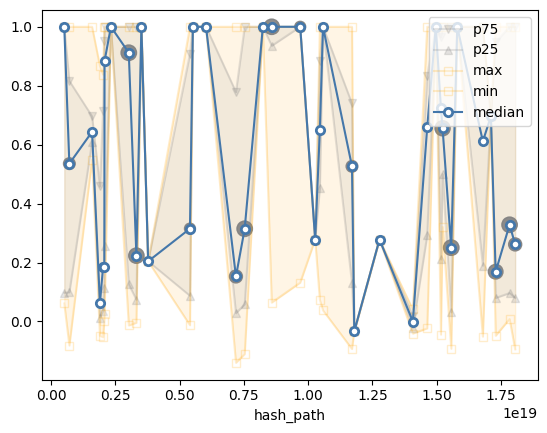

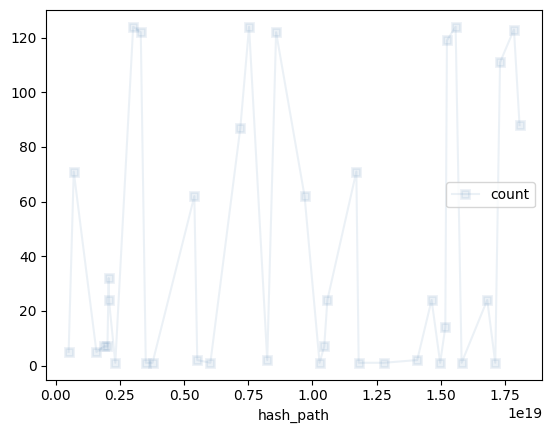

In [137]:
df = shared_data_author_eml_nodes__sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="upper right")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

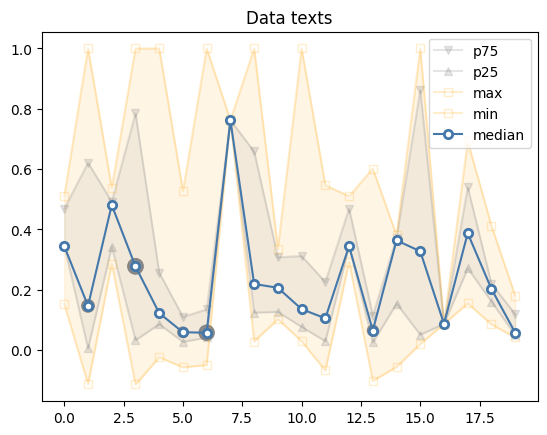

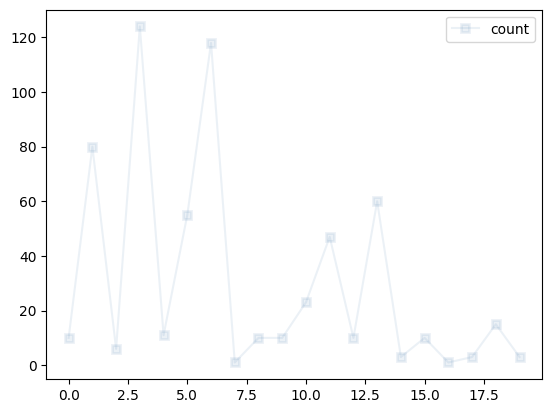

In [138]:
df = sim_per_path_eml_text__inspect_sims
plt.title("Data texts")
plt.fill_between(df.index, df["ds_max_d_gt"], df["ds_min_d_gt"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont_d_gt"], df["ds_p25_cont_d_gt"], color="gray", alpha=0.1)
df["ds_p75_cont_d_gt"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont_d_gt"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min_d_gt'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max_d_gt'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont_d_gt'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont_d_gt'], sizes=(df['path_count']), color="gray", alpha=0.9)
plt.legend(loc="upper right")
plt.show()
df['path_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

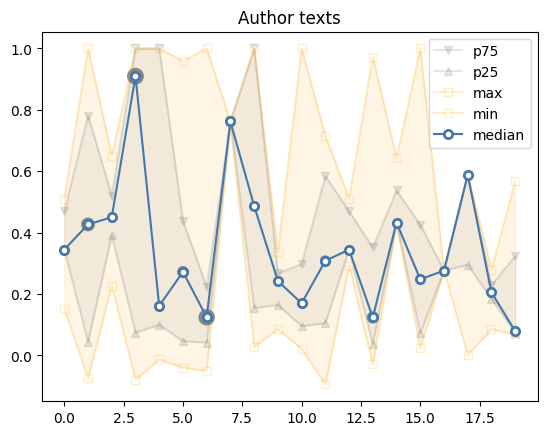

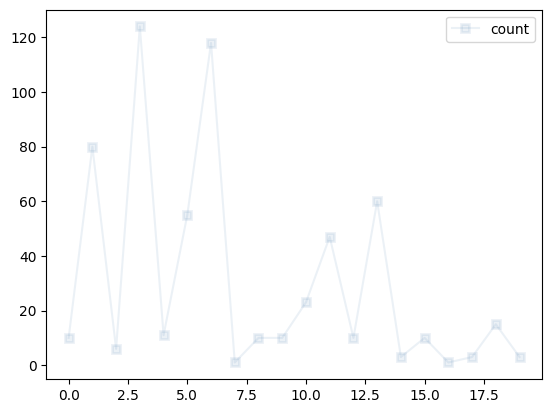

In [139]:
df = sim_per_path_eml_text__inspect_sims
plt.title("Author texts")
plt.fill_between(df.index, df["ds_max_a_gt"], df["ds_min_a_gt"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont_a_gt"], df["ds_p25_cont_a_gt"], color="gray", alpha=0.1)
df["ds_p75_cont_a_gt"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont_a_gt"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min_a_gt'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max_a_gt'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont_a_gt'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont_a_gt'], sizes=(df['path_count']), color="gray", alpha=0.9)
plt.legend(loc="upper right")
plt.show()
df['path_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

In [140]:
sorted(sim_per_path_eml_text__inspect_sims["path"].unique().tolist())

['dataset/creator/individualName/surName',
 'dataset/creator/userId',
 'dataset/maintenance/description/para',
 'dataset/maintenance/maintenanceUpdateFrequency',
 'dataset/methods/methodStep/description/para',
 'dataset/methods/methodStep[1]/description/para',
 'dataset/methods/methodStep[2]/description/para',
 'dataset/methods/qualityControl/description/para',
 'dataset/project/funding/para',
 'dataset/project/personnel/individualName/surName',
 'dataset/project/personnel/role',
 'dataset/project/personnel[1]/individualName/surName',
 'dataset/project/personnel[1]/role',
 'dataset/project/personnel[2]/individualName/surName',
 'dataset/project/personnel[2]/role',
 'dataset/project/personnel[3]/individualName/surName',
 'dataset/project/personnel[3]/role',
 'dataset/project/studyAreaDescription/descriptor/descriptorValue',
 'dataset/project/title',
 'dataset/title']

In [141]:
sim_per_path_eml_text__inspect_sims

,path,path_count,ds_std_pop_d_gt,ds_std_pop_a_gt,ds_mean_d_gt,ds_mean_a_gt,ds_max_d_gt,ds_max_a_gt,ds_min_d_gt,ds_min_a_gt,ds_med_cont_d_gt,ds_p25_cont_d_gt,ds_p75_cont_d_gt,ds_med_cont_a_gt,ds_p25_cont_a_gt,ds_p75_cont_a_gt
0,dataset/project/personnel[1]/role,10,0.106838,0.111296,0.371124,0.365858,0.510540,0.510540,0.152777,0.152777,0.344871,0.344871,0.469123,0.344871,0.344871,0.469123
1,dataset/project/title,80,0.358371,0.379665,0.306579,0.427838,1.000000,1.000000,-0.112540,-0.073552,0.146693,0.005936,0.621112,0.426749,0.044439,0.781653
2,dataset/maintenance/description/para,6,0.098705,0.131330,0.429992,0.448990,0.537901,0.650771,0.286467,0.227382,0.481073,0.343225,0.492391,0.450402,0.391787,0.519651
3,dataset/title,124,0.396357,0.429715,0.387484,0.639372,1.000000,1.000000,-0.113820,-0.078826,0.277770,0.033182,0.784712,0.909653,0.074548,1.000000
4,dataset/project/personnel/individualName/surName,11,0.273415,0.450610,0.217509,0.508633,1.000000,1.000000,-0.023587,-0.012853,0.122778,0.086200,0.256705,0.161725,0.100061,1.000000
5,dataset/methods/qualityControl/description/para,55,0.117194,0.267427,0.092833,0.284398,0.526760,0.959998,-0.056822,-0.039400,0.059303,0.027404,0.110400,0.272391,0.046740,0.438784
6,dataset/maintenance/maintenanceUpdateFrequency,118,0.173285,0.173539,0.118079,0.170302,1.000000,1.000000,-0.049402,-0.049402,0.057726,0.042006,0.134941,0.124283,0.042006,0.222412
7,dataset/project/personnel[3]/individualName/surName,1,0.000000,0.000000,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364,0.762364
8,dataset/project/personnel[1]/individualName/surName,10,0.365975,0.423764,0.386340,0.539879,1.000000,1.000000,0.028613,0.028613,0.219372,0.124401,0.658520,0.487022,0.154463,1.000000
9,dataset/project/personnel[2]/role,10,0.094765,0.078997,0.215012,0.228143,0.336394,0.336352,0.102782,0.085831,0.206704,0.126978,0.307810,0.242751,0.164693,0.267709


In [142]:
# those where data performed better are higher
sim_per_path_eml_text__inspect_sims.sort_values(by=["ds_med_cont_d_gt"], ascending=False)[
    ["path", "path_count", "ds_med_cont_d_gt", "ds_med_cont_a_gt", "ds_max_d_gt", "ds_max_a_gt"]
]

,path,path_count,ds_med_cont_d_gt,ds_med_cont_a_gt,ds_max_d_gt,ds_max_a_gt
7,dataset/project/personnel[3]/individualName/surName,1,0.762364,0.762364,0.762364,0.762364
2,dataset/maintenance/description/para,6,0.481073,0.450402,0.537901,0.650771
17,dataset/methods/methodStep[1]/description/para,3,0.387579,0.588148,0.692254,0.589546
14,dataset/methods/methodStep[2]/description/para,3,0.363969,0.433076,0.380618,0.641698
0,dataset/project/personnel[1]/role,10,0.344871,0.344871,0.510540,0.510540
12,dataset/project/personnel/role,10,0.344871,0.344871,0.510540,0.510540
15,dataset/project/personnel[2]/individualName/surName,10,0.327629,0.247913,1.000000,1.000000
3,dataset/title,124,0.277770,0.909653,1.000000,1.000000
8,dataset/project/personnel[1]/individualName/surName,10,0.219372,0.487022,1.000000,1.000000
9,dataset/project/personnel[2]/role,10,0.206704,0.242751,0.336394,0.336352


In [143]:
# those where author performed better are higher
sim_per_path_eml_text__inspect_sims.sort_values(by=["ds_med_cont_a_gt"], ascending=False)[
    ["path", "path_count", "ds_med_cont_d_gt", "ds_med_cont_a_gt", "ds_max_d_gt", "ds_max_a_gt"]
]

,path,path_count,ds_med_cont_d_gt,ds_med_cont_a_gt,ds_max_d_gt,ds_max_a_gt
3,dataset/title,124,0.277770,0.909653,1.000000,1.000000
7,dataset/project/personnel[3]/individualName/surName,1,0.762364,0.762364,0.762364,0.762364
17,dataset/methods/methodStep[1]/description/para,3,0.387579,0.588148,0.692254,0.589546
8,dataset/project/personnel[1]/individualName/surName,10,0.219372,0.487022,1.000000,1.000000
2,dataset/maintenance/description/para,6,0.481073,0.450402,0.537901,0.650771
14,dataset/methods/methodStep[2]/description/para,3,0.363969,0.433076,0.380618,0.641698
1,dataset/project/title,80,0.146693,0.426749,1.000000,1.000000
0,dataset/project/personnel[1]/role,10,0.344871,0.344871,0.510540,0.510540
12,dataset/project/personnel/role,10,0.344871,0.344871,0.510540,0.510540
11,dataset/methods/methodStep/description/para,47,0.105464,0.308343,0.546387,0.715284


In [144]:
shared_data_author_eml_nodes__sim_text__path_inspect.sort_values(by=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
11797055351399041090,dataset/project/abstract/para,1,1,0.000000,-0.033338,-0.033338,-0.033338,-0.033338,-0.033338,-0.033338
14075849902049915488,dataset/project/studyAreaDescription/descriptor[3]/descriptorValue,2,2,0.040895,-0.000308,0.040587,-0.041203,-0.000308,-0.020755,0.020140
1897832894039290149,dataset/methods/methodStep[1]/description/para,7,7,0.356680,0.260279,0.866275,-0.048814,0.061705,0.013307,0.458088
7191309023196111392,dataset/methods/methodStep/description/para,87,87,0.402133,0.363468,1.000000,-0.140305,0.152646,0.027980,0.778725
17299146993214317173,dataset/methods/qualityControl/description/para,111,111,0.402947,0.386541,1.000000,-0.048544,0.168804,0.079673,0.947337
2019908457384792944,dataset/methods/methodStep[2]/description/para,7,7,0.360038,0.352727,0.837763,-0.053558,0.184812,0.035197,0.714839
2068281925885941007,additionalMetadata/metadata,32,32,0.380010,0.381493,1.000000,0.000302,0.185584,0.114107,0.953267
3774517024663899732,additionalMetadata/metadata/customMetadata/provenanceNote,1,1,0.000000,0.204093,0.204093,0.204093,0.204093,0.204093,0.204093
3316978768188658723,dataset/maintenance/maintenanceUpdateFrequency,122,122,0.436868,0.483997,1.000000,-0.004451,0.223308,0.073879,1.000000


In [184]:
shared_data_gt_eml_nodes__sim_text

,case_id,path,data_text,gt_text,cos_sim_text
0,0,dataset/title,not-derived-001,Coastal Grassland Vegetation Records from São Miguel Island (Azores) and Mainland Portugal,-0.019981
1,0,dataset/maintenance/maintenanceUpdateFrequency,not-derived-011,unknown,0.028402
2,0,dataset/methods/methodStep/description/para,WGS84,"In the laboratory, all photos were organized in a photographic database to facilitate taxonomic identification. All morphospecies were identified using the Azorean Biodiversity database, Flora-On database, to the species level when possible.",0.104229
3,0,dataset/methods/qualityControl/description/para,not-derived-006,"A Photographic Camera were used to take 30 pictures of vegetation coverage, at 5-meter intervals, and at 1,2 meters high from the ground, for a total of 930 photos. All pictures were analyzed latter, one by one in a computer, to confirm some species.",0.042784
4,0,dataset/project/title,Renato_PhD,Phenotypic Plasticity of Pest and Biological Control Agents: Contrasting Mainland and Insular Coastal Ecosystems,0.007301
...,...,...,...,...,...
859,98,dataset/project/personnel[1]/role,Principal Investigator,principalInvestigator,0.510540
860,98,dataset/project/personnel[2]/individualName/surName,not-derived-004,Ramos Font,0.151155
861,98,dataset/project/personnel[2]/role,Field Technician,custodianSteward,0.149297
862,98,dataset/project/funding/para,not-derived-005,"These data have been generated thanks to the funding of different projects, although the first samplings and the installation of the exclusion plots were funded by the Consejería de Medio Ambiente de la Junta de Andalucía through the ""Ganadería Extensiva y Biodiversidad"" project from 2008 to 2014. From this date on it was financed through the CSIC intramural projects ""Investigaciones sobre flora forrajera bética: prospección de especies, protocolo para su establecimiento en campo y valoración nutritiva"" and ""Pastoralismo y Medioambiente"". From 2021 onwards, funding for monitoring came from the SUMHAL project (LIFEWATCH-2019-09-CSIC-13, POPE 2014-2020).",0.078534


In [190]:
display(shared_data_gt_eml_nodes__sim_text__path_inspect)
display(shared_author_gt_eml_nodes__sim_text__path_inspect)

,path,hash_path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,dataset/project/personnel[1]/role,10579610229072948010,18,18,0.110259,0.371270,0.510540,0.152777,0.344871,0.344871,0.500554
1,dataset/abstract/para,12264083121720851709,11,11,0.249966,0.426243,0.753914,0.014032,0.518044,0.214920,0.622663
2,dataset/methods/sampling/studyExtent/description/para,10239635456906091571,3,3,0.282113,0.407178,0.742643,0.052417,0.426475,0.239446,0.584559
3,dataset/intellectualRights/para,402660203177841723,1,1,0.000000,0.448450,0.448450,0.448450,0.448450,0.448450,0.448450
4,dataset/project/personnel[5]/individualName/surName,1648524699013299504,2,2,0.020219,0.278812,0.299031,0.258594,0.278812,0.268703,0.288922
5,dataset/methods/qualityControl/description/para,17299146993214317173,75,75,0.132915,0.097314,0.624716,-0.056822,0.053148,0.024039,0.110400
6,dataset/project/personnel/role,9691641318081825809,21,21,0.137727,0.358203,0.510540,0.083198,0.344871,0.344871,0.510540
7,dataset/methods/methodStep[2]/description/para,2019908457384792944,4,4,0.182071,0.259422,0.380618,-0.055316,0.356193,0.247484,0.368132
8,dataset/contact/individualName/surName,199826611885047600,1,1,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
9,dataset/methods/sampling/samplingDescription/para,1022270553021290504,3,3,0.311418,0.219556,0.658932,-0.026267,0.026005,-0.000131,0.342468


,path,hash_path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
0,dataset/creator/individualName/surName,17840357754191769060,28,28,0.345833,0.332244,1.000000,0.021819,0.174653,0.102197,0.386458
1,dataset/title,7531383348528985230,148,148,0.432444,0.627410,1.000000,-0.078826,0.898597,0.059959,1.000000
2,dataset/maintenance/maintenanceUpdateFrequency,3316978768188658723,142,142,0.194983,0.178412,1.000000,-0.049402,0.128193,0.042006,0.226280
3,dataset/project/personnel[2]/role,14635275423761931014,19,19,0.077124,0.217014,0.341561,0.085831,0.225492,0.152788,0.264587
4,dataset/project/abstract/para,11797055351399041090,2,2,0.305234,0.270422,0.575656,-0.034811,0.270422,0.117806,0.423039
5,dataset/methods/methodStep[1]/description/para,1897832894039290149,7,7,0.313034,0.315588,0.685324,-0.099529,0.458055,-0.006215,0.588847
6,dataset/coverage/geographicCoverage/geographicDescription,6617235638686593906,2,2,0.051234,0.569407,0.620641,0.518173,0.569407,0.543790,0.595024
7,dataset/creator/userId,8583186042160731940,17,17,0.047323,0.200261,0.279327,0.085334,0.205773,0.179985,0.223715
8,dataset/project/personnel[1]/role,10579610229072948010,19,19,0.130121,0.324028,0.510540,0.131206,0.344871,0.229844,0.427706
9,dataset/abstract/para,12264083121720851709,7,7,0.318298,0.414720,0.765518,-0.043659,0.520462,0.133193,0.697165


In [193]:
%%sql delta_cons_gt_med_cont <<
SELECT 
    dgt.path, 
    dgt.ds_med_cont - agt.ds_med_cont AS delta_ds_med_cont
FROM shared_data_gt_eml_nodes__sim_text__path_inspect as dgt
    JOIN shared_author_gt_eml_nodes__sim_text__path_inspect AS agt
    ON dgt.path = agt.path
;

Running query in 'duckdb'

<Axes: ylabel='path'>

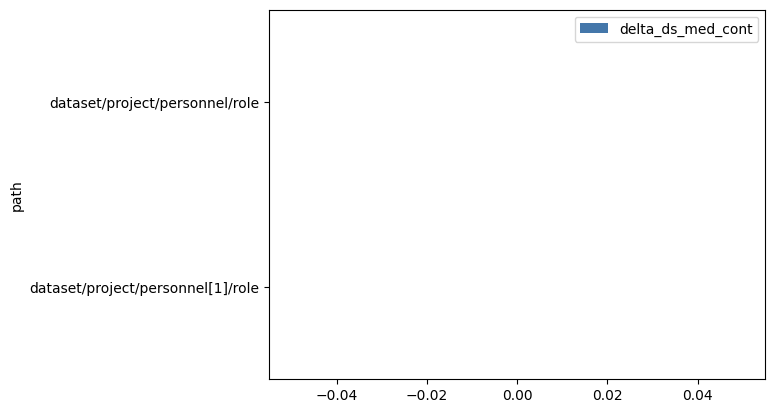

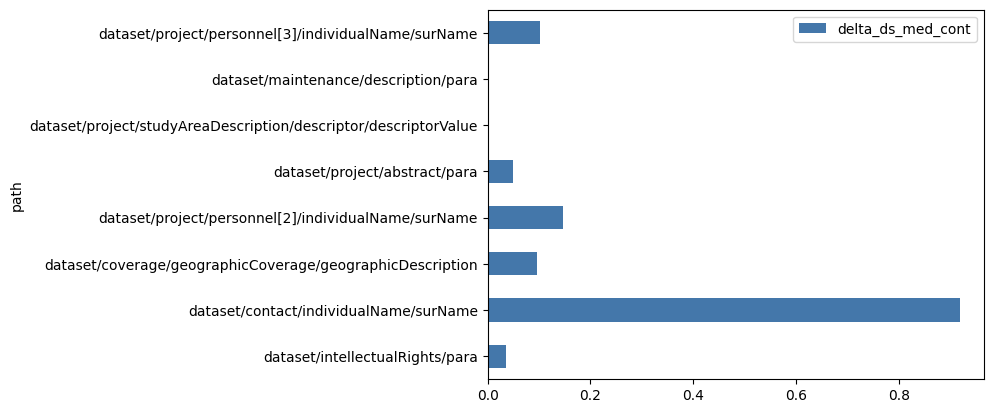

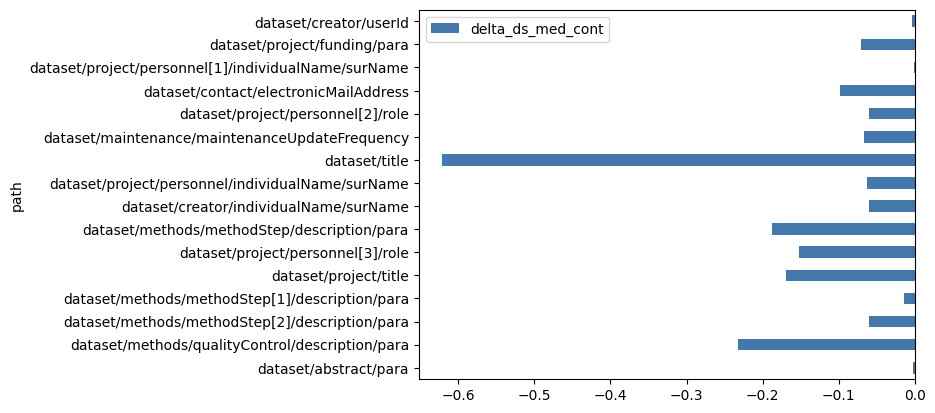

In [201]:
equal = delta_cons_gt_med_cont[delta_cons_gt_med_cont["delta_ds_med_cont"] == 0]
data_better = delta_cons_gt_med_cont[delta_cons_gt_med_cont["delta_ds_med_cont"] > 0]
author_better = delta_cons_gt_med_cont[delta_cons_gt_med_cont["delta_ds_med_cont"] < 0]

equal.plot.barh(x="path", y="delta_ds_med_cont")
data_better.plot.barh(x="path", y="delta_ds_med_cont")
author_better.plot.barh(x="path", y="delta_ds_med_cont")

In [205]:
%%sql 
-- How many have failed to derive text using `data`?
-- ==> we observe more fails in data
SELECT 
    data_text ^@ 'not-derived', count(1)
FROM shared_data_gt_eml_nodes__sim_text
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,(data_text ^@ 'not-derived'),count(1)
0,False,426
1,True,438


In [209]:
%%sql 
-- How many have failed to derive text using `author`?
-- ==> we observe more fails in data
SELECT 
    author_text ^@ 'not-derived', count(1)
FROM shared_author_gt_eml_nodes__sim_text
GROUP BY 1
ORDER BY 2;

Running query in 'duckdb'

,(author_text ^@ 'not-derived'),count(1)
0,True,313
1,False,521


In [229]:
%%sql 
-- Which paths are frequently not derived by `author`?
WITH count_not_derived AS (
    SELECT 
        path, count(1) as count_not_derived
    FROM shared_author_gt_eml_nodes__sim_text
    WHERE author_text ^@ 'not-derived'
    GROUP BY 1
), count_derived AS (
    SELECT 
        path, count(1) as count_derived
    FROM shared_author_gt_eml_nodes__sim_text
    WHERE NOT (author_text ^@ 'not-derived')
    GROUP BY 1
)
SELECT 
    cd.path, 
    (IFNULL(count_derived, 0) - IFNULL(count_not_derived, 0)), 
    (
        (IFNULL(count_derived, 0)) 
        / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
    ) * 100 AS percentage_derived, 
    count_derived, count_not_derived
FROM count_derived AS cd
    LEFT JOIN count_not_derived AS cnd
        ON cd.path = cnd.path
ORDER BY 3
;

Running query in 'duckdb'

,path,"(COALESCE(count_derived, 0) - COALESCE(count_not_derived, 0))",percentage_derived,count_derived,count_not_derived
0,dataset/creator/userId,-15,5.882353,1,16
1,dataset/project/funding/para,-11,42.857143,33,44
2,dataset/creator/individualName/surName,-2,46.428571,13,15
3,dataset/maintenance/maintenanceUpdateFrequency,-10,46.478873,66,76
4,dataset/project/personnel/individualName/surName,0,50.000000,13,13
5,dataset/project/abstract/para,0,50.000000,1,1
6,dataset/methods/methodStep[1]/description/para,1,57.142857,4,3
7,dataset/project/personnel[2]/individualName/surName,3,57.894737,11,8
8,dataset/methods/qualityControl/description/para,12,58.823529,40,28
9,dataset/methods/methodStep/description/para,18,62.500000,45,27


In [230]:
%%sql 
-- Which paths are frequently not derived by `author`?
WITH count_not_derived AS (
    SELECT 
        path, count(1) as count_not_derived
    FROM shared_data_gt_eml_nodes__sim_text
    WHERE data_text ^@ 'not-derived'
    GROUP BY 1
), count_derived AS (
    SELECT 
        path, count(1) as count_derived
    FROM shared_data_gt_eml_nodes__sim_text
    WHERE NOT (data_text ^@ 'not-derived')
    GROUP BY 1
)
SELECT 
    cd.path, 
    (IFNULL(count_derived, 0) - IFNULL(count_not_derived, 0)), 
    (
        (IFNULL(count_derived, 0)) 
        / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
    ) * 100 AS percentage_derived, 
    count_derived, count_not_derived
FROM count_derived AS cd
    LEFT JOIN count_not_derived AS cnd
        ON cd.path = cnd.path
ORDER BY 3
;

Running query in 'duckdb'

,path,"(COALESCE(count_derived, 0) - COALESCE(count_not_derived, 0))",percentage_derived,count_derived,count_not_derived
0,dataset/project/funding/para,-61,9.333333,7,68
1,dataset/project/personnel/individualName/surName,-16,19.230769,5,21
2,dataset/maintenance/maintenanceUpdateFrequency,-79,22.758621,33,112
3,dataset/creator/userId,-7,29.411765,5,12
4,dataset/methods/qualityControl/description/para,-29,30.666667,23,52
5,dataset/creator/individualName/surName,-6,40.000000,12,18
6,dataset/methods/methodStep/description/para,9,56.716418,38,29
7,dataset/project/title,15,57.425743,58,43
8,dataset/project/personnel[1]/individualName/surName,3,57.894737,11,8
9,dataset/project/personnel[2]/individualName/surName,5,63.157895,12,7


In [237]:
%%sql
SELECT *
FROM shared_data_gt_eml_nodes__sim_text
ORDER BY cos_sim_text DESC, case_id, path
LIMIT 25

Running query in 'duckdb'

,case_id,path,data_text,gt_text,cos_sim_text
0,144,dataset/project/title,Colección de vertebrados e invertebrados,Colección de Vertebrados e Invertebrados,1.0
1,20,dataset/title,"First record of Microlycus heterocerus Thomson, 1878 (Hymenoptera: Eulophidae) in the Netherlands","First record of Microlycus heterocerus Thomson, 1878 (Hymenoptera: Eulophidae) in the Netherlands",1.0
2,25,dataset/title,Dung beetles of Azorean cattle-grazed pasturelands – data of the DUNGPOOL project,Dung beetles of Azorean cattle-grazed pasturelands – data of the DUNGPOOL project,1.0
3,171,dataset/title,Coleção Entomologica Ana Leuch Lozovei,Coleção Entomológica Ana Leuch Lozovei,1.0
4,0,dataset/project/personnel[2]/individualName/surName,Calado,Calado,1.0
5,6,dataset/project/personnel[1]/individualName/surName,Suciu,Suciu,1.0
6,6,dataset/title,MONICEPH - Monitoring cephalopods during whale watching activity in the Azores,MONICEPH - Monitoring cephalopods during whale watching activity in the Azores,1.0
7,7,dataset/title,"Rediscovery of Amegilla garrula (Rossi, 1790) in Cyprus (Hymenoptera: Apidae)","Rediscovery of Amegilla garrula (Rossi, 1790) in Cyprus (Hymenoptera: Apidae)",1.0
8,8,dataset/project/personnel[2]/individualName/surName,Champagne,Champagne,1.0
9,8,dataset/title,"Occurrence dataset of reptiles and amphibians in primary forests of the Las Piedras River, Tambopata province, Peru","Occurrence dataset of reptiles and amphibians in primary forests of the Las Piedras River, Tambopata province, Peru",1.0


In [238]:
%%sql
SELECT *
FROM shared_author_gt_eml_nodes__sim_text
ORDER BY cos_sim_text DESC, case_id, path
LIMIT 25

Running query in 'duckdb'

,case_id,path,author_text,gt_text,cos_sim_text
0,20,dataset/title,"First record of Microlycus heterocerus Thomson, 1878 (Hymenoptera: Eulophidae) in the Netherlands","First record of Microlycus heterocerus Thomson, 1878 (Hymenoptera: Eulophidae) in the Netherlands",1.0
1,25,dataset/title,Dung beetles of Azorean cattle-grazed pasturelands – data of the DUNGPOOL project,Dung beetles of Azorean cattle-grazed pasturelands – data of the DUNGPOOL project,1.0
2,47,dataset/project/title,"A specimen-based database of small-eared shrews (Mammalia, Eulipotyphla, Cryptotis) in the Neotropical Region","A specimen-based database of small-eared shrews (Mammalia, Eulipotyphla, Cryptotis) in the Neotropical region",1.0
3,75,dataset/title,"The main forest species encountered in southern and central Benin, West Africa","The main forest species encountered in southern and central Benin, west Africa",1.0
4,76,dataset/title,Insectivorous bat activity dataset across different land-use types in the Islands of São Tomé and Príncipe,Insectivorous bat activity dataset across different land-use types in the islands of São Tomé and Príncipe,1.0
5,121,dataset/title,MONICET,monicet,1.0
6,171,dataset/title,Coleção Entomologica Ana Leuch Lozovei,Coleção Entomológica Ana Leuch Lozovei,1.0
7,3,dataset/project/personnel[1]/individualName/surName,Borges,Borges,1.0
8,3,dataset/title,Inventory and monitoring of a protected species in a show cave of Terceira Island - Algar do Carvão,Inventory and monitoring of a protected species in a show cave of Terceira Island - Algar do Carvão,1.0
9,6,dataset/project/personnel[1]/individualName/surName,Suciu,Suciu,1.0


In [245]:
%%sql
-- Path cardinality with author
SELECT path, COUNT(1) as cnt_per_path, AVG(cos_sim_text)
FROM shared_author_gt_eml_nodes__sim_text
GROUP BY path
ORDER BY 2 DESC
;

Running query in 'duckdb'

,path,cnt_per_path,avg(cos_sim_text)
0,dataset/title,148,0.627410
1,dataset/maintenance/maintenanceUpdateFrequency,142,0.178412
2,dataset/project/title,99,0.402375
3,dataset/project/funding/para,77,0.244903
4,dataset/methods/methodStep/description/para,72,0.298746
5,dataset/methods/qualityControl/description/para,68,0.288214
6,dataset/creator/individualName/surName,28,0.332244
7,dataset/project/personnel/individualName/surName,26,0.363852
8,dataset/project/personnel/role,22,0.360870
9,dataset/project/personnel[1]/role,19,0.324028


In [250]:
%%sql
-- Per path cardinality with data
SELECT path, COUNT(1) as cnt_per_path, AVG(cos_sim_text)
FROM shared_data_gt_eml_nodes__sim_text
GROUP BY path
ORDER BY 2 DESC
;

Running query in 'duckdb'

,path,cnt_per_path,avg(cos_sim_text)
0,dataset/title,150,0.385176
1,dataset/maintenance/maintenanceUpdateFrequency,145,0.125007
2,dataset/project/title,101,0.289619
3,dataset/methods/qualityControl/description/para,75,0.097314
4,dataset/project/funding/para,75,0.075765
5,dataset/methods/methodStep/description/para,67,0.112825
6,dataset/creator/individualName/surName,30,0.282708
7,dataset/project/personnel/individualName/surName,26,0.167802
8,dataset/project/personnel/role,21,0.358203
9,dataset/project/personnel[2]/individualName/surName,19,0.368428


In [251]:
%%sql
-- Per path cardinality with data, where derived
SELECT path, COUNT(1) as cnt_per_path, AVG(cos_sim_text)
FROM shared_data_gt_eml_nodes__sim_text
WHERE NOT (data_text ^@ 'not-derived')
GROUP BY path
ORDER BY 2 DESC
;

Running query in 'duckdb'

,path,cnt_per_path,avg(cos_sim_text)
0,dataset/title,98,0.588929
1,dataset/project/title,58,0.493339
2,dataset/methods/methodStep/description/para,38,0.169448
3,dataset/maintenance/maintenanceUpdateFrequency,33,0.331282
4,dataset/methods/qualityControl/description/para,23,0.209732
5,dataset/project/personnel/role,21,0.358203
6,dataset/project/personnel[1]/role,18,0.371270
7,dataset/project/personnel[2]/role,14,0.230564
8,dataset/project/personnel[2]/individualName/surName,12,0.533818
9,dataset/creator/individualName/surName,12,0.573223


In [252]:
%%sql
-- Per path cardinality with author, where derived
SELECT path, COUNT(1) as cnt_per_path, AVG(cos_sim_text)
FROM shared_author_gt_eml_nodes__sim_text
WHERE NOT (author_text ^@ 'not-derived')
GROUP BY path
ORDER BY 2 DESC
;

Running query in 'duckdb'

,path,cnt_per_path,avg(cos_sim_text)
0,dataset/title,108,0.857872
1,dataset/project/title,70,0.568149
2,dataset/maintenance/maintenanceUpdateFrequency,66,0.301884
3,dataset/methods/methodStep/description/para,45,0.440822
4,dataset/methods/qualityControl/description/para,40,0.449233
5,dataset/project/funding/para,33,0.477001
6,dataset/project/personnel/role,22,0.360870
7,dataset/project/personnel[1]/role,19,0.324028
8,dataset/project/personnel[2]/role,19,0.217014
9,dataset/creator/individualName/surName,13,0.600578


In [321]:
%%sql eml_text_sim_overview_df <<
-- Compare data VS author for derivation results
-- - 1. % derived 
-- - 2. overall difference of medians
-- - 3. derived difference of medians
WITH 
-- author
  author_count_not_derived AS (
    SELECT 
        path, count(1) as count_not_derived
    FROM shared_author_gt_eml_nodes__sim_text
    WHERE (contains(author_text, 'not-derived-'))
    GROUP BY 1
), author_count_derived AS (
    SELECT 
        path, count(1) as count_derived
    FROM shared_author_gt_eml_nodes__sim_text
    WHERE NOT (author_text ^@ 'not-derived-')
    GROUP BY 1
), author_percentage_derived AS ( 
    SELECT 
        cd.path, 
        (
            (IFNULL(count_derived, 0)) 
            / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
        ) * 100 AS percentage_derived_author, 
        count_derived, count_not_derived
    FROM author_count_derived AS cd
        LEFT JOIN author_count_not_derived AS cnd
            ON cd.path = cnd.path
), author_medians AS (
    SELECT path, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont_author_gt_tot,
    FROM shared_author_gt_eml_nodes__sim_text
    GROUP BY path
), author_derived_medians AS (
    SELECT path, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont_author_gt_der,
    FROM shared_author_gt_eml_nodes__sim_text
    WHERE NOT (contains(author_text, 'not-derived-'))
    GROUP BY path
), 
-- data  
  data_count_not_derived AS (
    SELECT 
        path, count(1) as count_not_derived
    FROM shared_data_gt_eml_nodes__sim_text
    WHERE (contains(data_text, 'not-derived-'))
    GROUP BY 1
), data_count_derived AS (
    SELECT 
        path, count(1) as count_derived
    FROM shared_data_gt_eml_nodes__sim_text
    WHERE NOT (contains(data_text, 'not-derived-'))
    GROUP BY 1
), data_percentage_derived AS ( 
    SELECT 
        cd.path, 
        (
            (IFNULL(count_derived, 0)) 
            / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
        ) * 100 AS percentage_derived_data, 
        count_derived, count_not_derived
    FROM data_count_derived AS cd
        LEFT JOIN data_count_not_derived AS cnd
            ON cd.path = cnd.path
), data_medians AS (
    SELECT path, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont_data_gt_tot,
    FROM shared_data_gt_eml_nodes__sim_text
    GROUP BY path
), data_derived_medians AS (
    SELECT path, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont_data_gt_der,
    FROM shared_data_gt_eml_nodes__sim_text
    WHERE NOT (data_text ^@ 'not-derived-')
    GROUP BY path
)
SELECT 
    *,
    dpd.percentage_derived_data - apd.percentage_derived_author AS data_min_author_perc_derived,
    dm.ds_med_cont_data_gt_tot - am.ds_med_cont_author_gt_tot AS data_min_author_median_tot,
    ddm.ds_med_cont_data_gt_der - adm.ds_med_cont_author_gt_der AS data_min_author_median_der
FROM 
    data_percentage_derived dpd, data_medians dm, data_derived_medians ddm,
    author_percentage_derived apd, author_medians am, author_derived_medians adm
WHERE dpd.path = dm.path
    AND dm.path = ddm.path
    AND ddm.path = apd.path
    AND apd.path = am.path
    AND am.path = adm.path
;

Running query in 'duckdb'

In [322]:
display(eml_text_sim_overview_df)
display(eml_text_sim_overview_df.describe())

,path,percentage_derived_data,count_derived,count_not_derived,path_1,ds_med_cont_data_gt_tot,path_2,ds_med_cont_data_gt_der,path_3,percentage_derived_author,count_derived_1,count_not_derived_1,path_4,ds_med_cont_author_gt_tot,path_5,ds_med_cont_author_gt_der,data_min_author_perc_derived,data_min_author_median_tot,data_min_author_median_der
0,dataset/project/funding/para,9.333333,7,68,dataset/project/funding/para,0.059829,dataset/project/funding/para,0.142156,dataset/project/funding/para,42.857143,33,44,dataset/project/funding/para,0.130351,dataset/project/funding/para,0.461686,-33.523810,-0.070523,-0.319529
1,dataset/methods/methodStep[2]/description/para,75.000000,3,1,dataset/methods/methodStep[2]/description/para,0.356193,dataset/methods/methodStep[2]/description/para,0.363969,dataset/methods/methodStep[2]/description/para,88.888889,8,1,dataset/methods/methodStep[2]/description/para,0.416618,dataset/methods/methodStep[2]/description/para,0.430466,-13.888889,-0.060425,-0.066497
2,dataset/coverage/geographicCoverage/geographicDescription,100.000000,1,<NA>,dataset/coverage/geographicCoverage/geographicDescription,0.665401,dataset/coverage/geographicCoverage/geographicDescription,0.665401,dataset/coverage/geographicCoverage/geographicDescription,100.000000,2,<NA>,dataset/coverage/geographicCoverage/geographicDescription,0.569407,dataset/coverage/geographicCoverage/geographicDescription,0.569407,0.000000,0.095994,0.095994
3,dataset/project/title,57.425743,58,43,dataset/project/title,0.118782,dataset/project/title,0.519364,dataset/project/title,70.707071,70,29,dataset/project/title,0.288596,dataset/project/title,0.605152,-13.281328,-0.169815,-0.085788
4,dataset/abstract/para,90.909091,10,1,dataset/abstract/para,0.518044,dataset/abstract/para,0.521139,dataset/abstract/para,71.428571,5,2,dataset/abstract/para,0.520462,dataset/abstract/para,0.630793,19.480519,-0.002418,-0.109654
5,dataset/maintenance/description/para,33.333333,3,6,dataset/maintenance/description/para,0.400889,dataset/maintenance/description/para,0.400889,dataset/maintenance/description/para,72.727273,8,3,dataset/maintenance/description/para,0.398155,dataset/maintenance/description/para,0.410892,-39.393939,0.002734,-0.010003
6,dataset/methods/methodStep[1]/description/para,100.000000,4,<NA>,dataset/methods/methodStep[1]/description/para,0.444099,dataset/methods/methodStep[1]/description/para,0.444099,dataset/methods/methodStep[1]/description/para,57.142857,4,3,dataset/methods/methodStep[1]/description/para,0.458055,dataset/methods/methodStep[1]/description/para,0.588847,42.857143,-0.013956,-0.144748
7,dataset/methods/qualityControl/description/para,30.666667,23,52,dataset/methods/qualityControl/description/para,0.053148,dataset/methods/qualityControl/description/para,0.187624,dataset/methods/qualityControl/description/para,58.823529,40,28,dataset/methods/qualityControl/description/para,0.286073,dataset/methods/qualityControl/description/para,0.413907,-28.156863,-0.232925,-0.226283
8,dataset/project/personnel[1]/role,100.000000,18,<NA>,dataset/project/personnel[1]/role,0.344871,dataset/project/personnel[1]/role,0.344871,dataset/project/personnel[1]/role,100.000000,19,<NA>,dataset/project/personnel[1]/role,0.344871,dataset/project/personnel[1]/role,0.344871,0.000000,0.000000,0.000000
9,dataset/title,65.333333,98,52,dataset/title,0.277770,dataset/title,0.667672,dataset/title,72.972973,108,40,dataset/title,0.898597,dataset/title,0.997592,-7.639640,-0.620827,-0.329920


,percentage_derived_data,count_derived,count_not_derived,ds_med_cont_data_gt_tot,ds_med_cont_data_gt_der,percentage_derived_author,count_derived_1,count_not_derived_1,ds_med_cont_author_gt_tot,ds_med_cont_author_gt_der,data_min_author_perc_derived,data_min_author_median_tot,data_min_author_median_der
count,24.000000,24.000000,17.0,24.000000,24.000000,24.000000,24.000000,17.0,24.000000,24.000000,24.000000,24.000000,24.000000
mean,65.694865,16.416667,25.764706,0.259778,0.349918,70.282927,21.458333,18.588235,0.315147,0.489181,-4.588063,-0.055369,-0.139263
std,30.136403,22.125957,30.686987,0.165977,0.150154,24.642086,26.913677,20.282563,0.174249,0.215264,22.443160,0.150730,0.185767
min,9.333333,1.000000,1.0,0.053148,0.135609,5.882353,1.000000,1.0,0.128193,0.205773,-39.393939,-0.620827,-0.629682
25%,38.333333,3.750000,4.0,0.117740,0.235496,55.357143,3.750000,3.0,0.187703,0.343242,-22.596730,-0.067343,-0.266322
50%,69.030303,9.000000,12.0,0.240240,0.352670,69.564062,12.000000,13.0,0.275109,0.443800,-6.106077,-0.008509,-0.097721
75%,100.000000,18.750000,43.0,0.361234,0.444506,100.000000,24.750000,28.0,0.401854,0.582607,1.315789,0.002940,-0.001299
max,100.000000,98.000000,112.0,0.665401,0.667672,100.000000,108.000000,76.0,0.898597,1.000000,50.000000,0.145653,0.102744


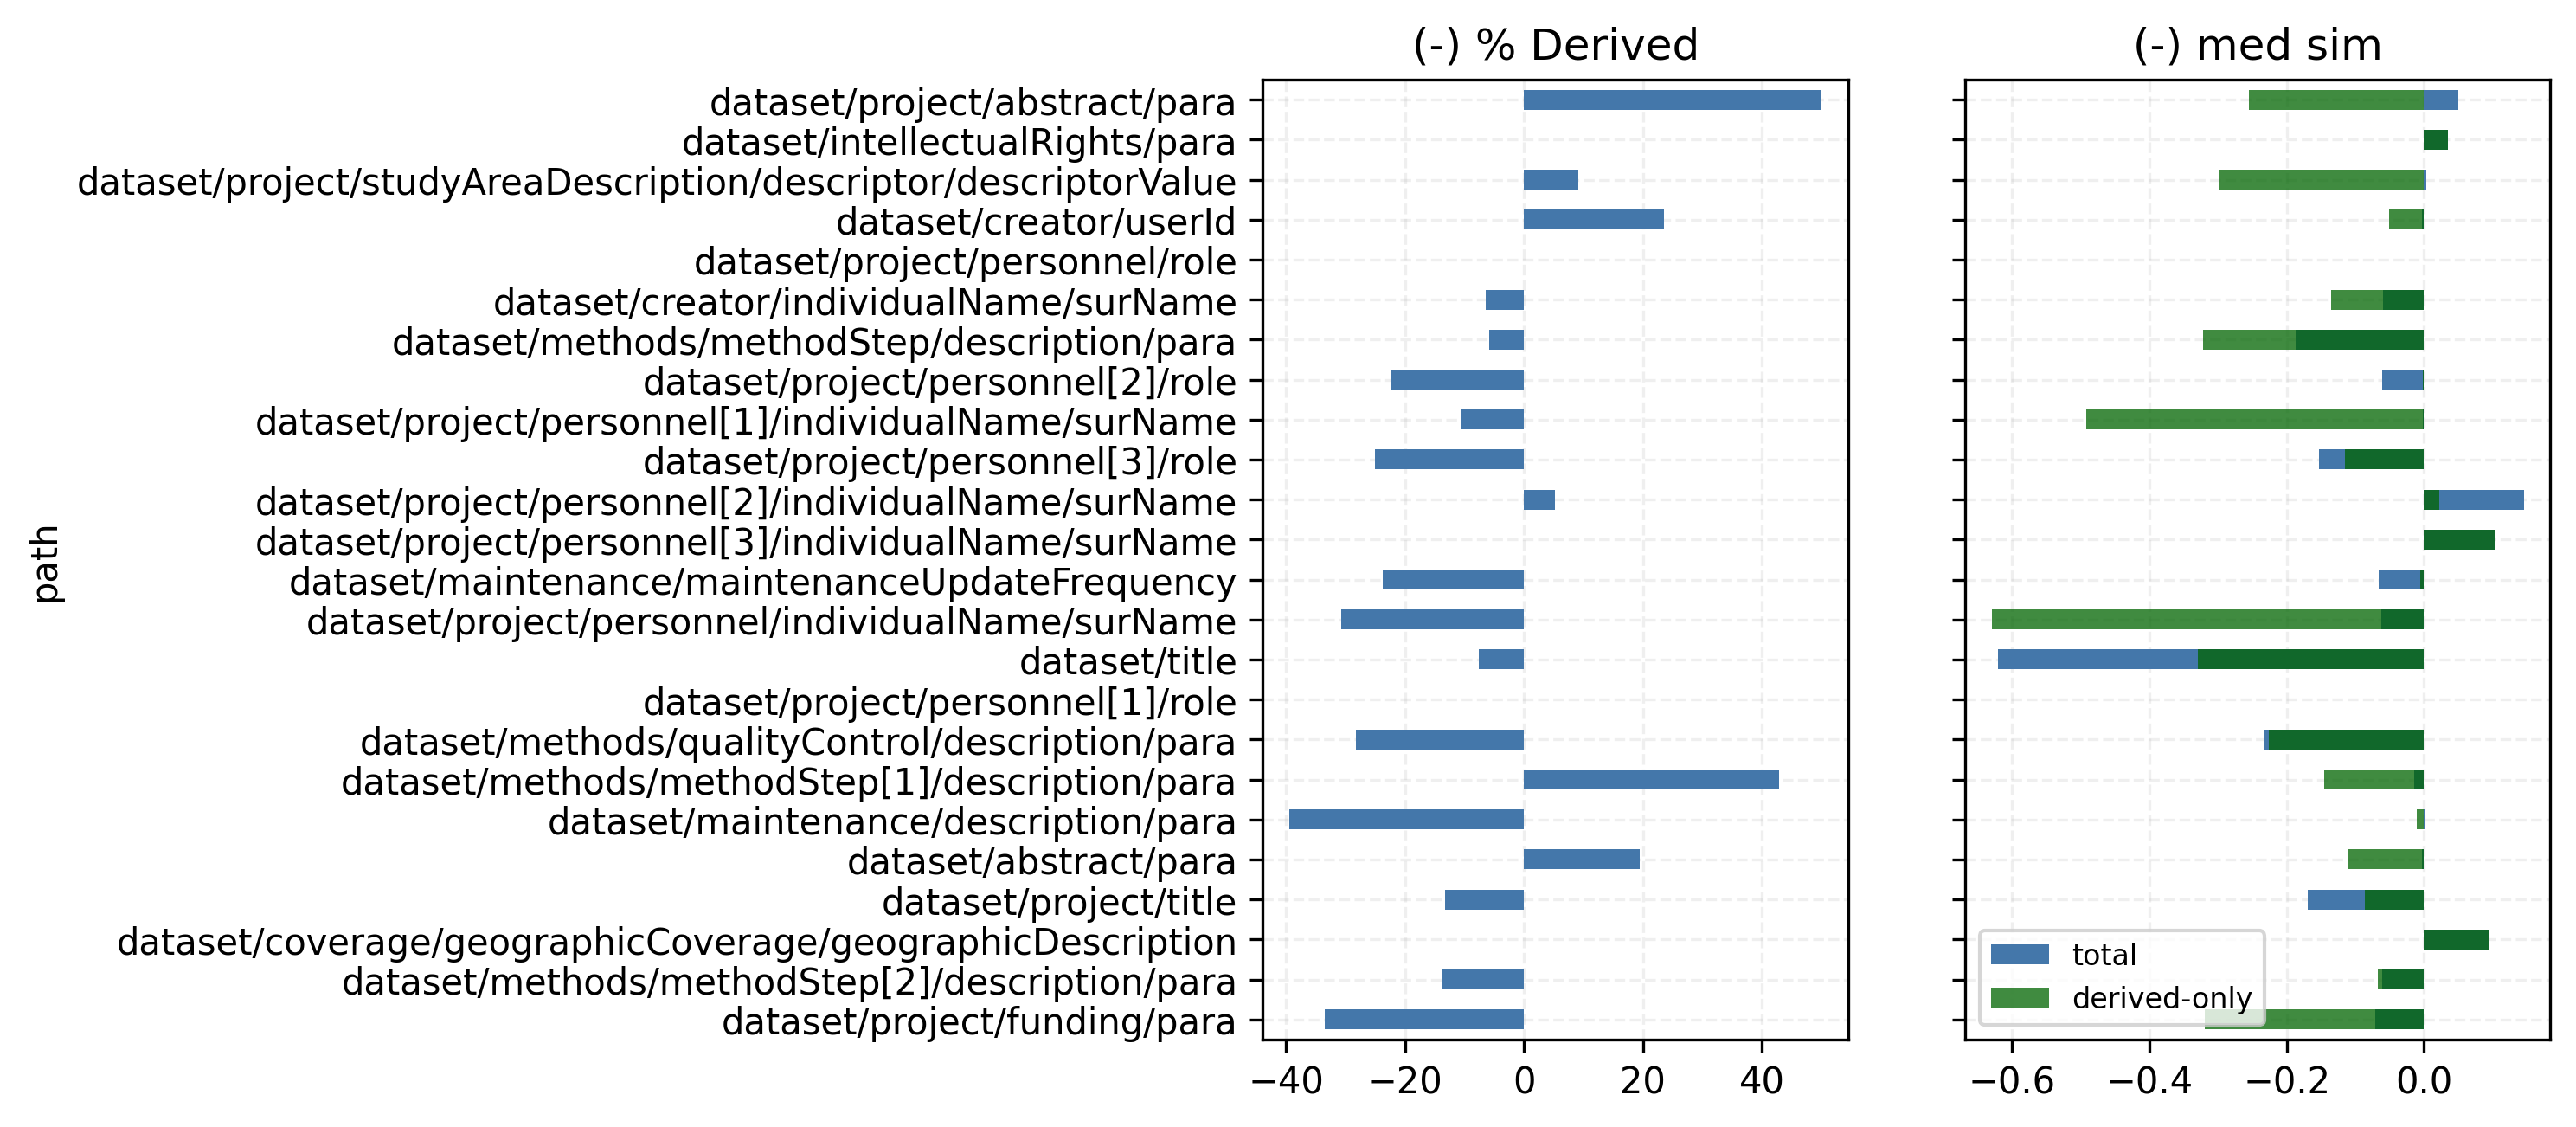

In [371]:
fig, axs = plt.subplots(1,2, dpi=300, sharey=True)

axs[0].set_title("(-) % Derived")
axs[1].set_title("(-) med sim")
eml_text_sim_overview_df.plot.barh(x="path", y="data_min_author_perc_derived", ax=axs[0], legend=False)
eml_text_sim_overview_df.plot.barh(x="path", y="data_min_author_median_tot", ax=axs[1], label="total", legend=False)
eml_text_sim_overview_df.plot.barh(x="path", y="data_min_author_median_der", ax=axs[1], label="derived-only", legend=False, color="darkgreen", alpha=0.75)

axs[1].legend(loc="lower left", fontsize=8)


for ax in axs:
    ax.grid(alpha=0.2, ls="--")
    ax.set_axisbelow(True)

plt.show()

In [314]:
# fig, axs = plt.subplots(2,3, figsize=(12, 8), dpi=300, sharey=True, sharex=False)

# for ax_t, ax_b in zip(axs[0], axs[1]):
#     ax_t.sharex(ax_b)

# axs[0][0].set_title("(A) % Derived")
# axs[0][1].set_title("(D) med sim [total]")
# axs[0][2].set_title("(D) med sim [derived]")
# eml_text_sim_overview_df.plot.barh(x="path", y="percentage_derived_data", ax=axs[0][0], legend=False, color="darkgreen")
# eml_text_sim_overview_df.plot.barh(x="path", y="ds_med_cont_data_gt_tot", ax=axs[0][1], legend=False, color="darkgreen")
# eml_text_sim_overview_df.plot.barh(x="path", y="ds_med_cont_data_gt_der", ax=axs[0][2], legend=False, color="darkgreen")

# axs[0][0].set_title("(A) % Derived")
# axs[1][1].set_title("(A) med sim [total]")
# axs[1][2].set_title("(A) med sim [derived]")
# eml_text_sim_overview_df.plot.barh(x="path", y="percentage_derived_author", ax=axs[1][0], legend=False, color="purple")
# eml_text_sim_overview_df.plot.barh(x="path", y="ds_med_cont_author_gt_tot", ax=axs[1][1], legend=False, color="purple")
# eml_text_sim_overview_df.plot.barh(x="path", y="ds_med_cont_author_gt_der", ax=axs[1][2], legend=False, color="purple")

# for ax in [*axs[0], *axs[1]]:
#     ax.grid(alpha=0.2, ls="--")
#     ax.set_axisbelow(True)

# plt.show()

In [324]:
# inspect the paths where data scores higher one by one
data_is_better_mask = eml_text_sim_overview_df["data_min_author_median_der"] > 0
data_is_better = eml_text_sim_overview_df[data_is_better_mask]
data_is_better

,path,percentage_derived_data,count_derived,count_not_derived,path_1,ds_med_cont_data_gt_tot,path_2,ds_med_cont_data_gt_der,path_3,percentage_derived_author,count_derived_1,count_not_derived_1,path_4,ds_med_cont_author_gt_tot,path_5,ds_med_cont_author_gt_der,data_min_author_perc_derived,data_min_author_median_tot,data_min_author_median_der
2,dataset/coverage/geographicCoverage/geographicDescription,100.000000,1,<NA>,dataset/coverage/geographicCoverage/geographicDescription,0.665401,dataset/coverage/geographicCoverage/geographicDescription,0.665401,dataset/coverage/geographicCoverage/geographicDescription,100.000000,2,<NA>,dataset/coverage/geographicCoverage/geographicDescription,0.569407,dataset/coverage/geographicCoverage/geographicDescription,0.569407,0.000000,0.095994,0.095994
12,dataset/project/personnel[3]/individualName/surName,100.000000,4,<NA>,dataset/project/personnel[3]/individualName/surName,0.376356,dataset/project/personnel[3]/individualName/surName,0.376356,dataset/project/personnel[3]/individualName/surName,100.000000,3,<NA>,dataset/project/personnel[3]/individualName/surName,0.273612,dataset/project/personnel[3]/individualName/surName,0.273612,0.000000,0.102744,0.102744
13,dataset/project/personnel[2]/individualName/surName,63.157895,12,7,dataset/project/personnel[2]/individualName/surName,0.305944,dataset/project/personnel[2]/individualName/surName,0.360468,dataset/project/personnel[2]/individualName/surName,57.894737,11,8,dataset/project/personnel[2]/individualName/surName,0.160292,dataset/project/personnel[2]/individualName/surName,0.338356,5.263158,0.145653,0.022113
22,dataset/intellectualRights/para,100.000000,1,<NA>,dataset/intellectualRights/para,0.448450,dataset/intellectualRights/para,0.448450,dataset/intellectualRights/para,100.000000,1,<NA>,dataset/intellectualRights/para,0.412951,dataset/intellectualRights/para,0.412951,0.000000,0.035499,0.035499


In [350]:
%%sql
-- inspect value for `dataset/coverage/geographicCoverage/geographicDescription`
SELECT *
FROM shared_data_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/coverage/geographicCoverage/geographicDescription'
    AND NOT (contains(d.data_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,data_text,gt_text,cos_sim_text
0,176,dataset/coverage/geographicCoverage/geographicDescription,Bashkortostan,"Sterlitamak, Republic of Bashkortostan",0.665401


In [349]:
%%sql
-- inspect value for `dataset/coverage/geographicCoverage/geographicDescription`
SELECT *
FROM shared_author_gt_eml_nodes__sim_text
WHERE path = 'dataset/coverage/geographicCoverage/geographicDescription'
    AND NOT (contains(author_text, 'not-derived-'))

Running query in 'duckdb'

,case_id,path,author_text,gt_text,cos_sim_text
0,144,dataset/coverage/geographicCoverage/geographicDescription,"Colombia, department of Caldas, with records from municipalities including Samaná and Pensilvania and localities in and around Parque Nacional Natural Selva de Florencia.","La colección de anfibios cuenta con ejemplares distribuidos a nivel nacional, especialmente de la zona Andina. Los departamentos con registros son: Amazonas, Antioquia, Arauca, Atlántico, Bolívar, Boyacá, Caldas, Caquetá, Cauca, Chocó, Córdoba, Huila, Magdalena, Meta, Putumayo, Quindío, Risaralda, Santander, Tolima y Valle del Cauca. Los registros de anfibios del conjunto de datos provienen de al menos 87 municipios de Colombia, ubicados en 20 departamentos. La región Andina es la mejor representada, mientras que, para las otras regiones naturales de Colombia. Los registros provienen de un intervalo altitudinal comprendido entre los 0 y los 3906 m. La mayoría de los registros se concentran en el centro-norte del país, siendo Caldas el departamento con mayor representatividad (n = 1325), seguido de lejos por Risaralda (n = 189).",0.620641
1,147,dataset/coverage/geographicCoverage/geographicDescription,The Bahamas,"Censuses were conducted in The Bahamas, primarily in coastal habitats such as sandbars and salt marshes. In particular, the dataset contains occurrence records across 16 different islands: Abaco Islands, Acklins Island, Andros Island, Berry Islands, Bimini Islands, Cat Island, Crooked Island, Eleuthera Island, Exuma Islands, Grand Bahama Island, Great Inagua Island, Harbour Island, Long Island, New Providence Island, San Salvadore Island, and Ragged Island.",0.518173


In [351]:
%%sql
-- inspect value for `dataset/project/personnel[3]/individualName/surName`
SELECT *
FROM shared_data_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/project/personnel[3]/individualName/surName'
    AND NOT (contains(d.data_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,data_text,gt_text,cos_sim_text
0,2,dataset/project/personnel[3]/individualName/surName,Débora S.G. Henriques,Poponessi,0.260463
1,48,dataset/project/personnel[3]/individualName/surName,Débora S.G. Henriques,Henriques,0.762364
2,62,dataset/project/personnel[3]/individualName/surName,João Queirós,Porto,0.492248
3,89,dataset/project/personnel[3]/individualName/surName,Abrão Leite,Lhoumeau,0.192765


In [353]:
%%sql
-- inspect value for `dataset/project/personnel[3]/individualName/surName`
SELECT *
FROM shared_author_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/project/personnel[3]/individualName/surName'
    AND NOT (contains(d.author_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,author_text,gt_text,cos_sim_text
0,0,dataset/project/personnel[3]/individualName/surName,Calado,Heleno,0.226543
1,40,dataset/project/personnel[3]/individualName/surName,Hardersen,Gisondi,0.273612
2,48,dataset/project/personnel[3]/individualName/surName,Débora S.G. Henriques,Henriques,0.762364


In [354]:
%%sql
-- inspect value for `dataset/project/personnel[2]/individualName/surName`
SELECT *
FROM shared_data_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/project/personnel[2]/individualName/surName'
    AND NOT (contains(d.data_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,data_text,gt_text,cos_sim_text
0,0,dataset/project/personnel[2]/individualName/surName,Calado,Calado,1.000000
1,101,dataset/project/personnel[2]/individualName/surName,Coelho,Morgado,0.451720
2,109,dataset/project/personnel[2]/individualName/surName,Grishina,Grishina,1.000000
3,146,dataset/project/personnel[2]/individualName/surName,Casimiro,Lamelas-López,0.349314
4,19,dataset/project/personnel[2]/individualName/surName,Unknown,Elahee,0.292395
5,2,dataset/project/personnel[2]/individualName/surName,Márcia C.M. Coelho,Nunes Morgado,0.371623
6,35,dataset/project/personnel[2]/individualName/surName,Fernández-González,Fernández López,0.822811
7,48,dataset/project/personnel[2]/individualName/surName,Márcia C.M. Coelho,Morgado,0.305944
8,57,dataset/project/personnel[2]/individualName/surName,2119,Soares,0.149163
9,62,dataset/project/personnel[2]/individualName/surName,Joana Paupério,Queirós,0.349279


In [355]:
%%sql
-- inspect value for `dataset/project/personnel[2]/individualName/surName`
SELECT *
FROM shared_author_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/project/personnel[2]/individualName/surName'
    AND NOT (contains(d.author_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,author_text,gt_text,cos_sim_text
0,0,dataset/project/personnel[2]/individualName/surName,Borges,Calado,0.189881
1,101,dataset/project/personnel[2]/individualName/surName,Coelho,Morgado,0.451720
2,146,dataset/project/personnel[2]/individualName/surName,Casimiro,Lamelas-López,0.349314
3,147,dataset/project/personnel[2]/individualName/surName,Jeffery M; Golder W; Linero D; Rock J; Gratto-Trevor C; Maddock S; Elliott-Smith E,Golder,0.328770
4,162,dataset/project/personnel[2]/individualName/surName,institutional/team-based only,Rocchi,0.083559
5,4,dataset/project/personnel[2]/individualName/surName,Biological Station Wijster,Gerrits,0.160292
6,40,dataset/project/personnel[2]/individualName/surName,Mosconi,Bardiani,0.348156
7,48,dataset/project/personnel[2]/individualName/surName,Márcia C.M. Coelho,Morgado,0.305944
8,53,dataset/project/personnel[2]/individualName/surName,Li,Zhao,0.338356
9,63,dataset/project/personnel[2]/individualName/surName,Boieiro,Boieiro,1.000000


In [360]:
%%sql
-- inspect value for `dataset/intellectualRights/para`
SELECT *
FROM shared_data_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/intellectualRights/para'
    AND NOT (contains(d.data_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,data_text,gt_text,cos_sim_text
0,142,dataset/intellectualRights/para,License information in source data indicates CC-BY 4.0.,This work is licensed under a,0.44845


In [362]:
%%sql
-- inspect value for `dataset/intellectualRights/para`
SELECT *
FROM shared_author_gt_eml_nodes__sim_text AS d
WHERE d.path = 'dataset/intellectualRights/para'
    AND NOT (contains(d.author_text, 'not-derived-'))
;

Running query in 'duckdb'

,case_id,path,author_text,gt_text,cos_sim_text
0,133,dataset/intellectualRights/para,Licensed under Creative Commons Attribution 4.0 International.,This work is licensed under a,0.412951


#### Attributes

In [433]:
%%sql
-- attributes constructed by data
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS 
    eml_nodes__data__attributes_unpacked AS (
    SELECT d.path, d.case_id, dja.key, dja.value
    FROM 
        cons_eml_data_nodes AS d,
        json_each(d.attributes) AS dja
);

-- attributes constructed by author
CREATE 
    OR REPLACE
    TABLE 
    -- IF NOT EXISTS 
    eml_nodes__author__attributes_unpacked AS (
    SELECT d.path, d.case_id, aja.key, aja.value
    FROM 
        cons_eml_author_nodes AS d,
        json_each(d.attributes) AS aja
);

-- attributes from ground truth
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS 
    gt_eml_data_nodes__attributes__unpacked AS (
    SELECT d.path, d.attributes, d.case_id, aja.key, aja.value
    FROM 
        gt_eml_data_nodes AS d,
        json_each(d.attributes) AS aja
);

Running query in 'duckdb'

,Count
0,3266


In [434]:
%%sql 
SELECT * FROM eml_nodes__data__attributes_unpacked;

Running query in 'duckdb'

,path,case_id,key,value
0,.,0,{http://www.w3.org/XML/1998/namespace}lang,"""en"""
1,dataset/creator/userId,0,directory,"""https://orcid.org"""
2,dataset/project/studyAreaDescription/descriptor[1],0,citableClassificationSystem,"""false"""
3,dataset/project/studyAreaDescription/descriptor[2],0,citableClassificationSystem,"""false"""
4,.,10,system,"""knb"""
...,...,...,...,...
1166,dataset/project/studyAreaDescription/descriptor[2],98,name,"""locality"""
1167,dataset/project/studyAreaDescription/descriptor[3],98,name,"""study_system"""
1168,.,94,packageId,"""10.1007/978-1-0716-2313-8_8"""
1169,.,97,packageId,"""urn:uuid:3f8f6f6a-8f2b-4d1b-9d8d-2b2c5f9d4f1a"""


In [436]:
%%sql
-- find out which attributes are present for which paths
SELECT d.path, d.key, COUNT(*)
FROM eml_nodes__data__attributes_unpacked AS d
GROUP BY 1,2
ORDER BY 1,2,3;

Running query in 'duckdb'

,path,key,count_star()
0,.,packageId,150
1,.,system,150
2,.,{http://www.w3.org/XML/1998/namespace}lang,86
3,additionalMetadata,id,14
4,additionalMetadata/metadata/customExtensions/sourceFiles/file[1],name,1
...,...,...,...
67,dataset/project/studyAreaDescription/descriptor[4],name,1
68,dataset/project/studyAreaDescription[1]/descriptor,citableClassificationSystem,1
69,dataset/project/studyAreaDescription[1]/descriptor,name,1
70,dataset/project/studyAreaDescription[2]/descriptor,citableClassificationSystem,1


In [438]:
%%sql 
SELECT * FROM eml_nodes__author__attributes_unpacked;

Running query in 'duckdb'

,path,case_id,key,value
0,.,0,{http://www.w3.org/XML/1998/namespace}lang,"""en"""
1,dataset/creator/userId,0,directory,"""https://orcid.org"""
2,dataset/project/studyAreaDescription/descriptor[1],0,citableClassificationSystem,"""false"""
3,dataset/project/studyAreaDescription/descriptor[2],0,citableClassificationSystem,"""false"""
4,.,10,system,"""knb"""
...,...,...,...,...
1122,.,89,packageId,"""not-derived-000"""
1123,.,91,packageId,"""https://doi.org/10.15468/qbj3rd"""
1124,.,92,packageId,"""https://doi.org/10.5281/zenodo.10259604"""
1125,.,97,packageId,"""https://doi.org/10.15468/5xa74w"""


In [439]:
%%sql
-- find out which attributes are present for which paths
SELECT d.path, d.key, COUNT(*)
FROM eml_nodes__author__attributes_unpacked AS d
GROUP BY 1,2
ORDER BY 1,2,3;

Running query in 'duckdb'

,path,key,count_star()
0,.,packageId,148
1,.,system,148
2,.,{http://www.w3.org/XML/1998/namespace}lang,95
3,additionalMetadata,id,14
4,additionalMetadata/metadata/customMetadata/datasetProvenance/sourceFile[1],name,1
5,additionalMetadata/metadata/customMetadata/datasetProvenance/sourceFile[1],rows,1
6,additionalMetadata/metadata/customMetadata/datasetProvenance/sourceFile[2],name,1
7,additionalMetadata/metadata/customMetadata/datasetProvenance/sourceFile[2],rows,1
8,additionalMetadata/metadata/customMetadata/datasetScope/dataProducts/product[1],type,1
9,additionalMetadata/metadata/customMetadata/datasetScope/dataProducts/product[2],type,1


In [440]:
%%sql
-- find out which attributes are present (Data)
SELECT d.key, COUNT(*)
FROM eml_nodes__data__attributes_unpacked AS d
GROUP BY 1
ORDER BY 1,2;

Running query in 'duckdb'

,key,count_star()
0,citableClassificationSystem,278
1,date,1
2,description,2
3,directory,153
4,events,1
5,id,16
6,identifier,1
7,name,301
8,occurrences,1
9,packageId,150


In [441]:
%%sql
-- find out which attributes are present (Author)
SELECT d.key, COUNT(*)
FROM eml_nodes__author__attributes_unpacked AS d
GROUP BY 1
ORDER BY 1,2;

Running query in 'duckdb'

,key,count_star()
0,citableClassificationSystem,269
1,countryCode,1
2,decimalLatitude,1
3,decimalLongitude,1
4,directory,148
5,geodeticDatum,1
6,id,16
7,name,287
8,packageId,148
9,records,3


In [442]:
%%sql
SELECT * FROM gt_eml_data_nodes__attributes__unpacked;

Running query in 'duckdb'

,path,attributes,case_id,key,value
0,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd"", ""packageId"": ""2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",0,{http://www.w3.org/XML/1998/namespace}lang,"""eng"""
1,dataset/title,"{""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",0,{http://www.w3.org/XML/1998/namespace}lang,"""eng"""
2,dataset/creator[2]/userId,"{""directory"": ""https://orcid.org/""}",0,directory,"""https://orcid.org/"""
3,dataset/creator[4]/userId,"{""directory"": ""https://orcid.org/""}",0,directory,"""https://orcid.org/"""
4,dataset/metadataProvider/userId,"{""directory"": ""https://orcid.org/""}",0,directory,"""https://orcid.org/"""
...,...,...,...,...,...
3261,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""715e3b90-a68d-47a5-b676-a8428e1aaf3a/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",99,scope,"""system"""
3262,dataset/project/studyAreaDescription/descriptor,"{""name"": ""generic"", ""citableClassificationSystem"": ""false""}",99,name,"""generic"""
3263,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""715e3b90-a68d-47a5-b676-a8428e1aaf3a/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",99,system,"""http://gbif.org"""
3264,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""715e3b90-a68d-47a5-b676-a8428e1aaf3a/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",99,packageId,"""715e3b90-a68d-47a5-b676-a8428e1aaf3a/v1.2"""


In [443]:
%%sql
-- find out which attributes are present for which paths
SELECT d.path, d.key, COUNT(*)
FROM gt_eml_data_nodes__attributes__unpacked AS d
GROUP BY 1,2
ORDER BY 1,2,3;

Running query in 'duckdb'

,path,key,count_star()
0,.,packageId,178
1,.,scope,177
2,.,system,179
3,.,{http://www.w3.org/2001/XMLSchema-instance}schemaLocation,178
4,.,{http://www.w3.org/XML/1998/namespace}lang,176
...,...,...,...
308,dataset/project/relatedProject,id,2
309,dataset/project/relatedProject/personnel/userId,directory,2
310,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,71
311,dataset/project/studyAreaDescription/descriptor,name,71


In [444]:
%%sql
-- find out which attributes are present in total (GT)
SELECT d.key, COUNT(*)
FROM gt_eml_data_nodes__attributes__unpacked AS d
GROUP BY 1
ORDER BY 1,2;

Running query in 'duckdb'

,key,count_star()
0,citableClassificationSystem,71
1,directory,1261
2,function,65
3,id,70
4,identifier,419
5,name,71
6,packageId,178
7,scope,226
8,system,180
9,uncertaintyMeasure,2


In [450]:
%%sql
-- find out which attributes are present in total (GT)
SELECT g.key
FROM gt_eml_data_nodes__attributes__unpacked AS g

INTERSECT 

SELECT a.key
FROM eml_nodes__author__attributes_unpacked AS a

INTERSECT 

SELECT d.key
FROM eml_nodes__data__attributes_unpacked AS d

Running query in 'duckdb'

,key
0,packageId
1,directory
2,name
3,id
4,system
5,{http://www.w3.org/XML/1998/namespace}lang
6,citableClassificationSystem


In [451]:
%%sql
-- find out which attributes are present in total (GT)
SELECT g.key
FROM gt_eml_data_nodes__attributes__unpacked AS g

UNION 

SELECT a.key
FROM eml_nodes__author__attributes_unpacked AS a

UNION 

SELECT d.key
FROM eml_nodes__data__attributes_unpacked AS d

Running query in 'duckdb'

,key
0,url
1,decimalLongitude
2,citableClassificationSystem
3,startDate
4,packageId
5,type
6,uncertaintyMeasure
7,directory
8,name
9,records


In [453]:
%%sql
-- find out which attributes are present in total (GT)
SELECT g.key
FROM gt_eml_data_nodes__attributes__unpacked AS g

EXCEPT 

SELECT a.key
FROM eml_nodes__author__attributes_unpacked AS a

EXCEPT 

SELECT d.key
FROM eml_nodes__data__attributes_unpacked AS d

Running query in 'duckdb'

,key
0,url
1,scope
2,function
3,{http://www.w3.org/2001/XMLSchema-instance}schemaLocation
4,uncertaintyMeasure


In [454]:
%%sql
-- find out which attributes are present in total (A X D)
SELECT a.key
FROM eml_nodes__author__attributes_unpacked AS a

INTERSECT 

SELECT d.key
FROM eml_nodes__data__attributes_unpacked AS d

Running query in 'duckdb'

,key
0,citableClassificationSystem
1,{http://www.w3.org/XML/1998/namespace}lang
2,directory
3,name
4,records
5,rows
6,packageId
7,type
8,system
9,id


In [455]:
%%sql
-- find out which attributes are present in total (GT) linked by path and case
SELECT g.key, a.key, d.key, COUNT(*)
FROM gt_eml_data_nodes__attributes__unpacked AS g
LEFT JOIN eml_nodes__author__attributes_unpacked AS a
    ON g.key = a.key
    AND g.path = a.path
    AND g.case_id = a.case_id
LEFT JOIN eml_nodes__data__attributes_unpacked AS d
    ON g.key = d.key
    AND g.path = d.path
    AND g.case_id = d.case_id
GROUP BY 1,2,3
ORDER BY 1,2,3,4;

Running query in 'duckdb'

,key,key_1,key_2,count_star()
0,citableClassificationSystem,citableClassificationSystem,citableClassificationSystem,3
1,citableClassificationSystem,citableClassificationSystem,NaN,8
2,citableClassificationSystem,NaN,citableClassificationSystem,8
3,citableClassificationSystem,NaN,NaN,52
4,directory,directory,directory,15
5,directory,directory,NaN,2
6,directory,NaN,directory,4
7,directory,NaN,NaN,1240
8,function,NaN,NaN,65
9,id,NaN,NaN,70


In [456]:
%%sql
-- find out which attributes are present when shared (GT x D x A)
SELECT g.path, g.key, g.value, d.key, d.value, a.key, a.value
FROM gt_eml_data_nodes__attributes__unpacked AS g
JOIN eml_nodes__author__attributes_unpacked AS a
    ON g.key = a.key
    AND g.path = a.path
    AND g.case_id = a.case_id
JOIN eml_nodes__data__attributes_unpacked AS d
    ON g.key = d.key
    AND g.path = d.path
    AND g.case_id = d.case_id
-- GROUP BY 1,2,3
-- ORDER BY 1,2,3,4;

Running query in 'duckdb'

,path,key,value,key_1,value_1,key_2,value_2
0,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",{http://www.w3.org/XML/1998/namespace}lang,"""en"""
1,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",{http://www.w3.org/XML/1998/namespace}lang,"""en"""
2,dataset/creator/userId,directory,"""https://orcid.org/""",directory,"""https://orcid.org""",directory,"""https://orcid.org"""
3,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",{http://www.w3.org/XML/1998/namespace}lang,"""en"""
4,.,system,"""http://gbif.org""",system,"""knb""",system,"""knb"""
...,...,...,...,...,...,...,...
304,.,packageId,"""2b767e54-7921-4908-af93-84a9c35264c1/v1.10""",packageId,"""urn:uuid:3f8f6f6a-8f2b-4d1b-9d8d-2b2c5f9d4f1a""",packageId,"""https://doi.org/10.15468/5xa74w"""
305,.,packageId,"""https://ipt.my.lifewatch.eu/resource?id=amoladeras/v2.4""",packageId,"""doi:10.15470/jpjhuu""",packageId,"""not-derived-000"""
306,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",{http://www.w3.org/XML/1998/namespace}lang,"""en"""
307,.,system,"""http://gbif.org""",system,"""knb""",system,"""knb"""


In [461]:
%%sql
-- join the comparable attribute tables (D x GT)
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS
    shared_data_gt_attributes_eml__value_sim AS (
    SELECT *, g.case_id, g.path, g.key AS gt_key, g.value AS gt_value, d.key AS data_key, d.value AS data_value, cos_sim(data_value, gt_value) AS cos_sim_data_gt_value
    FROM gt_eml_data_nodes__attributes__unpacked AS g
    JOIN eml_nodes__data__attributes_unpacked AS d
        ON g.key = d.key
        AND g.path = d.path
        AND g.case_id = d.case_id
);
SELECT * FROM shared_data_gt_attributes_eml__value_sim;

Running query in 'duckdb'

,path,attributes,case_id,key,value,path_1,case_id_1,key_1,value_1,case_id_2,path_2,gt_key,gt_value,data_key,data_value,cos_sim_data_gt_value
0,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd"", ""packageId"": ""2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",0,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,0,{http://www.w3.org/XML/1998/namespace}lang,"""en""",0,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
1,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""https://data.canadensys.net/micropublications/resource?id=specimen_22/v1.0"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",100,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,100,{http://www.w3.org/XML/1998/namespace}lang,"""en""",100,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
2,dataset/creator/userId,"{""directory"": ""https://orcid.org/""}",100,directory,"""https://orcid.org/""",dataset/creator/userId,100,directory,"""https://orcid.org""",100,dataset/creator/userId,directory,"""https://orcid.org/""",directory,"""https://orcid.org""",0.992002
3,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""88d3beab-eb7c-4a3a-927e-7b8bf6d35ef6/v1.4"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",101,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,101,{http://www.w3.org/XML/1998/namespace}lang,"""en""",101,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
4,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""89624736-2b0e-455c-83c7-13778d59db1b/v1.1"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",104,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,104,{http://www.w3.org/XML/1998/namespace}lang,"""en""",104,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""2b767e54-7921-4908-af93-84a9c35264c1/v1.10"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",97,packageId,"""2b767e54-7921-4908-af93-84a9c35264c1/v1.10""",.,97,packageId,"""urn:uuid:3f8f6f6a-8f2b-4d1b-9d8d-2b2c5f9d4f1a""",97,.,packageId,"""2b767e54-7921-4908-af93-84a9c35264c1/v1.10""",packageId,"""urn:uuid:3f8f6f6a-8f2b-4d1b-9d8d-2b2c5f9d4f1a""",0.449420
422,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""https://ipt.my.lifewatch.eu/resource?id=amoladeras/v2.4"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",98,packageId,"""https://ipt.my.lifewatch.eu/resource?id=amoladeras/v2.4""",.,98,packageId,"""doi:10.15470/jpjhuu""",98,.,packageId,"""https://ipt.my.lifewatch.eu/resource?id=amoladeras/v2.4""",packageId,"""doi:10.15470/jpj

In [462]:
%%sql
-- join the comparable attribute tables (D x GT)
CREATE 
    OR REPLACE 
    TABLE 
    -- IF NOT EXISTS
    shared_author_gt_attributes_eml__value_sim AS (
    SELECT *, g.case_id, g.path, g.key AS gt_key, g.value AS gt_value, d.key AS data_key, d.value AS author_value, cos_sim(author_value, gt_value) AS cos_sim_author_gt_value
    FROM gt_eml_data_nodes__attributes__unpacked AS g
    JOIN eml_nodes__author__attributes_unpacked AS d
        ON g.key = d.key
        AND g.path = d.path
        AND g.case_id = d.case_id
);
SELECT * FROM shared_author_gt_attributes_eml__value_sim;

Running query in 'duckdb'

,path,attributes,case_id,key,value,path_1,case_id_1,key_1,value_1,case_id_2,path_2,gt_key,gt_value,data_key,author_value,cos_sim_author_gt_value
0,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd"", ""packageId"": ""2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",0,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,0,{http://www.w3.org/XML/1998/namespace}lang,"""en""",0,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
1,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""https://data.canadensys.net/micropublications/resource?id=specimen_22/v1.0"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",100,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,100,{http://www.w3.org/XML/1998/namespace}lang,"""en""",100,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
2,dataset/creator/userId,"{""directory"": ""https://orcid.org/""}",100,directory,"""https://orcid.org/""",dataset/creator/userId,100,directory,"""https://orcid.org""",100,dataset/creator/userId,directory,"""https://orcid.org/""",directory,"""https://orcid.org""",0.992002
3,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""88d3beab-eb7c-4a3a-927e-7b8bf6d35ef6/v1.4"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",101,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,101,{http://www.w3.org/XML/1998/namespace}lang,"""en""",101,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
4,dataset/project/studyAreaDescription/descriptor,"{""name"": ""generic"", ""citableClassificationSystem"": ""false""}",104,citableClassificationSystem,"""false""",dataset/project/studyAreaDescription/descriptor,104,citableClassificationSystem,"""false""",104,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,"""false""",citableClassificationSystem,"""false""",1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,dataset/project/studyAreaDescription/descriptor,"{""name"": ""generic"", ""citableClassificationSystem"": ""false""}",98,citableClassificationSystem,"""false""",dataset/project/studyAreaDescription/descriptor,98,citableClassificationSystem,"""false""",98,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,"""false""",citableClassificationSystem,"""false""",1.000000
422,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation"": ""eml://ecoinformatics.org/eml-2.1.1 http://rs.gbif.org/schema/eml-gbif-profile/1.2/eml.xsd"", ""packageId"": ""715e3b90-a68d-47a5-b676-a8428e1aaf3a/v1.2"", ""system"": ""http://gbif.org"", ""scope"": ""system"", ""{http://www.w3.org/XML/1998/namespace}lang"": ""eng""}",99,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",.,99,{http://www.w3.org/XML/1998/namespace}lang,"""en""",99,.,{http://www.w3.org/XML/1998/namespace}lang,"""eng""",{http://www.w3.org/XML/1998/namespace}lang,"""en""",0.454492
423,dataset/project/studyAreaDescription/descriptor,"{""name"": ""generic"", ""citableClassificationSystem"": ""false""}",98,name,"""generic""",dataset/project/studyAreaDescription/descriptor,98,name,"""habitat_type""",98,dataset/project/studyAreaDescription/descriptor,name,"""generic""",name,"""habitat_type""",0.345520
424,.,"{""{http://www.w3.org/2001/XMLSchema-instance}schemaLocation

In [474]:
%%sql eml_attribute_sim_overview_df <<
-- Compare data VS author for derivation results
-- - 1. % derived 
-- - 2. overall difference of medians
-- - 3. derived difference of medians
WITH 
-- author
  author_count_not_derived AS (
    SELECT 
        path, key, count(1) as count_not_derived
    FROM eml_nodes__author__attributes_unpacked
    WHERE (contains(value, 'not-derived-'))
    GROUP BY 1,2
), author_count_derived AS (
    SELECT 
        path, key, count(1) as count_derived
    FROM eml_nodes__author__attributes_unpacked
    WHERE NOT (contains(value, 'not-derived-'))
    GROUP BY 1,2
), author_percentage_derived AS ( 
    SELECT 
        cd.path, cd.key,
        (
            (IFNULL(count_derived, 0)) 
            / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
        ) * 100 AS percentage_derived_author, 
        count_derived, count_not_derived
    FROM author_count_derived AS cd
        LEFT JOIN author_count_not_derived AS cnd
            ON cd.path = cnd.path
            AND cd.key = cnd.key
), author_medians AS (
    SELECT path, key, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt_value) AS ds_med_cont_author_gt_tot,
    FROM shared_author_gt_attributes_eml__value_sim
    GROUP BY path, key
), author_derived_medians AS (
    SELECT path, key, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_author_gt_value) AS ds_med_cont_author_gt_der,
    FROM shared_author_gt_attributes_eml__value_sim
    WHERE NOT (contains(author_value, 'not-derived-'))
    GROUP BY path, key
), 
-- data  
  data_count_not_derived AS (
    SELECT 
        path, key, count(1) as count_not_derived
    FROM eml_nodes__data__attributes_unpacked
    WHERE (contains(value, 'not-derived-'))
    GROUP BY 1,2
), data_count_derived AS (
    SELECT 
        path, key, count(1) as count_derived
    FROM eml_nodes__data__attributes_unpacked
    WHERE NOT (contains(value, 'not-derived-'))
    GROUP BY 1,2
), data_percentage_derived AS ( 
    SELECT 
        cd.path, cd.key,
        (
            (IFNULL(count_derived, 0)) 
            / (IFNULL(count_derived, 0) + IFNULL(count_not_derived, 0))
        ) * 100 AS percentage_derived_data, 
        count_derived, count_not_derived
    FROM data_count_derived AS cd
        LEFT JOIN data_count_not_derived AS cnd
            ON cd.path = cnd.path
            AND cd.key = cnd.key
), data_medians AS (
    SELECT path, key, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt_value) AS ds_med_cont_data_gt_tot,
    FROM shared_data_gt_attributes_eml__value_sim
    GROUP BY path, key
), data_derived_medians AS (
    SELECT path, key, PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_data_gt_value) AS ds_med_cont_data_gt_der,
    FROM shared_data_gt_attributes_eml__value_sim
    WHERE NOT (contains(data_value, 'not-derived-'))
    GROUP BY path, key
)
SELECT 
    *,
    dpd.percentage_derived_data - apd.percentage_derived_author AS data_min_author_perc_derived,
    dm.ds_med_cont_data_gt_tot - am.ds_med_cont_author_gt_tot AS data_min_author_median_tot,
    ddm.ds_med_cont_data_gt_der - adm.ds_med_cont_author_gt_der AS data_min_author_median_der
FROM 
    data_percentage_derived dpd, data_medians dm, data_derived_medians ddm,
    author_percentage_derived apd, author_medians am, author_derived_medians adm
WHERE dpd.key = dm.key
    AND dm.key = ddm.key
    AND ddm.key = apd.key
    AND apd.key = am.key
    AND am.key = adm.key
    AND dpd.path = dm.path
    AND dm.path = ddm.path
    AND ddm.path = apd.path
    AND apd.path = am.path
    AND am.path = adm.path
;

Running query in 'duckdb'

In [475]:
eml_attribute_sim_overview_df

,path,key,percentage_derived_data,count_derived,count_not_derived,path_1,key_1,ds_med_cont_data_gt_tot,path_2,key_2,...,count_not_derived_1,path_4,key_4,ds_med_cont_author_gt_tot,path_5,key_5,ds_med_cont_author_gt_der,data_min_author_perc_derived,data_min_author_median_tot,data_min_author_median_der
0,.,{http://www.w3.org/XML/1998/namespace}lang,100.000000,86,<NA>,.,{http://www.w3.org/XML/1998/namespace}lang,0.454492,.,{http://www.w3.org/XML/1998/namespace}lang,...,<NA>,.,{http://www.w3.org/XML/1998/namespace}lang,0.454492,.,{http://www.w3.org/XML/1998/namespace}lang,0.454492,0.00000,0.000000,0.000000
1,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,100.000000,38,<NA>,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,1.000000,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,...,<NA>,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,1.000000,dataset/project/studyAreaDescription/descriptor,citableClassificationSystem,1.000000,0.00000,0.000000,0.000000
2,.,packageId,44.666667,67,83,.,packageId,0.225187,.,packageId,...,71,.,packageId,0.217026,.,packageId,0.252238,-7.36036,0.008161,0.124282
3,dataset/creator/userId,directory,100.000000,148,<NA>,dataset/creator/userId,directory,0.992002,dataset/creator/userId,directory,...,<NA>,dataset/creator/userId,directory,0.992002,dataset/creator/userId,directory,0.992002,0.00000,0.000000,0.000000
4,.,system,100.000000,150,<NA>,.,system,0.188101,.,system,...,<NA>,.,system,0.188101,.,system,0.188101,0.00000,0.000000,0.000000
5,dataset/project/studyAreaDescription/descriptor,name,100.000000,38,<NA>,dataset/project/studyAreaDescription/descriptor,name,0.345520,dataset/project/studyAreaDescription/descriptor,name,...,<NA>,dataset/project/studyAreaDescription/descriptor,name,0.345520,dataset/project/studyAreaDescription/descriptor,name,0.345520,0.00000,0.000000,0.000000


In [541]:
eml_attribute_sim_overview_df[["percentage_derived_data", "percentage_derived_author"]]

,percentage_derived_data,percentage_derived_author
0,100.000000,100.000000
1,100.000000,100.000000
2,44.666667,52.027027
3,100.000000,100.000000
4,100.000000,100.000000
5,100.000000,100.000000


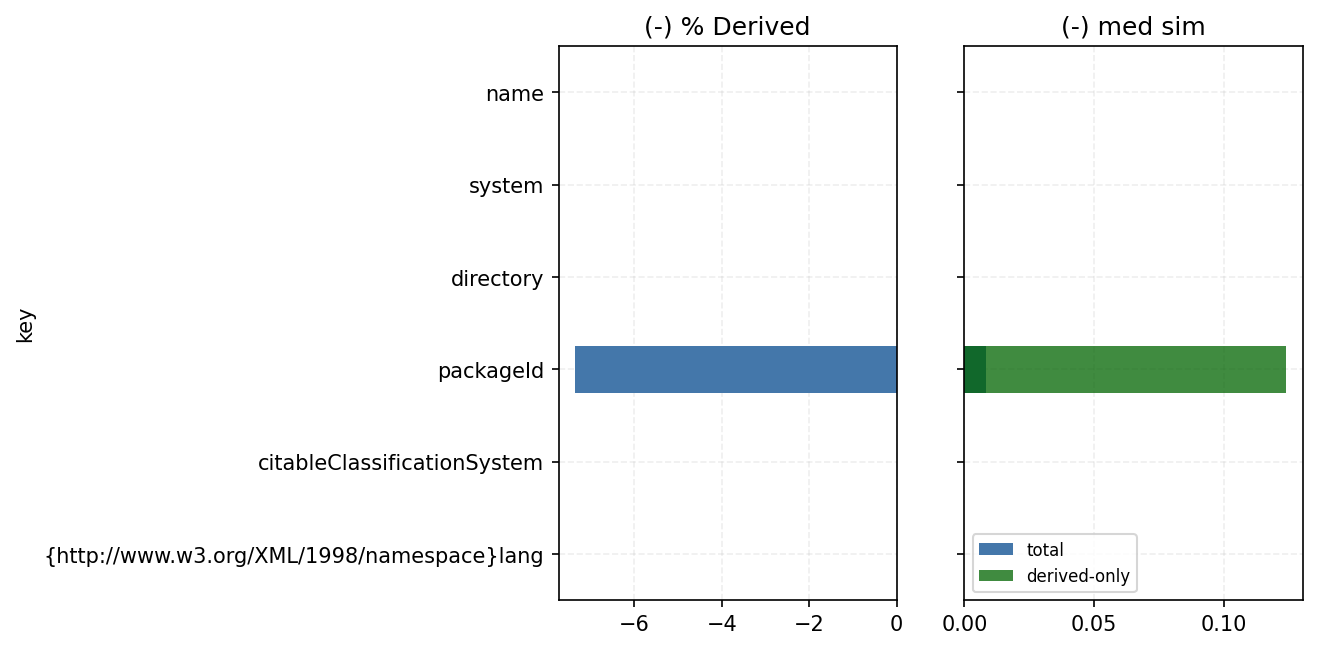

In [476]:
fig, axs = plt.subplots(1,2, dpi=150, sharey=True)

axs[0].set_title("(-) % Derived")
axs[1].set_title("(-) med sim")
eml_attribute_sim_overview_df.plot.barh(x="key", y="data_min_author_perc_derived", ax=axs[0], legend=False)
eml_attribute_sim_overview_df.plot.barh(x="key", y="data_min_author_median_tot", ax=axs[1], label="total", legend=False)
eml_attribute_sim_overview_df.plot.barh(x="key", y="data_min_author_median_der", ax=axs[1], label="derived-only", legend=False, color="darkgreen", alpha=0.75)

axs[1].legend(loc="lower left", fontsize=8)


for ax in axs:
    ax.grid(alpha=0.2, ls="--")
    ax.set_axisbelow(True)

plt.show()

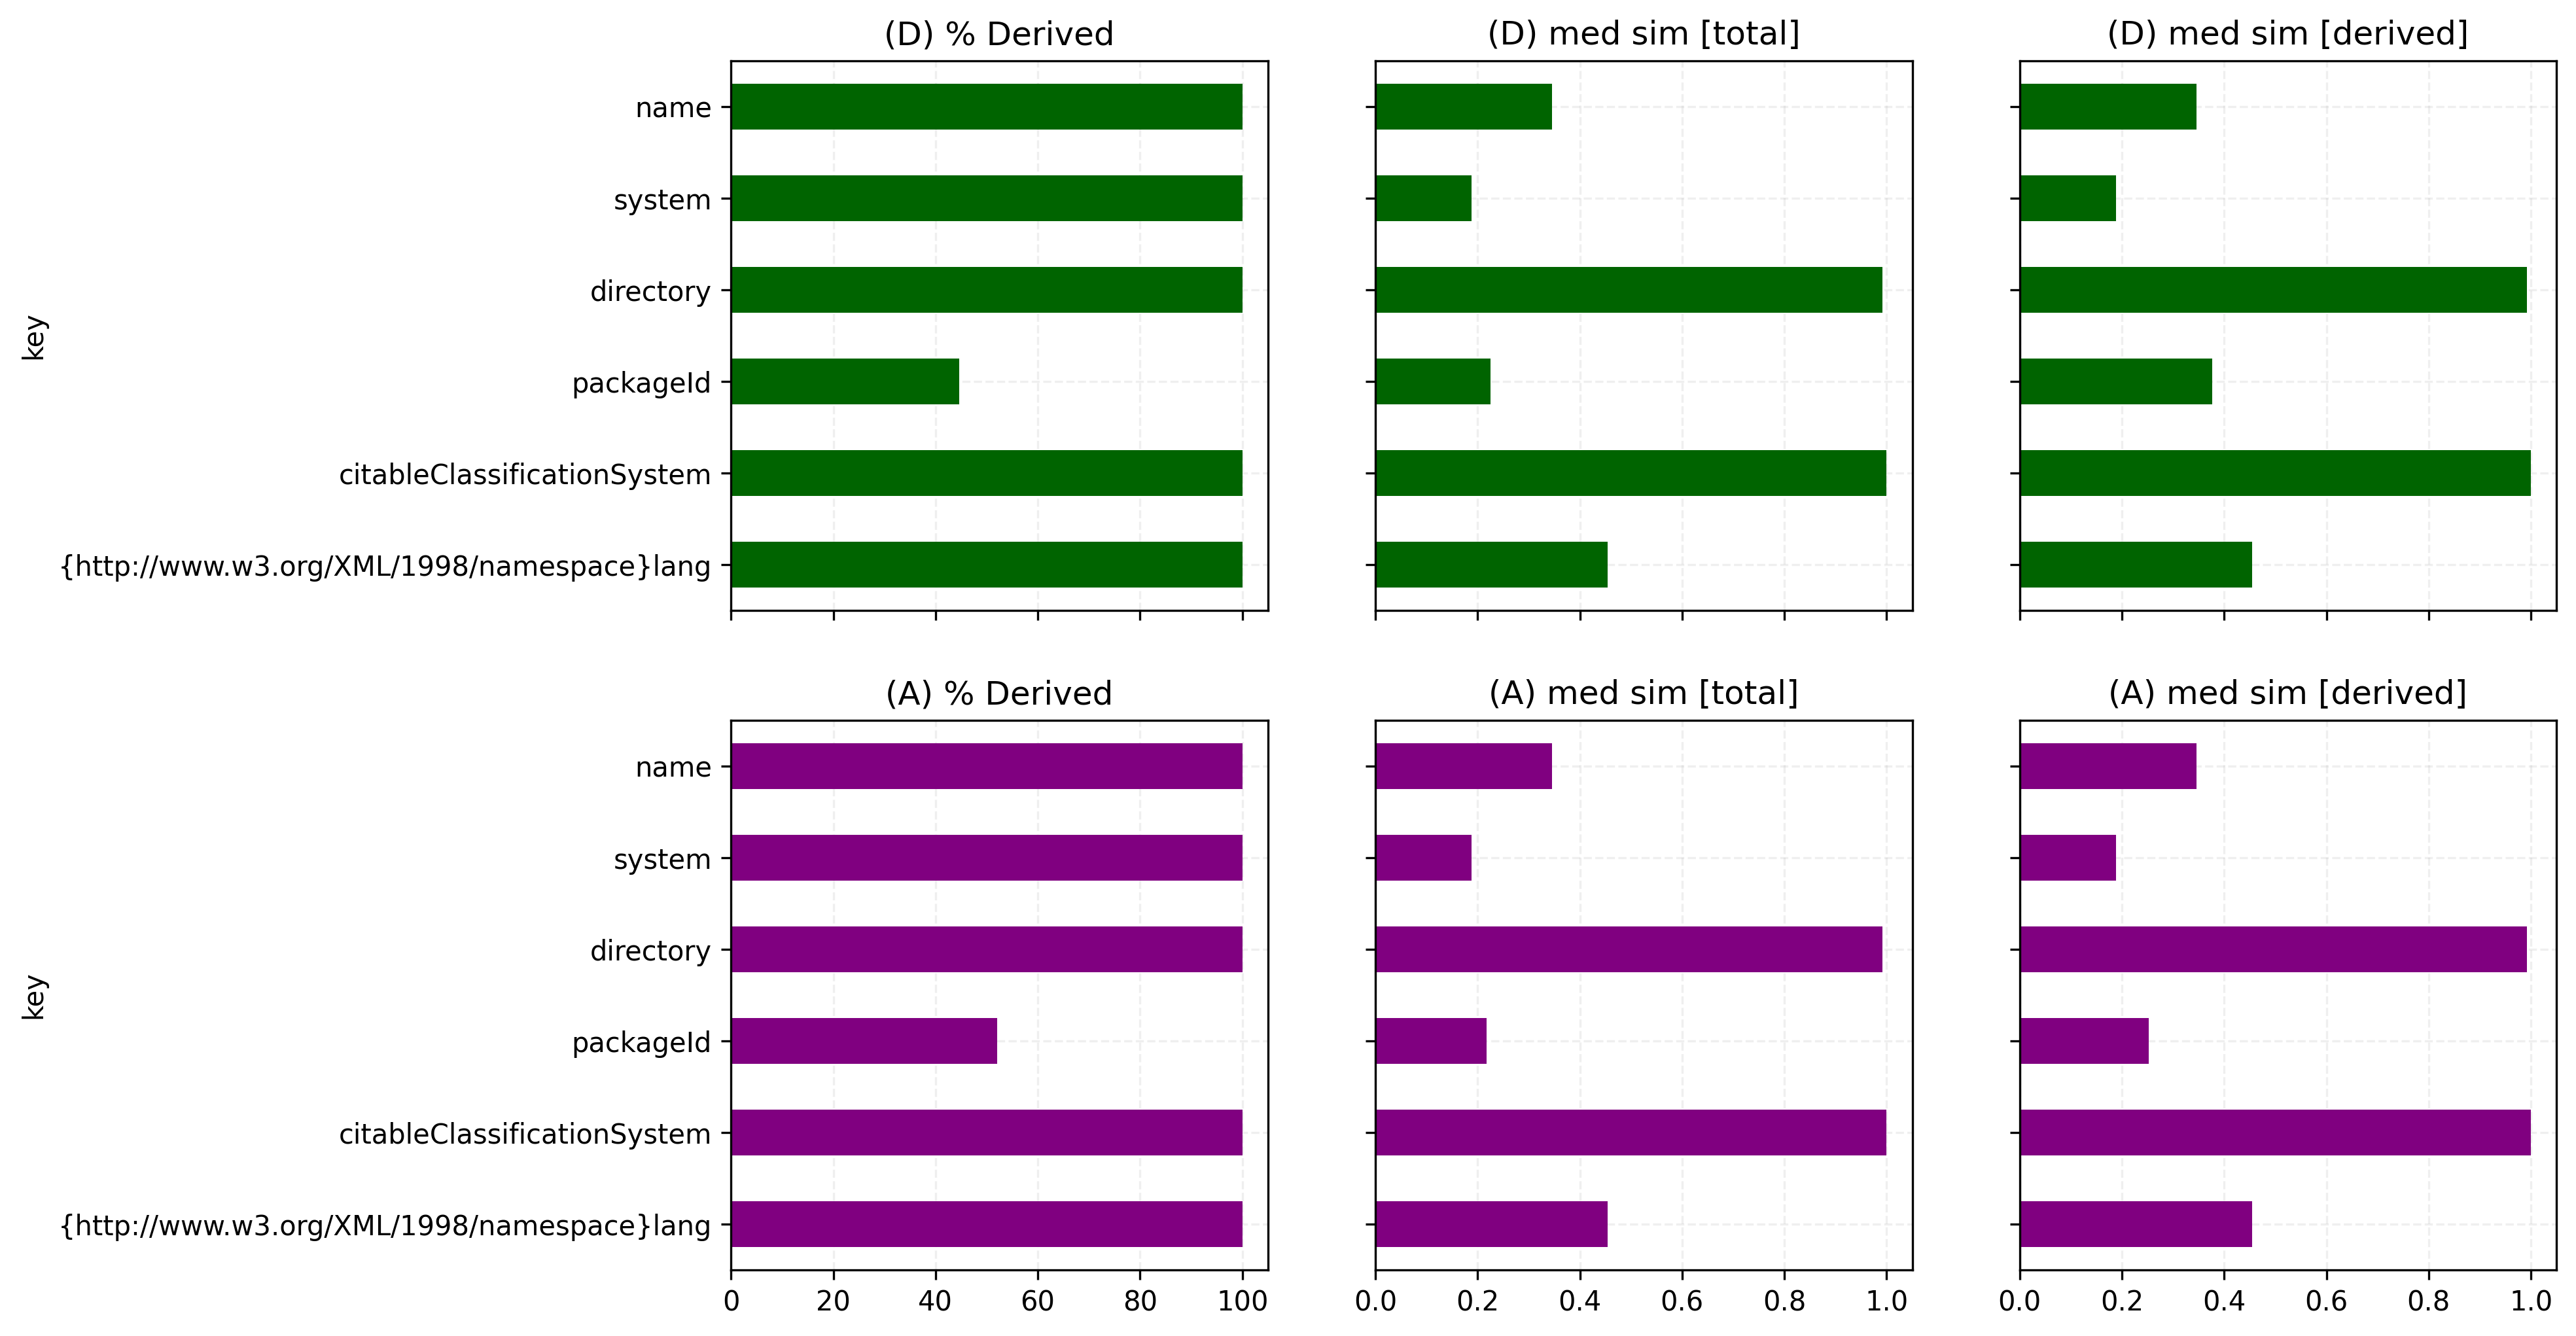

In [542]:
fig, axs = plt.subplots(2,3, figsize=(12, 8), dpi=300, sharey=True, sharex=False)

for ax_t, ax_b in zip(axs[0], axs[1]):
    ax_t.sharex(ax_b)

axs[0][0].set_title("(D) % Derived")
axs[0][1].set_title("(D) med sim [total]")
axs[0][2].set_title("(D) med sim [derived]")
eml_attribute_sim_overview_df.plot.barh(x="key", y="percentage_derived_data", ax=axs[0][0], legend=False, color="darkgreen")
eml_attribute_sim_overview_df.plot.barh(x="key", y="ds_med_cont_data_gt_tot", ax=axs[0][1], legend=False, color="darkgreen")
eml_attribute_sim_overview_df.plot.barh(x="key", y="ds_med_cont_data_gt_der", ax=axs[0][2], legend=False, color="darkgreen")

axs[1][0].set_title("(A) % Derived")
axs[1][1].set_title("(A) med sim [total]")
axs[1][2].set_title("(A) med sim [derived]")
eml_attribute_sim_overview_df.plot.barh(x="key", y="percentage_derived_author", ax=axs[1][0], legend=False, color="purple")
eml_attribute_sim_overview_df.plot.barh(x="key", y="ds_med_cont_author_gt_tot", ax=axs[1][1], legend=False, color="purple")
eml_attribute_sim_overview_df.plot.barh(x="key", y="ds_med_cont_author_gt_der", ax=axs[1][2], legend=False, color="purple")

for ax in [*axs[0], *axs[1]]:
    ax.grid(alpha=0.2, ls="--")
    ax.set_axisbelow(True)

plt.show()

In [494]:
%%sql
-- inspect the attributes by key: `name` (A)
-- ==> consistently different value, "habitat_type" | "study_area" (c) vs "generic" (gt)
SELECT gt_value, author_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'name'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,author_value,cnt
0,"""generic""","""study_area""",2
1,"""generic""","""habitat_type""",9


In [495]:
%%sql
-- inspect the attributes by key: `name` (D)
-- ==> consistently different value, "habitat_type" (c) vs "generic" (gt)
SELECT gt_value, data_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'name'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,data_value,cnt
0,"""generic""","""study_area""",1
1,"""generic""","""habitat_type""",10


In [497]:
%%sql
-- inspect the attributes by key: `system` (A)
-- ==> consistently different value, "knb" (c) vs "GBIF", etc... (gt)
SELECT gt_value, author_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'system'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,author_value,cnt
0,"""http://gbif.org""","""GBIF/registry-style identifier""",1
1,"""http://gbif.org""","""knb""",143
2,"""https://plutof.ut.ee""","""knb""",1
3,"""knb""","""knb""",1
4,"""ALA-Registry""","""knb""",2


In [498]:
%%sql
-- inspect the attributes by key: `system` (A)
-- ==> consistently different value, "knb" (c) vs "GBIF", etc... (gt)
SELECT gt_value, data_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'system'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,data_value,cnt
0,"""http://gbif.org""","""knb""",146
1,"""https://plutof.ut.ee""","""knb""",1
2,"""http://gbif.org""","""uuid""",1
3,"""ALA-Registry""","""knb""",2


In [508]:
%%sql
-- inspect the attributes by key: `directory` (A)
-- ==> consistently same value
SELECT gt_value, author_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'directory'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,author_value,cnt
0,"""https://orcid.org/""","""https://orcid.org""",12
1,"""http://scholar.google.com/citations?user=""","""https://orcid.org""",1
2,"""http://orcid.org/""","""https://orcid.org""",4


In [509]:
%%sql
-- inspect the attributes by key: `directory` (D)
-- ==> consistently same value
SELECT gt_value, data_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'directory'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,data_value,cnt
0,"""https://orcid.org/""","""https://orcid.org""",14
1,"""http://scholar.google.com/citations?user=""","""https://orcid.org""",1
2,"""http://orcid.org/""","""https://orcid.org""",4


In [515]:
%%sql
-- inspect the attributes by key: `packageId` (A)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT gt_value, author_value, cos_sim_author_gt_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'packageId'
GROUP BY 1,2,3
ORDER BY cos_sim_author_gt_value DESC
;

Running query in 'duckdb'

,gt_value,author_value,cos_sim_author_gt_value,cnt
0,"""2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2""","""2265c6e2-4ab7-4af2-93af-ba377a7d4e43""",0.938984,1
1,"""4e1e783d-421c-404e-aa95-803235c8fe16/v1.8""","""urn:uuid:4e1e783d-421c-404e-aa95-803235c8fe16""",0.596676,1
2,"""2615342d-7349-4e75-ae34-cda6cb403e2e/v1.8""","""https://www.gbif.org/dataset/2615342d-7349-4e75-ae34-cda6cb403e2e""",0.556514,1
3,"""48a18d17-96f2-4a0d-89ad-bbe1ac6ce72c/v1.7""","""urn:uuid:8f3d6d5a-1f8c-4d6d-9f5c-3a7b4d2e6c11""",0.523665,1
4,"""9962b976-7eab-452f-acd5-3f772cc0ab25/v1.19""","""urn:uuid:091-36c2704e-7ce9-3ce5-9d16-6b3f2f439792""",0.508438,1
...,...,...,...,...
142,"""https://ipt.fiocruz.br/ipt/resource?id=fiocruz_cmioc/v1.59""","""not-derived-000""",0.098469,1
143,"""http://ipt.gbif.pt/ipt/resource?id=bala_arthropods/v1.0""","""not-derived-000""",0.097711,1
144,"""""","""not-derived-000""",0.095736,1
145,"""https://ipt.my.lifewatch.eu/resource?id=amoladeras/v2.4""","""not-derived-000""",0.058090,1


In [518]:
%%sql
-- inspect the attributes by key: `packageId` (A)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT gt_value, data_value, cos_sim_data_gt_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'packageId'
GROUP BY 1,2,3
ORDER BY cos_sim_data_gt_value DESC
;

Running query in 'duckdb'

,gt_value,data_value,cos_sim_data_gt_value,cnt
0,"""https://ipt.fiocruz.br/ipt/resource?id=fiocruz_colfleb/v1.59""","""Fiocruz:COLFLEB:10.1A""",0.641540,1
1,"""918d7d69-1626-4980-9f6a-74d04da30fde/v1.7""","""urn:uuid:3f2b1a6e-2f5c-4c7d-9b4e-8d6e9f4c1a27""",0.574564,1
2,"""a99cf6c0-4eb2-476b-8414-a513f0925d86/v1.14""","""uuid:urn:uuid:6f1c9f2e-7f9d-4d3a-bf0a-1d4f2f4f9b2c""",0.544928,1
3,"""6ce307d0-0456-4b74-b647-db0ace930b26/v1.8""","""urn:uuid:df134943-1389-4a35-bc70-d5490e02e3d0""",0.532808,1
4,"""6ef6360c-c904-4eab-87fe-7bd234cb5c42/v1.5""","""urn:uuid:6d4c6f39-5b5a-4a8e-9a2f-8cc03df4df6a""",0.521538,1
...,...,...,...,...
144,"""http://ipt.gbif.pt/ipt/resource?id=bala_arthropods/v1.0""","""not-derived-000""",0.097711,1
145,"""""","""not-derived-000""",0.095736,1
146,"""757212c8-bfcb-3119-8c1b-e66043354bab/v23""","""https://doi.org/10.1016/j.actatropica.2015.08.016""",0.094127,1
147,"""https://ipt.pensoft.net/resource?id=a-dataset-of-vascular-plant-species-in-parque-estadual-da-serra-da-concordia-rio-de-janeiro-brazil/v1.2""","""uuid-placeholder""",0.075980,1


In [528]:
%%sql
-- inspect the attributes by key: `packageId` (A) (der)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT gt_value, author_value, cos_sim_author_gt_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'packageId'
    AND NOT(contains(author_value, 'not-derived-'))
GROUP BY 1,2,3
ORDER BY 3 DESC
;

Running query in 'duckdb'

,gt_value,author_value,cos_sim_author_gt_value,cnt
0,"""2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2""","""2265c6e2-4ab7-4af2-93af-ba377a7d4e43""",0.938984,1
1,"""4e1e783d-421c-404e-aa95-803235c8fe16/v1.8""","""urn:uuid:4e1e783d-421c-404e-aa95-803235c8fe16""",0.596676,1
2,"""2615342d-7349-4e75-ae34-cda6cb403e2e/v1.8""","""https://www.gbif.org/dataset/2615342d-7349-4e75-ae34-cda6cb403e2e""",0.556514,1
3,"""48a18d17-96f2-4a0d-89ad-bbe1ac6ce72c/v1.7""","""urn:uuid:8f3d6d5a-1f8c-4d6d-9f5c-3a7b4d2e6c11""",0.523665,1
4,"""9962b976-7eab-452f-acd5-3f772cc0ab25/v1.19""","""urn:uuid:091-36c2704e-7ce9-3ce5-9d16-6b3f2f439792""",0.508438,1
...,...,...,...,...
72,"""https://ipt.fiocruz.br/ipt/resource?id=fiocruz_colfleb/v1.59""","""uuid-placeholder""",0.152703,1
73,"""https://ipt.pensoft.net/resource?id=two_new_species_of_boesenbergia_zingiberaceae_from_sabah_malaysia/v1.0""","""10.15468/4c4gag""",0.149342,1
74,"""eml.1.1""","""https://doi.org/10.15468/gvpgea""",0.147626,1
75,"""19982b41-cacd-4393-9474-b34a8a135289/v2.0""","""uuid-placeholder""",0.146428,1


In [529]:
%%sql
-- inspect the attributes by key: `packageId` (A) (der)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT AVG(cos_sim_author_gt_value)
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'packageId'
    AND NOT(contains(author_value, 'not-derived-'))
;

Running query in 'duckdb'

,avg(cos_sim_author_gt_value)
0,0.281078


In [530]:
%%sql
-- inspect the attributes by key: `packageId` (A) (der)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT gt_value, data_value, cos_sim_data_gt_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'packageId'
    AND NOT(contains(data_value, 'not-derived-'))
GROUP BY 1,2,3
ORDER BY 3 DESC
;

Running query in 'duckdb'

,gt_value,data_value,cos_sim_data_gt_value,cnt
0,"""https://ipt.fiocruz.br/ipt/resource?id=fiocruz_colfleb/v1.59""","""Fiocruz:COLFLEB:10.1A""",0.641540,1
1,"""918d7d69-1626-4980-9f6a-74d04da30fde/v1.7""","""urn:uuid:3f2b1a6e-2f5c-4c7d-9b4e-8d6e9f4c1a27""",0.574564,1
2,"""a99cf6c0-4eb2-476b-8414-a513f0925d86/v1.14""","""uuid:urn:uuid:6f1c9f2e-7f9d-4d3a-bf0a-1d4f2f4f9b2c""",0.544928,1
3,"""6ce307d0-0456-4b74-b647-db0ace930b26/v1.8""","""urn:uuid:df134943-1389-4a35-bc70-d5490e02e3d0""",0.532808,1
4,"""6ef6360c-c904-4eab-87fe-7bd234cb5c42/v1.5""","""urn:uuid:6d4c6f39-5b5a-4a8e-9a2f-8cc03df4df6a""",0.521538,1
...,...,...,...,...
62,"""9ee09033-8aab-4813-8c2b-db6d54d9817b/v1.21""","""http://ipt.biodiversity.be/resource.do?r=modirisk-longitudinal-culicidae-study""",0.120057,1
63,"""12704217-bc15-45f9-859f-0bdede407d2b/v1.4""","""Georeferencing Quick Reference Guide""",0.098600,1
64,"""757212c8-bfcb-3119-8c1b-e66043354bab/v23""","""https://doi.org/10.1016/j.actatropica.2015.08.016""",0.094127,1
65,"""https://ipt.pensoft.net/resource?id=a-dataset-of-vascular-plant-species-in-parque-estadual-da-serra-da-concordia-rio-de-janeiro-brazil/v1.2""","""uuid-placeholder""",0.075980,1


In [531]:
%%sql
-- inspect the attributes by key: `packageId` (D) (der)
-- ==> different value, ranging from, at best, wrong formatting but right ID, to wrong IDs and not-derived responses
SELECT AVG(cos_sim_data_gt_value)
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'packageId'
    AND NOT(contains(data_value, 'not-derived-'))
;

Running query in 'duckdb'

,avg(cos_sim_data_gt_value)
0,0.356771


In [532]:
%%sql
-- inspect the attributes by key: `citableClassificationSystem` (A)
-- ==> consistently same value
SELECT gt_value, author_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = 'citableClassificationSystem'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,author_value,cnt
0,"""false""","""false""",11


In [534]:
%%sql
-- inspect the attributes by key: `citableClassificationSystem` (D)
-- ==> consistently same value
SELECT gt_value, data_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = 'citableClassificationSystem'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,data_value,cnt
0,"""false""","""false""",11


In [536]:
%%sql
-- inspect the attributes by key: `citableClassificationSystem` (A)
-- ==> often the same by the "eng" (or "en") but not recognising other languages (with a single success of "spanish")
SELECT gt_value, author_value, COUNT(1) as cnt
FROM shared_author_gt_attributes_eml__value_sim
WHERE key = '{http://www.w3.org/XML/1998/namespace}lang'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,author_value,cnt
0,"""por""","""en""",2
1,"""fre""","""en""",1
2,"""en""","""en""",2
3,"""eng""","""en""",82
4,"""spa""","""es""",1
5,"""spa""","""en""",4


In [538]:
%%sql
-- inspect the attributes by key: `citableClassificationSystem` (D)
-- ==> always reporting "en", often OK because of "eng" ~ "en" similarity
SELECT gt_value, data_value, COUNT(1) as cnt
FROM shared_data_gt_attributes_eml__value_sim
WHERE key = '{http://www.w3.org/XML/1998/namespace}lang'
GROUP BY 1,2
;

Running query in 'duckdb'

,gt_value,data_value,cnt
0,"""por""","""en""",3
1,"""fre""","""en""",1
2,"""en""","""en""",1
3,"""spa""","""en""",3
4,"""eng""","""en""",78


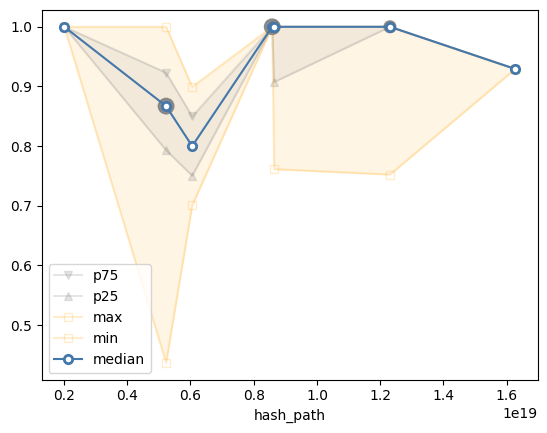

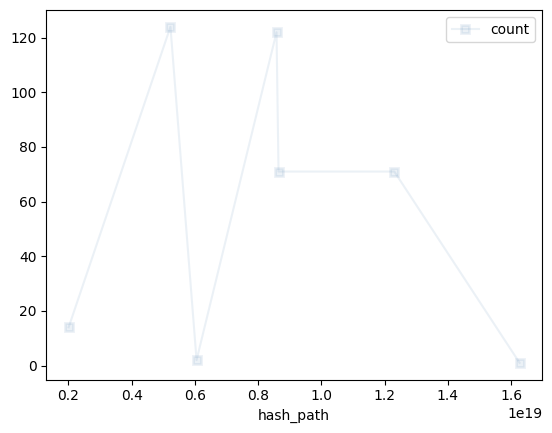

In [478]:
# consistency between the attribute values

df = shared_data_author_eml_nodes__sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.scatter(df.index, df['ds_med_cont'], sizes=(df['ds_count']), color="gray", alpha=0.9)
plt.legend(loc="lower left")
plt.show()
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, label="count", legend=True)
plt.show()

In [481]:
shared_data_author_eml_nodes__sim_attributes__path_inspect.nsmallest(10, columns=["ds_med_cont"])

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
6053456406947778033,dataset/project/studyAreaDescription/descriptor[3],2,2,0.099219,0.799988,0.899207,0.700769,0.799988,0.750378,0.849597
5227831486160219788,.,124,124,0.100370,0.854348,1.000000,0.436732,0.867016,0.793100,0.923025
16270227087059927836,additionalMetadata,1,1,0.000000,0.929274,0.929274,0.929274,0.929274,0.929274,0.929274
2007448060941507434,dataset/project/studyAreaDescription/descriptor,14,14,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8583186042160731940,dataset/creator/userId,122,122,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
8646466898135044654,dataset/project/studyAreaDescription/descriptor[2],71,71,0.078912,0.950725,1.000000,0.761374,1.000000,0.907518,1.000000
12309451528792936862,dataset/project/studyAreaDescription/descriptor[1],71,71,0.075603,0.968155,1.000000,0.752345,1.000000,1.000000,1.000000


### Exploration

#### DwC-T

In [148]:
%%sql
SELECT d.path, case_id, cos_sim_text, data_text, author_text
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE cos_sim_text < 1
ORDER BY cos_sim_text ASC, case_id ASC
;

Running query in 'duckdb'

,path,case_id,cos_sim_text,data_text,author_text
0,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,130,0.419757,measurementorfact.txt,occurrence.txt
1,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,130,0.419757,occurrence.txt,measurementorfact.txt
2,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,0.480255,event.txt,measurementorfacts.txt
3,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,152,0.480255,event.txt,measurementorfacts.txt
4,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,152,0.480255,measurementorfacts.txt,event.txt
5,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,0.483202,extendedmeasurementorfact.txt,event.txt
6,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,116,0.483202,event.txt,extendedmeasurementorfact.txt
7,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,116,0.483202,extendedmeasurementorfact.txt,event.txt
8,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,159,0.483202,event.txt,extendedmeasurementorfact.txt
9,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,159,0.483202,extendedmeasurementorfact.txt,event.txt


In [149]:
%%sql
SELECT d.path, case_id, cos_sim_attributes, data_attributes, author_attributes
FROM shared_data_author_dwc_t_nodes__sim_attributes AS d
WHERE cos_sim_attributes < 1
ORDER BY cos_sim_attributes ASC, case_id ASC
;

Running query in 'duckdb'

,path,case_id,cos_sim_attributes,data_attributes,author_attributes
0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[8],92,0.428500,"{""index"": ""8"", ""term"": ""Classification classify-sklearn (QIIME feature-classifier classify-sklearn) on a classifier that was trained using the naive Bayes classifier algorithm (QIIME feature-classifier fit-classifier-naive-bayes)""}","{""index"": ""8"", ""term"": ""not-derived-009""}"
1,.,46,0.445228,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 1994""}","{""metadata"": ""omit or leave empty""}"
2,.,104,0.532437,"{""metadata"": ""meta.xml""}","{""metadata"": ""not-derived-001` is unavailable. The interview confirmed that no separate metadata file or URI/path such as `meta.xml`, `eml.xml`, or `metadata.xml` was identified in the provided material.'}}}""}"
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],92,0.541082,"{""index"": ""4"", ""term"": ""http://example.org/molecular-assay/target-gene/ITS""}","{""index"": ""4"", ""term"": ""not-derived-005""}"
4,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[17],103,0.558338,"{""index"": ""17"", ""term"": ""http://rs.tdwg.org/dwc/terms/scientificNameAuthorship""}","{""index"": ""16"", ""term"": ""http://rs.tdwg.org/dwc/terms/decimalLatitude""}"
...,...,...,...,...,...
1377,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[12],65,0.994138,"{""index"": ""12"", ""term"": ""http://rs.tdwg.org/dwc/terms/locality""}","{""index"": ""11"", ""term"": ""http://rs.tdwg.org/dwc/terms/locality""}"
1378,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10],65,0.994559,"{""index"": ""10"", ""term"": ""http://rs.tdwg.org/dwc/terms/countryCode""}","{""index"": ""9"", ""term"": ""http://rs.tdwg.org/dwc/terms/countryCode""}"
1379,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[11],65,0.995531,"{""index"": ""11"", ""term"": ""http://rs.tdwg.org/dwc/terms/municipality""}","{""index"": ""10"", ""term"": ""http://rs.tdwg.org/dwc/terms/municipality""}"
1380,{http://rs.tdwg.org/dwc/text/}core,151,0.999148,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence"", ""fieldsTerminatedBy"": ""&#x9;"", ""fieldsEnclosedBy"": ""&quot;"", ""ignoreHeaderLines"": ""1"", ""encoding"": ""UTF-8""}","{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occurrence"", ""fieldsTerminatedBy"": ""&#9;"", ""fieldsEnclosedBy"": ""&quot;"", ""ignoreHeaderLines"": ""1"", ""encoding"": ""UTF-8""}"


In [150]:
%%sql
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, dja.key, dja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.data_attributes) AS dja
);
CREATE TABLE IF NOT EXISTS shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS (
SELECT d.path, d.case_id, d.cos_sim_attributes, aja.key, aja.value
FROM 
    shared_data_author_dwc_t_nodes__sim_attributes AS d,
    json_each(d.author_attributes) AS aja
);

Running query in 'duckdb'

,Count


In [151]:
%%sql
SELECT d.path, d.case_id, d.data_text, d.author_text, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,2,3,4
ORDER BY d.case_id, cnt

Running query in 'duckdb'

,path,case_id,data_text,author_text,cnt
0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,occurrence.txt,event.txt,1
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,event.txt,occurrence.txt,1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,event.txt,occurrence.txt,1
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,occurrence.txt,event.txt,1
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,event.txt,occurrence.txt,1
5,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,occurrence.txt,event.txt,1
6,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,extendedmeasurementorfact.txt,event.txt,1
7,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,event.txt,measurementorfacts.txt,1
8,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,measurementorfacts.txt,extendedmeasurementorfact.txt,1
9,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,43,event.txt,occurrence.txt,1


In [152]:
%%sql
SELECT d.path, d.case_id, d.data_text, d.author_text, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,2,3,4
ORDER BY d.case_id, cnt

Running query in 'duckdb'

,path,case_id,data_text,author_text,cnt
0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,occurrence.txt,event.txt,1
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,5,event.txt,occurrence.txt,1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,event.txt,occurrence.txt,1
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,18,occurrence.txt,event.txt,1
4,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,occurrence.txt,event.txt,1
5,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,25,event.txt,occurrence.txt,1
6,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,extendedmeasurementorfact.txt,event.txt,1
7,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,event.txt,measurementorfacts.txt,1
8,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,42,measurementorfacts.txt,extendedmeasurementorfact.txt,1
9,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,43,event.txt,occurrence.txt,1


In [153]:
%%sql dwc_t_cases_with_text_value_mismatch <<
SELECT d.case_id, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_text AS d
WHERE d.data_text <> d.author_text
GROUP BY 1,
ORDER BY d.case_id, cnt

Running query in 'duckdb'

In [154]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    -- gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    -- d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
-- GROUP BY 1,2,3
-- ORDER BY 4

Running query in 'duckdb'

,cnt
0,258


In [155]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text = d.author_text
    AND d.data_text = gt.text
    AND d.author_text = gt.text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,data_ok,author_ok,data_equal_author,cnt
0,True,True,True,175


In [156]:
%%sql
SELECT d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, gt_text = d.data_text as data_ok, gt_text = d.author_text as author_ok
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text
ORDER BY d.case_id

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok
0,0,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,occurrence.txt,False,False
1,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
3,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,event.txt,occurrence.txt,False,False
4,3,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,occurrence.txt,event.txt,False,False
...,...,...,...,...,...,...,...
78,170,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,multimedia.txt,multimedia.txt,permit.txt,False,False
79,173,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True
80,173,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True
81,174,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False


In [157]:
%%sql
SELECT 
    -- d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text
GROUP BY 1,2,3
ORDER BY 4

Running query in 'duckdb'

,data_ok,author_ok,data_equal_author,cnt
0,False,False,False,7
1,False,True,False,10
2,True,False,False,22
3,False,False,True,44


In [158]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND data_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,103,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
1,103,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False
2,116,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,extendedmeasurementorfact.txt,True,False,False
3,118,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
4,118,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False
5,124,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,dna_data.csv,media.csv,dna_data.csv,True,False,False
6,152,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,measurementorfacts.txt,event.txt,measurementorfacts.txt,True,False,False
7,159,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,extendedmeasurementorfact.txt,True,False,False
8,164,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,event.txt,True,False,False
9,164,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,occurrence.txt,True,False,False


In [159]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND author_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,130,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,measurementorfact.txt,occurrence.txt,occurrence.txt,False,True,False
1,130,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,measurementorfact.txt,measurementorfact.txt,False,True,False
2,173,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
3,173,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
4,43,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
5,43,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
6,45,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
7,45,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False
8,86,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,event.txt,False,True,False
9,86,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,occurrence.txt,occurrence.txt,False,True,False


In [160]:
%%sql
SELECT 
    d.case_id, d.path, d.data_text, d.author_text, gt.text as gt_text, 
    gt.text = d.data_text as data_ok, gt.text = d.author_text as author_ok,
    d.data_text = d.author_text as data_equal_author,
    -- COUNT(1) as cnt
    
FROM shared_data_author_dwc_t_nodes__sim_text AS d
LEFT JOIN gt_dwc_t_data_nodes AS gt
    ON d.path = gt.path
    AND d.case_id = gt.case_id
WHERE 
    (d.data_text <> d.author_text
    OR d.data_text <> gt.text
    OR d.author_text <> gt.text)
AND NOT data_equal_author
AND NOT data_ok
AND NOT author_ok
;

Running query in 'duckdb'

,case_id,path,data_text,author_text,gt_text,data_ok,author_ok,data_equal_author
0,116,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,extendedmeasurementorfact.txt,occurrence.txt,False,False,False
1,124,{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,media.csv,dna_data.csv,measurements.csv,False,False,False
2,152,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,measurementorfacts.txt,occurrence.txt,False,False,False
3,159,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,extendedmeasurementorfact.txt,occurrence.txt,False,False,False
4,42,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,event.txt,measurementorfacts.txt,extendedmeasurementorfact.txt,False,False,False
5,42,{http://rs.tdwg.org/dwc/text/}extension[3]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,extendedmeasurementorfact.txt,event.txt,occurrence.txt,False,False,False
6,78,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}files/{http://rs.tdwg.org/dwc/text/}location,occurrence.txt,event.txt,measurementorfacts.txt,False,False,False


In [161]:
%%sql
SELECT aja.path, aja.case_id, aja.key, aja.value AS author_value, dja.value AS data_value, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
GROUP BY 1,2,3,4,5 
ORDER BY aja.case_id, cnt
;

Running query in 'duckdb'

,path,case_id,key,author_value,data_value,cnt
0,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[6],2,term,"""http://rs.tdwg.org/dwc/terms/collectionCode""","""http://rs.tdwg.org/dwc/terms/institutionCode""",1
1,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],2,index,"""2""","""1""",1
2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],2,index,"""3""","""2""",1
3,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid,2,index,"""0""","""3""",1
4,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],2,term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type""",1
...,...,...,...,...,...,...
1693,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[17],174,term,"""http://rs.tdwg.org/dwc/terms/order""","""http://rs.tdwg.org/dwc/terms/locationRemarks""",1
1694,.,175,metadata,"""not-derived-001""","""meta.xml""",1
1695,.,177,metadata,"""not-derived-001""","""meta.xml""",1
1696,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],178,term,"""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language""",1


In [162]:
%%sql dwc_t_cases_with_attribute_value_mismatch <<
SELECT aja.case_id, COUNT(1) as cnt
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
GROUP BY 1
ORDER BY aja.case_id, cnt
;

Running query in 'duckdb'

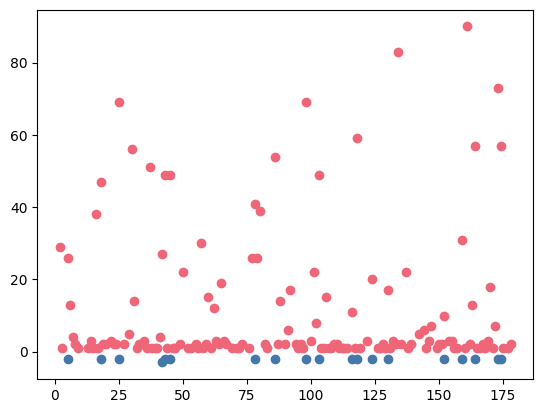

In [163]:
plt.scatter(
    dwc_t_cases_with_text_value_mismatch["case_id"],
    dwc_t_cases_with_text_value_mismatch["cnt"] * (-1)
)
plt.scatter(
    dwc_t_cases_with_attribute_value_mismatch["case_id"], 
    dwc_t_cases_with_attribute_value_mismatch["cnt"]
)

<Axes: ylabel='Frequency'>

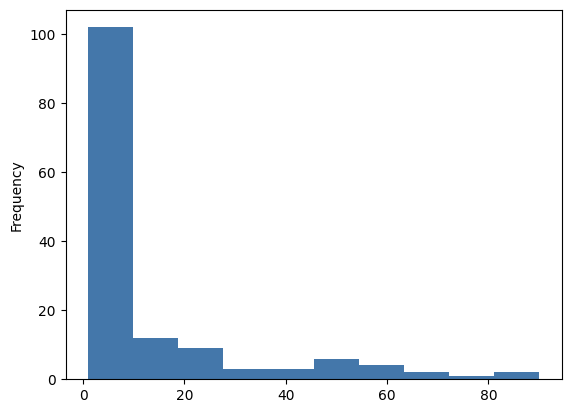

In [164]:
dwc_t_cases_with_attribute_value_mismatch["cnt"].plot.hist()

In [165]:
dwc_t_cases_with_attribute_value_mismatch.nlargest(15, columns=["cnt"])

,case_id,cnt
127,161,90
107,134,83
139,173,73
18,25,69
77,98,69
95,118,59
130,164,57
140,174,57
21,30,56
67,86,54


In [166]:
set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist())

{5,
 18,
 25,
 42,
 43,
 45,
 78,
 86,
 98,
 103,
 116,
 118,
 124,
 130,
 152,
 159,
 164,
 173,
 174}

In [167]:
set(dwc_t_cases_with_attribute_value_mismatch.nlargest(15, columns=["cnt"])["case_id"].tolist())

{18, 25, 30, 37, 43, 45, 86, 98, 103, 118, 134, 161, 164, 173, 174}

In [168]:
(
    set.difference(
        set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist()),
        set(dwc_t_cases_with_attribute_value_mismatch.nlargest(50, columns=["cnt"])["case_id"].tolist()),
    ),
    
    set.difference(
        set(dwc_t_cases_with_attribute_value_mismatch.nlargest(50, columns=["cnt"])["case_id"].tolist()),
        set(dwc_t_cases_with_text_value_mismatch["case_id"].tolist()),
    )
)

(set(),
 {2,
  6,
  7,
  16,
  29,
  30,
  31,
  37,
  50,
  57,
  60,
  62,
  65,
  77,
  79,
  80,
  88,
  91,
  92,
  101,
  102,
  106,
  134,
  137,
  142,
  144,
  147,
  161,
  163,
  170,
  172})

In [169]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP')
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,.,metadata,"""not-derived-001""","""meta.xml"""
1,3,.,metadata,"""not-derived-001""","""meta.xml"""
2,8,.,metadata,"""not-derived-001""","""meta.xml"""
3,9,.,metadata,"""not-derived-001""","""meta.xml"""
4,13,.,metadata,"""not-derived-001""","""meta.xml"""
...,...,...,...,...,...
110,171,.,metadata,"""not-derived-001""","""meta.xml"""
111,173,.,metadata,"""not-derived-001""","""meta.xml"""
112,174,.,metadata,"""not-derived-001""","""GAP_001"""
113,175,.,metadata,"""not-derived-001""","""meta.xml"""


In [170]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP')
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,19,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""not-derived-002"""
1,19,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/type""","""not-derived-003"""
2,42,.,metadata,"""meta.xml""","""not-derived-001"""
3,56,.,metadata,"""meta.xml""","""not-derived-001"""
4,57,.,metadata,"""meta.xml""","""not-derived-001"""
5,64,.,metadata,"""meta.xml""","""not-derived-001"""
6,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""not-derived-004""","""not-derived-003"""
7,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[7],term,"""not-derived-008""","""not-derived-007"""
8,92,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10],term,"""not-derived-011""","""not-derived-010"""
9,106,{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/permitType""","""not-derived-002"""


In [171]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value as author_value, dja.value as data_value
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
ORDER BY aja.case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/datasetName""","""http://rs.tdwg.org/dwc/terms/type"""
1,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/eventID""","""http://rs.tdwg.org/dwc/terms/datasetName"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],index,"""1""","""0"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],index,"""2""","""1"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],index,"""3""","""2"""
...,...,...,...,...,...
1560,174,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],index,"""6""","""5"""
1561,174,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""
1562,174,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence"""
1563,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified"""


In [172]:
%%sql
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
GROUP BY 1
ORDER BY aja.key, cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,fieldsTerminatedBy,21
2,index,271
3,metadata,6
4,rowType,17
5,term,460


In [173]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language"""
1,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
2,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}id,index,"""0""","""10"""
3,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id"""
4,101,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type"""
...,...,...,...,...,...
772,91,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[1],index,"""0""","""1"""
773,66,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
774,94,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""&#9;""","""\\t"""
775,82,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""


In [174]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND str_split(aja.value, '/')[-1] == str_split(dja.value, '/')[-1]
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/language""","""http://purl.org/dc/terms/language"""
1,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
2,102,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://purl.org/dc/terms/language""","""http://rs.tdwg.org/dwc/terms/language"""
3,102,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://purl.org/dc/terms/format""","""http://rs.tdwg.org/dwc/terms/format"""
4,102,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://purl.org/dc/terms/identifier""","""http://rs.tdwg.org/dwc/terms/identifier"""
...,...,...,...,...,...
110,90,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://purl.org/dc/terms/license""","""http://rs.tdwg.org/dwc/terms/license"""
111,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[10],term,"""http://rs.tdwg.org/dwc/terms/recordedBy""","""http://purl.org/dc/terms/recordedBy"""
112,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[17],term,"""http://rs.tdwg.org/dwc/terms/identifiedBy""","""http://purl.org/dc/terms/identifiedBy"""
113,91,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[18],term,"""http://rs.tdwg.org/dwc/terms/dateIdentified""","""http://purl.org/dc/terms/dateIdentified"""


In [175]:
%%sql
SELECT aja.key, COUNT(1) AS cnt 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND NOT (str_split(aja.value, '/')[-1] == str_split(dja.value, '/')[-1])
GROUP BY 1
ORDER BY aja.key, cnt
;

Running query in 'duckdb'

,key,cnt
0,delimitedBy,2
1,fieldsTerminatedBy,21
2,index,271
3,metadata,6
4,rowType,17
5,term,345


In [176]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'delimitedBy' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[11],delimitedBy,""" | ""","""|"""
1,59,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25],delimitedBy,""" | ""","""|"""


In [177]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'fieldsTerminatedBy' 
    AND NOT (aja.value IN ('"\\t"', '"&#x9;"', '"&#9;"') AND dja.value IN ('"\\t"', '"&#x9;"', '"&#9;"'))
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,110,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
1,128,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
2,146,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,""" ""","""\\t"""
3,146,{http://rs.tdwg.org/dwc/text/}extension,fieldsTerminatedBy,""" ""","""\\t"""
4,14,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
5,14,{http://rs.tdwg.org/dwc/text/}extension,fieldsTerminatedBy,"""\\t""",""" """
6,162,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""","""
7,29,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
8,32,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """
9,61,{http://rs.tdwg.org/dwc/text/}core,fieldsTerminatedBy,"""\\t""",""" """


In [178]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'metadata' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,113,.,metadata,"""omit the metadata attribute""","""meta.xml"""
1,147,.,metadata,"""https://doi.org/10.15468/gwr8mg""","""meta.xml"""
2,20,.,metadata,"""omit the metadata attribute""","""1"""
3,23,.,metadata,"""omit the `metadata` attribute""","""meta.xml"""
4,34,.,metadata,"""https://www.gbif.org/dataset/e9aeed17-b33f-4af2-8471-9be87633d7e1""","""meta.xml"""
5,46,.,metadata,"""omit or leave empty""","""Ascorhynchus hippos Turpaeva, 1994"""


In [179]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'rowType' 
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,102,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Multimedia"""
1,106,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""
2,106,{http://rs.tdwg.org/dwc/text/}extension[1],rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/MeasurementOrFact"""
3,106,{http://rs.tdwg.org/dwc/text/}extension[2],rowType,"""http://rs.tdwg.org/dwc/terms/DigitalMedia""","""http://rs.tdwg.org/dwc/terms/Media"""
4,163,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Multimedia"""
5,170,{http://rs.tdwg.org/dwc/text/}extension[1],rowType,"""http://rs.tdwg.org/dwc/terms/ResourceRelationship""","""http://rs.tdwg.org/dwc/terms/Permit"""
6,170,{http://rs.tdwg.org/dwc/text/}extension[2],rowType,"""http://rs.tdwg.org/dwc/terms/RelatedResource""","""http://rs.tdwg.org/dwc/terms/MaterialCitation"""
7,172,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.tdwg.org/dwc/terms/Multimedia""","""http://rs.tdwg.org/dwc/terms/Media"""
8,6,{http://rs.tdwg.org/dwc/text/}extension,rowType,"""http://rs.gbif.org/dwc/terms/DNADerivedData""","""http://rs.tdwg.org/dwc/terms/MaterialSample"""
9,24,{http://rs.tdwg.org/dwc/text/}core,rowType,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event"""


In [180]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'index' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid,index,"""0""","""3"""
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],index,"""1""","""0"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],index,"""2""","""1"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],index,"""3""","""2"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],index,"""4""","""3"""
...,...,...,...,...,...
266,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[41],index,"""50""","""41"""
267,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[42],index,"""51""","""42"""
268,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[43],index,"""52""","""43"""
269,161,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[44],index,"""53""","""44"""


In [181]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value 
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'term' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value
0,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id"""
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type"""
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/institutionID""","""http://rs.tdwg.org/dwc/terms/license"""
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/collectionID""","""http://rs.tdwg.org/dwc/terms/institutionID"""
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/institutionCode""","""http://rs.tdwg.org/dwc/terms/collectionID"""
...,...,...,...,...,...
455,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/description""","""http://purl.org/dc/terms/description"""
456,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/creator""","""http://purl.org/dc/terms/creator"""
457,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license"""
458,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified"""


In [182]:
%%sql
SELECT aja.case_id, aja.path, aja.key, aja.value  AS author_value, dja.value AS data_value, gt_dwc.attributes
FROM shared_data_author_dwc_t_nodes__sim_attributes__data_unpacked AS dja
JOIN shared_data_author_dwc_t_nodes__sim_attributes__author_unpacked AS aja 
    ON  aja.path = dja.path
    AND aja.case_id = dja.case_id
    AND aja.key = dja.key
LEFT JOIN gt_dwc_t_data_nodes as gt_dwc
    ON aja.case_id = gt_dwc.case_id
    AND aja.path = gt_dwc.path
WHERE aja.value <> dja.value
    AND NOT (contains(aja.value, 'not-derived') OR contains(aja.value, 'GAP'))
    AND NOT (contains(dja.value, 'not-derived') OR contains(dja.value, 'GAP'))
    AND aja.case_id NOT IN (
        SELECT DISTINCT d.case_id
        FROM shared_data_author_dwc_t_nodes__sim_text AS d
        WHERE d.data_text <> d.author_text
    )
    AND aja.key = 'term' 
ORDER BY case_id
;

Running query in 'duckdb'

,case_id,path,key,author_value,data_value,attributes
0,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],term,"""http://rs.tdwg.org/dwc/terms/type""","""http://rs.tdwg.org/dwc/terms/id""","{""index"": ""1"", ""term"": ""http://purl.org/dc/elements/1.1/type""}"
1,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://rs.tdwg.org/dwc/terms/type""","{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc/terms/datasetName""}"
2,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],term,"""http://rs.tdwg.org/dwc/terms/institutionID""","""http://rs.tdwg.org/dwc/terms/license""","{""index"": ""3"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventID""}"
3,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/collectionID""","""http://rs.tdwg.org/dwc/terms/institutionID""","{""index"": ""4"", ""term"": ""http://rs.tdwg.org/dwc/terms/eventDate""}"
4,2,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/institutionCode""","""http://rs.tdwg.org/dwc/terms/collectionID""","{""index"": ""5"", ""term"": ""http://rs.tdwg.org/dwc/terms/year""}"
...,...,...,...,...,...,...
455,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[4],term,"""http://rs.tdwg.org/dwc/terms/description""","""http://purl.org/dc/terms/description""","{""index"": ""4"", ""term"": ""http://purl.org/dc/terms/description""}"
456,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[5],term,"""http://rs.tdwg.org/dwc/terms/creator""","""http://purl.org/dc/terms/creator""","{""index"": ""5"", ""term"": ""http://purl.org/dc/terms/creator""}"
457,172,{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[6],term,"""http://rs.tdwg.org/dwc/terms/license""","""http://purl.org/dc/terms/license""","{""index"": ""6"", ""term"": ""http://purl.org/dc/terms/license""}"
458,178,{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],term,"""http://rs.tdwg.org/dwc/terms/modified""","""http://purl.org/dc/terms/modified""","{""index"": ""2"", ""term"": ""http://purl.org/dc/terms/modified""}"
